### Q2: Image Colourization using CNNs

Implements a convolutional encoder-decoder network for image colourization 
on CIFAR-10 dataset. The task converts grayscale images to color by predicting one of 24 
color clusters for each pixel using cross-entropy loss.


In [ ]:
"""
Key Components:
- Encoder: 3 Conv layers with progressive downsampling (32→16→8→4)
- Decoder: 3 ConvTranspose layers with learned upsampling (4→8→16→32)
- Classification: Per-pixel classification into 24 color clusters
"""

import os
import math
import copy
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import pandas as pd

print("All imports loaded successfully")


All imports loaded successfully


#### CONFIGURATION AND SETUP

In [2]:

# ============================================================================
# Configuration and Hyperparameters Setup
# ============================================================================

# Set your WandB API key
WANDB_API_KEY = "84988bc4e6489e4c0b59925d80a7249c1b8ac622"

# Device and reproducibility setup
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

# Directory setup
DATA_ROOT = "/kaggle/input/cc10-new"
CHECKPOINT_DIR = "/kaggle/working/checkpoints"
FILE_PATH = "/kaggle/input/ccen-new/color_centroids.npy"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Set random seeds for reproducibility
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Initialize WandB
try:
    import wandb
    WANDB_AVAILABLE = True
    os.environ["WANDB_API_KEY"] = WANDB_API_KEY
    wandb.require("service")
    print("WandB initialized successfully")
except Exception as e:
    WANDB_AVAILABLE = False
    print(f"WandB not available: {e}")

print(f"Using device: {DEVICE}")

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

WandB initialized successfully
Using device: cuda


In [3]:

from PIL import Image, ImageDraw, ImageFont

def add_watermark_to_pil(img, text="rithvika", pos=None, font_size=18):
    """Add a watermark to a PIL image."""
    draw = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype("arial.ttf", font_size)
    except:
        font = ImageFont.load_default()
    if pos is None:
        # Bottom right
        w, h = img.size
        pos = (w - 90, h - 25)
    draw.text(pos, text, fill=(255, 0, 0, 128), font=font)
    return img

def save_tensor_image_with_watermark(tensor, path, text="rithvika"):
    """Save a torch tensor image with watermark using PIL."""
    grid = tensor.clone().detach()
    grid = grid.clamp(0, 1)
    ndarr = (grid.permute(1, 2, 0).cpu().numpy() * 255).astype('uint8')
    img = Image.fromarray(ndarr)
    img = add_watermark_to_pil(img, text=text)
    img.save(path)

def add_watermark_to_ax(ax, text="rithvika"):
    """Add watermark to a matplotlib Axes."""
    ax.text(0.99, 0.01, text, color='black', fontsize=16, alpha=0.5,
            ha='right', va='bottom', transform=ax.transAxes)


##### Load Color Centroids
Color Centroids Loading
Loads the 24 color centroids computed by k-means clustering on CIFAR-10 pixels.
These centroids define the 24 color classes for the classification task.


Centroid range: 12.70472 → 246.0643
Color centroids loaded: shape (24, 3)
Centroid value range: [0.050, 0.965]


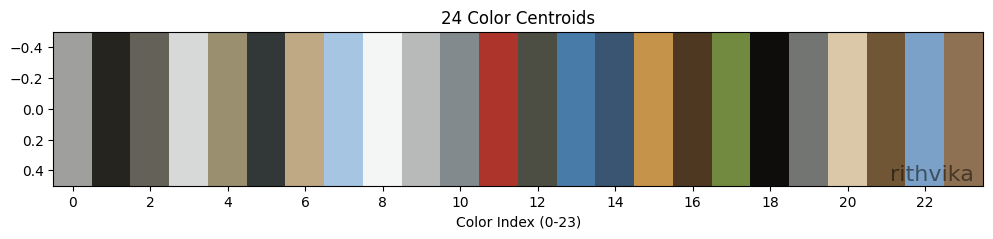

In [4]:



# ============================================================================
# Load Color Centroids
# ============================================================================

centroids = np.load(FILE_PATH)  # shape (24,3)
print("Centroid range:", centroids.min(), "→", centroids.max())

# Ensure centroids are normalized to [0,1] range
if centroids.max() > 2.0:
    centroids = centroids.astype(np.float32) / 255.0
centroids = centroids.astype(np.float32)

# Convert to tensor for GPU usage
CENTROIDS_TENSOR = torch.from_numpy(centroids).to(DEVICE)

print(f"Color centroids loaded: shape {centroids.shape}")
print(f"Centroid value range: [{centroids.min():.3f}, {centroids.max():.3f}]")


# Visualize the color centroids
fig, ax = plt.subplots(1, 1, figsize=(12, 2))
centroid_grid = centroids.reshape(1, 24, 3)
ax.imshow(centroid_grid, aspect='auto')
ax.set_title("24 Color Centroids")
ax.set_xlabel("Color Index (0-23)")
ax.set_xticks(range(0, 24, 2))
add_watermark_to_ax(ax)
plt.show()


#### Dataset Implementation


In [5]:
# ============================================================================
# Dataset Implementation
# ============================================================================

"""
CIFAR10 Colourization Dataset
Custom dataset class that:
1. Loads CIFAR-10 images
2. Converts RGB to grayscale for input
3. Maps each RGB pixel to nearest color centroid for labels
4. Returns (grayscale_input, label_map, original_rgb)
"""
class CIFAR10Colourized(Dataset):
    """
    Returns:
      gray_tensor: FloatTensor [NIC,32,32] values in [0,1]
      label_map: LongTensor [32,32] values in {0..NC-1}
      rgb: FloatTensor [3,32,32] original RGB (for visualization)
    """
    def __init__(self, root, train=True, transform=None, download=True, nic=1):
        self.cifar = datasets.CIFAR10(root=root, train=train, download=False)
        self.to_tensor = transforms.ToTensor()
        self.transform = transform
        self.centroids = centroids
        self.nic = nic  # Number of input channels

    def __len__(self):
        return len(self.cifar)

    def rgb_to_labelmap(self, rgb_tensor):
        """
        rgb_tensor: torch.FloatTensor [3,H,W] in [0,1]
        Returns: LongTensor [H,W] class indices 0..NC-1
        """
        C, H, W = rgb_tensor.shape
        pixels = rgb_tensor.permute(1,2,0).reshape(-1,3)
        pix = pixels.to(torch.float32)
        cent = torch.from_numpy(self.centroids).to(pix.device).float()
        
        p_sq = (pix * pix).sum(dim=1, keepdim=True)
        c_sq = (cent * cent).sum(dim=1).unsqueeze(0)
        pc = pix @ cent.t()
        dists = p_sq + c_sq - 2.0 * pc
        labels_flat = torch.argmin(dists, dim=1)
        labels = labels_flat.reshape(H,W).long()
        return labels

    def __getitem__(self, idx):
        img, _ = self.cifar[idx]
        rgb = self.to_tensor(img)  # [3,32,32]
        
        # Create input based on NIC
        if self.nic == 1:
            # Grayscale
            gray = transforms.functional.rgb_to_grayscale(img, num_output_channels=1)
            input_t = transforms.ToTensor()(gray)  # [1,32,32]
        elif self.nic == 3:
            # Full RGB as input
            input_t = rgb  # [3,32,32]
        else:
            raise ValueError(f"Unsupported NIC={self.nic}")
        
        label_map = self.rgb_to_labelmap(rgb)
        return input_t, label_map, rgb

print("Dataset class defined successfully")

Dataset class defined successfully


### Model Architecture Implementation

In [6]:

"""
Convolutional Encoder-Decoder Network
Architecture follows the specification:
- Encoder: 3 Conv+BN+ReLU+Pool blocks (32→16→8→4)
- Decoder: 3 ConvTranspose+BN+ReLU blocks (4→8→16→32)
- Classifier: Final Conv layer for per-pixel classification

This implements learned upsampling via transpose convolutions rather than interpolation.
"""
class ColourizationNet(nn.Module):
    def __init__(self, NIC=1, NF=64, NC=24, kernel_size=3):
        """
        Architecture (recommended block sequence):
        Input [B, NIC, 32, 32]
        Conv2d -> BN -> ReLU -> MaxPool2d  -> [B, NF, 16, 16]
        Conv2d -> BN -> ReLU -> MaxPool2d  -> [B, 2*NF, 8, 8]
        Conv2d -> BN -> ReLU -> MaxPool2d  -> [B, 4*NF, 4, 4]
        ConvTranspose2d -> BN -> ReLU      -> [B, 2*NF, 8, 8]
        ConvTranspose2d -> BN -> ReLU      -> [B, NF, 16, 16]
        ConvTranspose2d -> BN -> ReLU      -> [B, NC, 32, 32]
        Conv2d (classifier) -> [B, NC, 32, 32]
        """
        super().__init__()
        
        # Calculate padding for encoder convs
        pad = (kernel_size - 1) // 2
        
        # Encoder
        self.conv1 = nn.Conv2d(NIC, NF, kernel_size=kernel_size, padding=pad, bias=False)
        self.bn1 = nn.BatchNorm2d(NF)
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        self.conv2 = nn.Conv2d(NF, 2*NF, kernel_size=kernel_size, padding=pad, bias=False)
        self.bn2 = nn.BatchNorm2d(2*NF)
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        self.conv3 = nn.Conv2d(2*NF, 4*NF, kernel_size=kernel_size, padding=pad, bias=False)
        self.bn3 = nn.BatchNorm2d(4*NF)
        self.pool3 = nn.MaxPool2d(kernel_size=2)

        # Decoder
        self.deconv1 = nn.ConvTranspose2d(4*NF, 2*NF, kernel_size=2, stride=2, bias=False)
        self.dbn1 = nn.BatchNorm2d(2*NF)

        self.deconv2 = nn.ConvTranspose2d(2*NF, NF, kernel_size=2, stride=2, bias=False)
        self.dbn2 = nn.BatchNorm2d(NF)

        self.deconv3 = nn.ConvTranspose2d(NF, NC, kernel_size=2, stride=2, bias=False)
        self.dbn3 = nn.BatchNorm2d(NC)

        # Classifier
        self.classifier = nn.Conv2d(NC, NC, kernel_size=1, bias=True)

    def forward(self, x):
        # Encoder
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x)
        x = self.pool3(x)

        # Decoder
        x = self.deconv1(x)
        x = self.dbn1(x)
        x = F.relu(x)

        x = self.deconv2(x)
        x = self.dbn2(x)
        x = F.relu(x)

        x = self.deconv3(x)
        x = self.dbn3(x)
        x = F.relu(x)

        # Classifier
        logits = self.classifier(x)
        return logits

print("Model architecture defined successfully")

Model architecture defined successfully


### Utility Functions

In [7]:


"""
Helper Functions for Color Mapping and Visualization
- map_pred_to_rgb: Converts predicted class labels back to RGB colors
- Used for generating colorized output images during evaluation
"""

def map_pred_to_rgb(pred_labels, centroids_tensor):
    """Convert predicted class labels back to RGB colors"""
    if pred_labels.dim() == 2:
        H, W = pred_labels.shape
        lab_flat = pred_labels.reshape(-1)
        cols = centroids_tensor[lab_flat.long()]
        cols = cols.reshape(H, W, 3).permute(2,0,1)
        return cols
    elif pred_labels.dim() == 3:
        B, H, W = pred_labels.shape
        out = []
        for b in range(B):
            lab_flat = pred_labels[b].reshape(-1)
            cols = centroids_tensor[lab_flat.long()]
            cols = cols.reshape(H, W, 3).permute(2,0,1)
            out.append(cols)
        out = torch.stack(out, dim=0)
        return out
    else:
        raise ValueError("Unsupported pred_labels dim")

def compute_accuracy(logits, labels):
    """Compute pixel-wise accuracy"""
    preds = torch.argmax(logits, dim=1)
    correct = (preds == labels).float().sum()
    total = labels.numel()
    return (correct / total).item() * 100

print("Utility functions defined")

Utility functions defined


### Fixed Training and Evaluation

In [8]:
"""
Training and Evaluation Pipeline
- Loads CIFAR-10 dataset with train/val split
- Trains encoder-decoder model with cross-entropy loss
- Logs metrics to WandB
- Saves best checkpoint based on validation loss
- Generates example colorizations and loss curves
"""
def train_and_evaluate(NIC=1, NF=64, NC=24, LR=1e-3, BATCH_SIZE=64, NUM_EPOCHS=27):
    """
    Original training pipeline - runs baseline model before sweep
    """
    print("\n" + "="*70)
    print("BASELINE TRAINING")
    print("="*70)
    print(f"Config: NIC={NIC}, NF={NF}, NC={NC}, LR={LR}, BATCH_SIZE={BATCH_SIZE}, EPOCHS={NUM_EPOCHS}")
    print("="*70 + "\n")
    
    # Prepare datasets
    full_train = CIFAR10Colourized(DATA_ROOT, train=True, download=False, nic=NIC)
    testset = CIFAR10Colourized(DATA_ROOT, train=False, download=False, nic=NIC)

    n_train = int(0.9 * len(full_train))
    n_val = len(full_train) - n_train
    trainset, valset = random_split(full_train, [n_train, n_val], 
                                    generator=torch.Generator().manual_seed(SEED))
    
    print(f"Dataset sizes: Train={n_train}, Val={n_val}, Test={len(testset)}")

    train_loader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, 
                             num_workers=0, pin_memory=True)
    val_loader = DataLoader(valset, batch_size=BATCH_SIZE, shuffle=False, 
                           num_workers=0, pin_memory=True)
    test_loader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, 
                            num_workers=0, pin_memory=True)

    # Model, optimizer, loss
    model = ColourizationNet(NIC=NIC, NF=NF, NC=NC).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    
    # WandB initialization
    if WANDB_AVAILABLE:
        baseline_name = f"baseline_nf{NF}_lr{LR}_bs{BATCH_SIZE}_epochs{NUM_EPOCHS}"
        wandb.init(
            project="cifar10-colourization", 
            config={
                "NIC": NIC, "NF": NF, "NC": NC, "lr": LR, 
                "batch_size": BATCH_SIZE, "num_epochs": NUM_EPOCHS
            },
            name=baseline_name,
            tags=["baseline", f"nf_{NF}", f"lr_{LR}", f"batch_size_{BATCH_SIZE}"]
        )
        wandb.watch(model, log="all", log_freq=100)

    best_val_loss = float("inf")
    best_model_path = None
    train_losses = []
    val_losses = []

    # Training loop
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        num_batches = 0
        pbar = tqdm(train_loader, desc=f"Epoch {epoch} Train", leave=False)
        
        for gray, label_map, _ in pbar:
            gray = gray.to(DEVICE)
            label_map = label_map.to(DEVICE)

            optimizer.zero_grad()
            logits = model(gray)
            loss = criterion(logits, label_map)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            num_batches += 1
            pbar.set_postfix(loss=total_loss / num_batches)

        avg_train_loss = total_loss / max(1, num_batches)
        train_losses.append(avg_train_loss)

        # Validation
        model.eval()
        total_val_loss = 0.0
        num_val_batches = 0
        with torch.no_grad():
            for gray, label_map, _ in val_loader:
                gray = gray.to(DEVICE)
                label_map = label_map.to(DEVICE)
                logits = model(gray)
                loss = criterion(logits, label_map)
                total_val_loss += loss.item()
                num_val_batches += 1
        avg_val_loss = total_val_loss / max(1, num_val_batches)
        val_losses.append(avg_val_loss)

        print(f"Epoch {epoch}  train_loss={avg_train_loss:.4f}  val_loss={avg_val_loss:.4f}")

        if WANDB_AVAILABLE:
            wandb.log({"epoch": epoch, "train_loss": avg_train_loss, "val_loss": avg_val_loss})

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            model_filename = f"best_baseline_loss_{best_val_loss:.4f}.pth"
            best_model_path = os.path.join(CHECKPOINT_DIR, model_filename)
            torch.save(model.state_dict(), best_model_path)
            print(f"  -> saved new best checkpoint (val_loss={avg_val_loss:.4f})")

    # Save final model
    final_model_path = os.path.join(CHECKPOINT_DIR, "final_baseline_model.pth")
    torch.save({"epoch": NUM_EPOCHS, "model_state": model.state_dict()}, final_model_path)

    # Generate example colourizations
    print("\nGenerating 10 example colourizations...")
    model.eval()
    examples = []
    example_count = 10
    collected = 0
    
    with torch.no_grad():
        for gray, label_map, rgb in test_loader:
            gray = gray.to(DEVICE)
            logits = model(gray)
            preds = torch.argmax(logits, dim=1)

            for i in range(gray.size(0)):
                inp_gray = gray[i].cpu()
                pred_lab = preds[i].cpu()
                gt_rgb = rgb[i].cpu()

                pred_rgb = map_pred_to_rgb(pred_lab, torch.from_numpy(centroids))
                
                # Convert input to 3-channel for visualization
                if NIC == 1:
                    inp_gray_3 = inp_gray.repeat(3,1,1)
                else:
                    inp_gray_3 = inp_gray
                    
                examples.append((inp_gray_3, pred_rgb, gt_rgb))
                collected += 1
                if collected >= example_count:
                    break
            if collected >= example_count:
                break

    # Save example grid
    rows = []
    for (g, p, gt) in examples:
        p = p.clamp(0,1)
        gt = gt.clamp(0,1)
        g = g.clamp(0,1)
        row = torch.cat([g, p, gt], dim=2)
        rows.append(row)
    grid = torch.cat(rows, dim=1)
    # save_image(grid, os.path.join(CHECKPOINT_DIR, "baseline_examples_grid.png"))
    save_tensor_image_with_watermark(grid, os.path.join(CHECKPOINT_DIR, "baseline_examples_grid.png"))
    print("Saved example colourizations to:", os.path.join(CHECKPOINT_DIR, "baseline_examples_grid.png"))
        
    # Display example grid
    grid_np = grid.permute(1, 2, 0).cpu().numpy()
    plt.figure(figsize=(12, 20))
    plt.imshow(grid_np)
    plt.axis('off')
    plt.title("Baseline Example Colourizations: [Gray | Predicted | Ground Truth]")
    add_watermark_to_ax(plt.gca()) 
    plt.savefig(os.path.join(CHECKPOINT_DIR, "baseline_examples.png"), dpi=150)
    plt.show()

    # Plot and save loss curves
    plt.figure(figsize=(8,5))
    plt.plot(range(1, len(train_losses)+1), train_losses, label="train_loss", marker='o')
    plt.plot(range(1, len(val_losses)+1), val_losses, label="val_loss", marker='s')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.title("Baseline Training and Validation Loss")
    plt.grid(True)
    plt.tight_layout()
    add_watermark_to_ax(plt.gca()) 
    plt.savefig(os.path.join(CHECKPOINT_DIR, "baseline_loss_curve.png"))
    plt.show()

    if WANDB_AVAILABLE:
        model_artifact = wandb.Artifact("baseline-model-checkpoints", type="model")
        if best_model_path and os.path.exists(best_model_path):
            model_artifact.add_file(best_model_path)
        if os.path.exists(final_model_path):
            model_artifact.add_file(final_model_path)
        wandb.log_artifact(model_artifact)

        results_artifact = wandb.Artifact("baseline-training-results", type="results")
        results_artifact.add_file(os.path.join(CHECKPOINT_DIR, "baseline_examples_grid.png"))
        results_artifact.add_file(os.path.join(CHECKPOINT_DIR, "baseline_loss_curve.png"))
        wandb.log_artifact(results_artifact)

        wandb.finish()

    print(f"\nBaseline training completed! Best val loss: {best_val_loss:.4f}")
    
    return {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_loss": best_val_loss,
        "examples_grid": os.path.join(CHECKPOINT_DIR, "baseline_examples_grid.png"),
        "loss_curve": os.path.join(CHECKPOINT_DIR, "baseline_loss_curve.png"),
    }

# ============================================================================
# Analytical Questions 
# ============================================================================

def analytical_questions():
    """
    Compute symbolically (in terms of NIC, NF, NC):
    1. Number of weights (ignore biases & BN)
    2. Number of outputs (total activation elements across all layers)
    3. Number of connections (weights × input activations per layer)
    For both input 32x32 and doubled 64x64.
    """
    NIC, NF, NC = 1, 64, 24
    
    # ----- ARCHITECTURE -----
    # Encoder
    # Conv1: NIC -> NF, 3x3, stride=1, pad=1, output 32x32 -> pool -> 16x16
    # Conv2: NF -> 2NF, 3x3, output 16x16 -> pool -> 8x8
    # Conv3: 2NF -> 4NF, 3x3, output 8x8 -> pool -> 4x4
    # Decoder
    # Deconv1: 4NF -> 2NF, kernel=2,stride=2 -> 8x8
    # Deconv2: 2NF -> NF, kernel=2,stride=2 -> 16x16
    # Deconv3: NF -> NC, kernel=2,stride=2 -> 32x32
    # Final Conv: NC -> NC, kernel=3,pad=1 -> 32x32


    print("\n================ Analytical Computation ================\n")

    # 1.Number of weights per layer (ignoring biases & BN)
    W_conv1 = 3 * 3 * NIC * NF
    W_conv2 = 3 * 3 * NF * (2 * NF)
    W_conv3 = 3 * 3 * (2 * NF) * (4 * NF)
    W_deconv1 = 2 * 2 * (4 * NF) * (2 * NF)
    W_deconv2 = 2 * 2 * (2 * NF) * NF
    W_deconv3 = 2 * 2 * NF * NC
    W_classif = 1 * 1 * NC * NC  # Changed to 1x1 conv

    total_weights = W_conv1 + W_conv2 + W_conv3 + W_deconv1 + W_deconv2 + W_deconv3 + W_classif

    print(f"Total number of weights (ignoring biases/BN):")
    print(f"   = 9*NIC*NF + 18*NF^2 + 72*NF^2 + 16*NF^2 + 8*NF^2 + 4*NF*NC + NC^2")
    print(f"   = {total_weights} (symbolic form)")

    # 2.Total number of output activations (for input 32x32)
    A_conv1 = NF * 32 * 32
    A_pool1 = NF * 16 * 16
    A_conv2 = 2 * NF * 16 * 16
    A_pool2 = 2 * NF * 8 * 8
    A_conv3 = 4 * NF * 8 * 8
    A_pool3 = 4 * NF * 4 * 4
    A_deconv1 = 2 * NF * 8 * 8
    A_deconv2 = NF * 16 * 16
    A_deconv3 = NC * 32 * 32
    A_classif = NC * 32 * 32

    total_acts_32 = (A_conv1 + A_pool1 + A_conv2 + A_pool2 + A_conv3 +
                     A_pool3 + A_deconv1 + A_deconv2 + A_deconv3 + A_classif)

    print("\nTotal number of output activations (input 32×32):")
    print(f"   = {total_acts_32} elements")

    # For doubled input 64×64
    A_conv1_64 = NF * 64 * 64
    A_pool1_64 = NF * 32 * 32
    A_conv2_64 = 2 * NF * 32 * 32
    A_pool2_64 = 2 * NF * 16 * 16
    A_conv3_64 = 4 * NF * 16 * 16
    A_pool3_64 = 4 * NF * 8 * 8
    A_deconv1_64 = 2 * NF * 16 * 16
    A_deconv2_64 = NF * 32 * 32
    A_deconv3_64 = NC * 64 * 64
    A_classif_64 = NC * 64 * 64

    total_acts_64 = (A_conv1_64 + A_pool1_64 + A_conv2_64 + A_pool2_64 +
                     A_conv3_64 + A_pool3_64 + A_deconv1_64 + A_deconv2_64 +
                     A_deconv3_64 + A_classif_64)

    print(f"   For input 64×64: total activations = {total_acts_64}")

    # 3.Number of connections
    Conn_conv1 = (3 * 3 * NIC * NF) * (32 * 32)
    Conn_conv2 = (3 * 3 * NF * (2 * NF)) * (16 * 16)
    Conn_conv3 = (3 * 3 * (2 * NF) * (4 * NF)) * (8 * 8)
    Conn_deconv1 = (2 * 2 * (4 * NF) * (2 * NF)) * (8 * 8)
    Conn_deconv2 = (2 * 2 * (2 * NF) * NF) * (16 * 16)
    Conn_deconv3 = (2 * 2 * NF * NC) * (32 * 32)
    Conn_classif = (1 * 1 * NC * NC) * (32 * 32)  # Changed to 1x1 conv

    total_connections_32 = (Conn_conv1 + Conn_conv2 + Conn_conv3 +
                            Conn_deconv1 + Conn_deconv2 + Conn_deconv3 + Conn_classif)

    print("\nTotal number of connections (input 32×32):")
    print(f"   = {total_connections_32}")

    # For doubled input (64×64)
    Conn_conv1_64 = (3 * 3 * NIC * NF) * (64 * 64)
    Conn_conv2_64 = (3 * 3 * NF * (2 * NF)) * (32 * 32)
    Conn_conv3_64 = (3 * 3 * (2 * NF) * (4 * NF)) * (16 * 16)
    Conn_deconv1_64 = (2 * 2 * (4 * NF) * (2 * NF)) * (16 * 16)
    Conn_deconv2_64 = (2 * 2 * (2 * NF) * NF) * (32 * 32)
    Conn_deconv3_64 = (2 * 2 * NF * NC) * (64 * 64)
    Conn_classif_64 = (1 * 1 * NC * NC) * (64 * 64)  # Changed to 1x1 conv

    total_connections_64 = (Conn_conv1_64 + Conn_conv2_64 + Conn_conv3_64 +
                            Conn_deconv1_64 + Conn_deconv2_64 + Conn_deconv3_64 +
                            Conn_classif_64)

    print(f"   For input 64×64: total connections = {total_connections_64}")
    print("\n========================================================\n")


#### Execution
Main execution cell:
- Runs baseline training.


CIFAR-10 Image Colorization - Complete Pipeline
Device: cuda

STEP 1: Baseline Training (Original Configuration)

BASELINE TRAINING
Config: NIC=1, NF=64, NC=24, LR=0.001, BATCH_SIZE=64, EPOCHS=27

Dataset sizes: Train=45000, Val=5000, Test=10000


wandb: Currently logged in as: rithvikakonda (rithvikakonda-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_095846-k7ssktg1
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run baseline_nf64_lr0.001_bs64_epochs27
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization/runs/k7ssktg1


Epoch 1  train_loss=2.0136  val_loss=1.8011
  -> saved new best checkpoint (val_loss=1.8011)


Epoch 2  train_loss=1.7298  val_loss=1.6636
  -> saved new best checkpoint (val_loss=1.6636)


Epoch 3  train_loss=1.6696  val_loss=1.6359
  -> saved new best checkpoint (val_loss=1.6359)


...

Epoch 23  train_loss=1.4768  val_loss=1.5119


Epoch 24  train_loss=1.4767  val_loss=1.5519


Epoch 25  train_loss=1.4711  val_loss=1.4869


Epoch 26  train_loss=1.4661  val_loss=1.4822
  -> saved new best checkpoint (val_loss=1.4822)


Epoch 27  train_loss=1.4639  val_loss=1.4984

Generating 10 example colourizations...
Saved example colourizations to: /kaggle/working/checkpoints/baseline_examples_grid.png


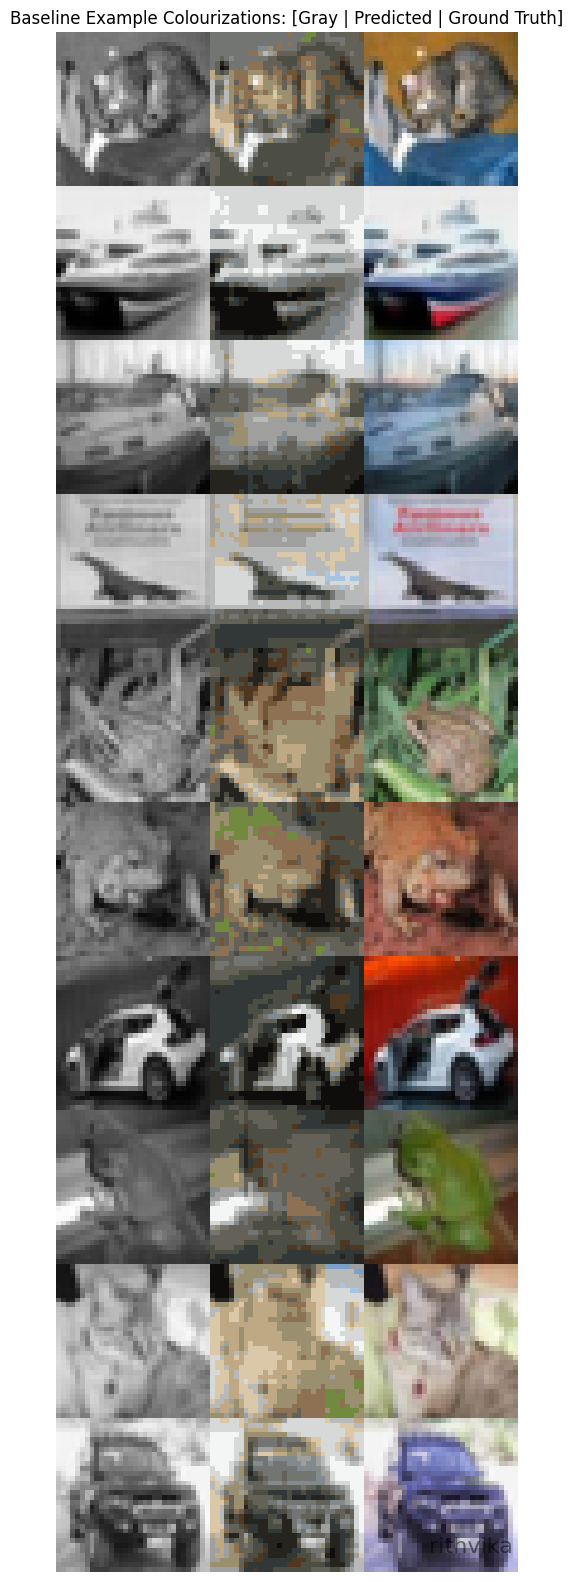

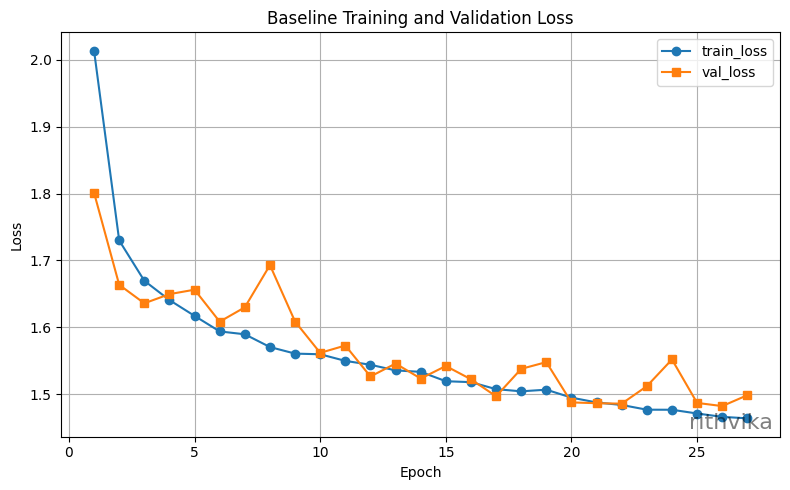

wandb: uploading artifact baseline-model-checkpoints; uploading artifact baseline-training-results
wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▁▂▂▂▂▃▃▃▃▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██
wandb: train_loss █▄▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
wandb:   val_loss █▅▄▅▅▄▄▆▄▃▃▂▂▂▂▂▁▂▂▁▁▁▂▃▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 27
wandb: train_loss 1.46387
wandb:   val_loss 1.49845
wandb: 
wandb: 🚀 View run baseline_nf64_lr0.001_bs64_epochs27 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization/runs/k7ssktg1
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization
wandb: Synced 5 W&B file(s), 0 media file(s), 6 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_095846-k7ssktg1/logs



Baseline training completed! Best val loss: 1.4822

STEP 2: Analytical Questions

================ Analytical Computation ================

Total number of weights (ignoring biases/BN):
   = 9*NIC*NF + 18*NF^2 + 72*NF^2 + 16*NF^2 + 8*NF^2 + 4*NF*NC + NC^2
   = 539776 (symbolic form)

Total number of output activations (input 32×32):
   = 217088 elements
   For input 64×64: total activations = 868352

Total number of connections (input 32×32):
   = 61997056
   For input 64×64: total connections = 247988224




In [ ]:

# ============================================================================
# Main Execution
# ============================================================================

if __name__ == "__main__":
    print("\n" + "="*70)
    print("CIFAR-10 Image Colorization - Complete Pipeline")
    print("="*70)
    print(f"Device: {DEVICE}")
    print("="*70 + "\n")
    
    # STEP 1: Run baseline training with original configuration (27 epochs)
    print("STEP 1: Baseline Training (Original Configuration)")
    baseline_results = train_and_evaluate(NIC=1, NF=64, NC=24, LR=1e-3, 
                                         BATCH_SIZE=64, NUM_EPOCHS=27)
    
    # STEP 2: Run analytical questions
    print("\nSTEP 2: Analytical Questions")
    analytical_questions()
    ## Ignore results from analytical questions
    

### Hyperparameter Sweep Configuration
Defines a list of hyperparameter configurations for sweeping over learning rate, batch size, number of filters, input channels, kernel size, and optimizer.

In [10]:
# ============================================================================
# Hyperparameter Sweep Configuration
# # ============================================================================

# Extended sweep configurations (20+ configs)
SWEEP_CONFIGS = [
    {"lr": 0.01, "batch_size": 256, "nf": 128, "nic": 1, "nc": 24, "kernel_size": 5, "optimizer": "adam"},
     {"lr": 3e-4, "batch_size": 128, "nf": 32, "nic": 1, "nc": 24,"kernel_size": 5, "optimizer": "adam"},
    {"lr": 1e-3, "batch_size": 128, "nf": 32, "nic": 1, "nc": 24,"kernel_size": 5, "optimizer": "adam"},
    {"lr": 1e-3, "batch_size": 128, "nf": 16, "nic": 1, "nc": 24,"kernel_size": 5, "optimizer": "adam"},
    
    
    # Variations on NF (8, 16, 32, 64, 128)
    {"lr": 1e-3, "batch_size": 64, "nf": 8, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 1e-3, "batch_size": 64, "nf": 16, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 1e-3, "batch_size": 128, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 1e-3, "batch_size": 128, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    
    # Variations on NIC (1 vs 3)
    {"lr": 1e-3, "batch_size": 64, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 1e-3, "batch_size": 64, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 3e-4, "batch_size": 128, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    
    # Learning rate variations
    {"lr": 1e-4, "batch_size": 64, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 3e-4, "batch_size": 64, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 3e-3, "batch_size": 64, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    
    # Batch size variations
    {"lr": 1e-3, "batch_size": 32, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    {"lr": 1e-3, "batch_size": 128, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    
    # Kernel size variations
    {"lr": 1e-3, "batch_size": 64, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 5, "optimizer": "adam"},
    {"lr": 3e-4, "batch_size": 64, "nf": 16, "nic": 1, "nc": 24, "kernel_size": 5, "optimizer": "adam"},
    
    # SGD optimizer
    {"lr": 1e-3, "batch_size": 64, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "sgd"},
    {"lr": 3e-3, "batch_size": 128, "nf": 32, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "sgd"},
    
    # Mixed configurations
    # {"lr": 5e-4, "batch_size": 128, "nf": 16, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
    # {"lr": 1e-3, "batch_size": 128, "nf": 64, "nic": 1, "nc": 24, "kernel_size": 5, "optimizer": "adam"},
    # {"lr": 3e-4, "batch_size": 256, "nf": 64, "nic": 1, "nc": 24, "kernel_size": 3, "optimizer": "adam"},
   
]

print(f"Total sweep configurations: {len(SWEEP_CONFIGS)}")

Total sweep configurations: 20


### Execution of Hyperparameter Sweep
Runs the sweep runner for all configurations and prints a summary of results.

In [11]:


def sweep_runner(num_epochs=12):
    """
    Run hyperparameter sweep with 10-15 epochs per configuration
    """
    project_name = "cifar10-colourization-sweep"
    centroids_np = centroids
    centroids_tensor = torch.from_numpy(centroids_np).to(DEVICE)
    
    results = []

    for i, cfg in enumerate(SWEEP_CONFIGS):
        print(f"\n{'='*70}")
        print(f"Running config {i+1}/{len(SWEEP_CONFIGS)}: {cfg}")
        print(f"{'='*70}")
        
        run_name = f"sweep_{i+1:02d}_nf{cfg['nf']}_nic{cfg['nic']}_lr{cfg['lr']}"

        train_losses, val_losses = [], []
        train_accs, val_accs = [], []

        with wandb.init(project=project_name, config=cfg, name=run_name):
            # Model with variable NIC, NF, NC
            model = ColourizationNet(
                NIC=cfg["nic"], 
                NF=cfg["nf"], 
                NC=cfg["nc"], 
                kernel_size=cfg["kernel_size"]
            ).to(DEVICE)
            
            criterion = nn.CrossEntropyLoss()
            
            if cfg["optimizer"].lower() == "adam":
                optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
            else:
                optimizer = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9)

            # Dataset with variable NIC
            full_train = CIFAR10Colourized(DATA_ROOT, train=True, download=False, nic=cfg["nic"])
            testset = CIFAR10Colourized(DATA_ROOT, train=False, download=False, nic=cfg["nic"])
            
            n_train = int(0.9 * len(full_train))
            n_val = len(full_train) - n_train
            trainset, valset = random_split(full_train, [n_train, n_val], 
                                           generator=torch.Generator().manual_seed(SEED))

            train_loader = DataLoader(trainset, batch_size=cfg["batch_size"], 
                                     shuffle=True, num_workers=0, pin_memory=True)
            val_loader = DataLoader(valset, batch_size=cfg["batch_size"], 
                                   shuffle=False, num_workers=0, pin_memory=True)

            best_val_loss, best_val_acc = float("inf"), 0.0
            
            # Training loop (10-15 epochs)
            for epoch in range(1, num_epochs + 1):
                model.train()
                total_loss, total_acc = 0.0, 0.0
                num_batches = 0
                
                pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs}", leave=False)
                for gray, label_map, _ in pbar:
                    gray, label_map = gray.to(DEVICE), label_map.to(DEVICE)
                    
                    optimizer.zero_grad()
                    logits = model(gray)
                    loss = criterion(logits, label_map)
                    acc = compute_accuracy(logits, label_map)
                    
                    loss.backward()
                    optimizer.step()
                    
                    total_loss += loss.item()
                    total_acc += acc
                    num_batches += 1
                    
                    pbar.set_postfix(loss=total_loss/num_batches, acc=f"{total_acc/num_batches:.2f}%")

                avg_train_loss = total_loss / num_batches
                avg_train_acc = total_acc / num_batches

                # Validation
                model.eval()
                val_loss, val_acc = 0.0, 0.0
                num_val_batches = 0
                
                with torch.no_grad():
                    for gray, label_map, _ in val_loader:
                        gray, label_map = gray.to(DEVICE), label_map.to(DEVICE)
                        logits = model(gray)
                        loss = criterion(logits, label_map)
                        acc = compute_accuracy(logits, label_map)
                        val_loss += loss.item()
                        val_acc += acc
                        num_val_batches += 1
                        
                avg_val_loss = val_loss / num_val_batches
                avg_val_acc = val_acc / num_val_batches

                # Log to wandb
                wandb.log({
                    "epoch": epoch,
                    "train_loss": avg_train_loss,
                    "val_loss": avg_val_loss,
                    "train_acc": avg_train_acc,
                    "val_acc": avg_val_acc
                })

                train_losses.append(avg_train_loss)
                val_losses.append(avg_val_loss)
                train_accs.append(avg_train_acc)
                val_accs.append(avg_val_acc)

                print(f"Epoch {epoch:02d} | TrainLoss={avg_train_loss:.4f} | ValLoss={avg_val_loss:.4f} "
                      f"| TrainAcc={avg_train_acc:.2f}% | ValAcc={avg_val_acc:.2f}%")

                # Save best checkpoint
                if avg_val_loss < best_val_loss:
                    best_val_loss = avg_val_loss
                    best_val_acc = avg_val_acc
                    best_path = os.path.join(CHECKPOINT_DIR, f"best_{run_name}.pth")
                    torch.save(model.state_dict(), best_path)
                    print(f"  Saved best checkpoint (val_loss={avg_val_loss:.4f})")

            # Plot loss and accuracy curves
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
            
            ax1.plot(train_losses, label="Train Loss", marker='o')
            ax1.plot(val_losses, label="Val Loss", marker='s')
            ax1.set_title(f"Loss Curve - {run_name}")
            ax1.set_xlabel("Epoch")
            ax1.set_ylabel("Loss")
            ax1.legend()
            ax1.grid(True, alpha=0.3)
            add_watermark_to_ax(ax1) 

            ax2.plot(train_accs, label="Train Acc", marker='o')
            ax2.plot(val_accs, label="Val Acc", marker='s')
            ax2.set_title(f"Accuracy Curve - {run_name}")
            ax2.set_xlabel("Epoch")
            ax2.set_ylabel("Accuracy (%)")
            ax2.legend()
            ax2.grid(True, alpha=0.3)
            add_watermark_to_ax(ax2) 
            
            plt.tight_layout()
            plt.savefig(os.path.join(CHECKPOINT_DIR, f"{run_name}_curves.png"), dpi=150)
            plt.show()

            # Generate example images
            model.eval()
            example_batch = next(iter(val_loader))
            input_imgs, true_labels, true_rgb_original = example_batch
            input_imgs = input_imgs.to(DEVICE)
            true_labels = true_labels.to(DEVICE)
            
            with torch.no_grad():
                logits = model(input_imgs)
                preds_classes = torch.argmax(logits, dim=1)
            
            pred_rgb = map_pred_to_rgb(preds_classes.cpu(), torch.from_numpy(centroids_np))
            true_rgb = map_pred_to_rgb(true_labels.cpu(), torch.from_numpy(centroids_np))
            
            # Compute error map: correct predictions = black, incorrect = red
            # Check if predictions match ground truth (per-pixel classification)
            correct_mask = (preds_classes == true_labels).cpu().float()  # 1 = correct, 0 = incorrect
            
            # Create RGB error map: black for correct, red for incorrect
            error_map = torch.zeros_like(pred_rgb)
            error_map[:, 0, :, :] = 1.0 - correct_mask  # Red channel: 1 for incorrect, 0 for correct
            error_map[:, 1, :, :] = 0.0                   # Green channel: always 0
            error_map[:, 2, :, :] = 0.0                   # Blue channel: always 0
            
            # For display: convert input to 3-channel grayscale if NIC=1
            if cfg["nic"] == 1:
                display_input = input_imgs.cpu().repeat(1, 3, 1, 1)
            else:
                display_input = input_imgs.cpu()
            
            pred_rgb = pred_rgb.clamp(0, 1)
            true_rgb = true_rgb.clamp(0, 1)
            display_input = display_input.clamp(0, 1)
            error_map = error_map.clamp(0, 1)
            
            # Show example predictions with error map
            num_show = min(5, input_imgs.size(0))
            fig, axs = plt.subplots(num_show, 4, figsize=(14, num_show * 2.5))
            
            for j in range(num_show):
                input_img = np.transpose(display_input[j].numpy(), (1, 2, 0))
                pred_img = np.transpose(pred_rgb[j].numpy(), (1, 2, 0))
                true_img = np.transpose(true_rgb[j].numpy(), (1, 2, 0))
                error_img = np.transpose(error_map[j].numpy(), (1, 2, 0))
                
                axs[j, 0].imshow(input_img)
                axs[j, 0].set_title("Input")
                axs[j, 0].axis("off")
                
                axs[j, 1].imshow(pred_img)
                axs[j, 1].set_title("Predicted")
                axs[j, 1].axis("off")
                
                axs[j, 2].imshow(true_img)
                axs[j, 2].set_title("Ground Truth")
                axs[j, 2].axis("off")
                
                # Show error map: black = correct, red = incorrect
                axs[j, 3].imshow(error_img)
                axs[j, 3].set_title("Error Map")
                axs[j, 3].axis("off")
                
            plt.suptitle(f"{run_name} | Val Loss: {best_val_loss:.4f}, Val Acc: {best_val_acc:.2f}%", 
                        fontsize=12, y=0.995)
            plt.tight_layout()
            add_watermark_to_ax(plt.gca()) 
            plt.savefig(os.path.join(CHECKPOINT_DIR, f"{run_name}_examples.png"), dpi=150)
            plt.show()
            
            # Log to W&B
            if wandb.run is not None:
                wandb_images = []
                for k in range(num_show):
                    pred_img = np.transpose(pred_rgb[k].cpu().numpy(), (1, 2, 0))
                    wandb_images.append(
                        wandb.Image(pred_img, 
                                  caption=f"Sample {k}: Loss={best_val_loss:.4f}, Acc={best_val_acc:.2f}%")
                    )
                wandb.log({"Example Images": wandb_images})

            # Store results
            results.append({
                "config_id": i+1,
                "run_name": run_name,
                "lr": cfg["lr"],
                "batch_size": cfg["batch_size"],
                "nf": cfg["nf"],
                "nic": cfg["nic"],
                "nc": cfg["nc"],
                "kernel_size": cfg["kernel_size"],
                "optimizer": cfg["optimizer"],
                "best_val_loss": best_val_loss,
                "best_val_acc": best_val_acc
            })

    # ========== Summary of all runs ==========
    print("\n" + "="*70)
    print("SWEEP COMPLETED!")
    print("="*70)
    
    df = pd.DataFrame(results)
    best_loss_run = df.loc[df["best_val_loss"].idxmin()]
    best_acc_run = df.loc[df["best_val_acc"].idxmax()]

    print("\nBest Model by Validation Loss:")
    print("-" * 70)
    print(best_loss_run.to_string())

    print("\nBest Model by Validation Accuracy:")
    print("-" * 70)
    print(best_acc_run.to_string())

    # Summary plot
    fig, ax = plt.subplots(1, 1, figsize=(12, 7))
    scatter = ax.scatter(df["best_val_loss"], df["best_val_acc"], 
                        c=df["nf"], s=150, alpha=0.6, cmap='viridis', 
                        edgecolors='black', linewidth=1.5)
    
    for idx, row in df.iterrows():
        ax.annotate(f"C{row['config_id']}", 
                   (row["best_val_loss"], row["best_val_acc"]),
                   fontsize=9, alpha=0.8, weight='bold')
    
    ax.set_xlabel("Validation Loss", fontsize=12)
    ax.set_ylabel("Validation Accuracy (%)", fontsize=12)
    ax.set_title(f"Sweep Results Summary ({len(SWEEP_CONFIGS)} Configurations)", fontsize=14)
    ax.grid(True, alpha=0.3)
    
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('NF (Number of Filters)', fontsize=10)
    add_watermark_to_ax(ax)
    plt.tight_layout()
    plt.savefig(os.path.join(CHECKPOINT_DIR, "sweep_summary.png"), dpi=150)
    plt.show()

    # Save results to CSV
    df.to_csv(os.path.join(CHECKPOINT_DIR, "sweep_results.csv"), index=False)
    print(f"\nResults saved to: {os.path.join(CHECKPOINT_DIR, 'sweep_results.csv')}")
    # print(f"✓ Check W&B dashboard for detailed metrics: https://wandb.ai")
    
    return df

### Execution of Hyperparameter Sweep



STEP 3: Hyperparameter Sweep
Total configurations: 20
Epochs per run: 10-15

Starting hyperparameter sweep...

Running config 1/20: {'lr': 0.01, 'batch_size': 256, 'nf': 128, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_101742-ysxord4v
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_01_nf128_nic1_lr0.01
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ysxord4v


Epoch 01 | TrainLoss=2.1362 | ValLoss=2.0333 | TrainAcc=28.62% | ValAcc=29.80%
  Saved best checkpoint (val_loss=2.0333)


Epoch 02 | TrainLoss=1.7028 | ValLoss=1.6562 | TrainAcc=38.41% | ValAcc=39.32%
  Saved best checkpoint (val_loss=1.6562)


Epoch 03 | TrainLoss=1.5788 | ValLoss=1.7258 | TrainAcc=41.90% | ValAcc=36.72%


...

Epoch 07 | TrainLoss=1.3972 | ValLoss=1.5529 | TrainAcc=47.39% | ValAcc=42.94%


Epoch 08 | TrainLoss=1.3760 | ValLoss=1.4091 | TrainAcc=48.07% | ValAcc=47.01%
  Saved best checkpoint (val_loss=1.4091)


Epoch 09 | TrainLoss=1.3548 | ValLoss=1.4368 | TrainAcc=48.75% | ValAcc=46.52%


Epoch 10 | TrainLoss=1.3420 | ValLoss=1.5195 | TrainAcc=49.17% | ValAcc=43.99%


Epoch 11 | TrainLoss=1.3268 | ValLoss=1.4261 | TrainAcc=49.73% | ValAcc=47.00%


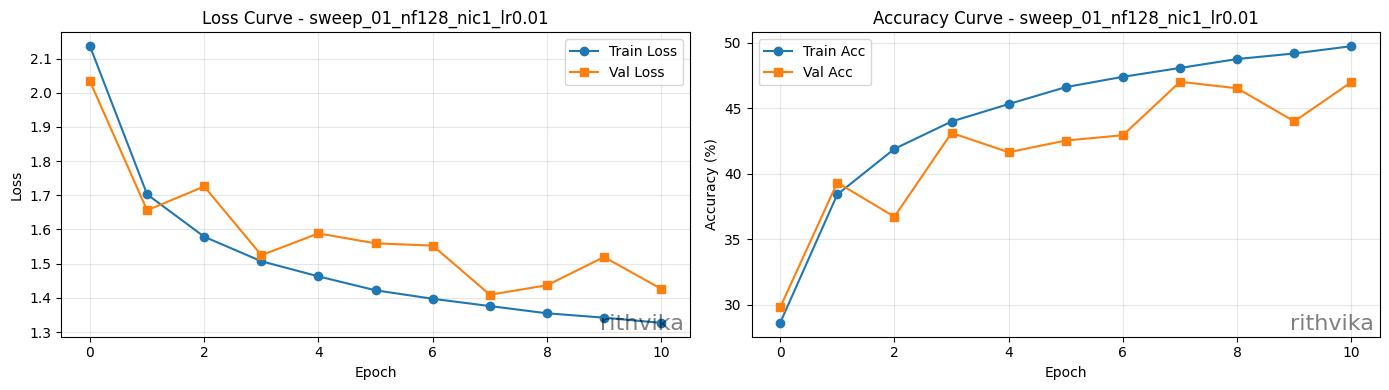

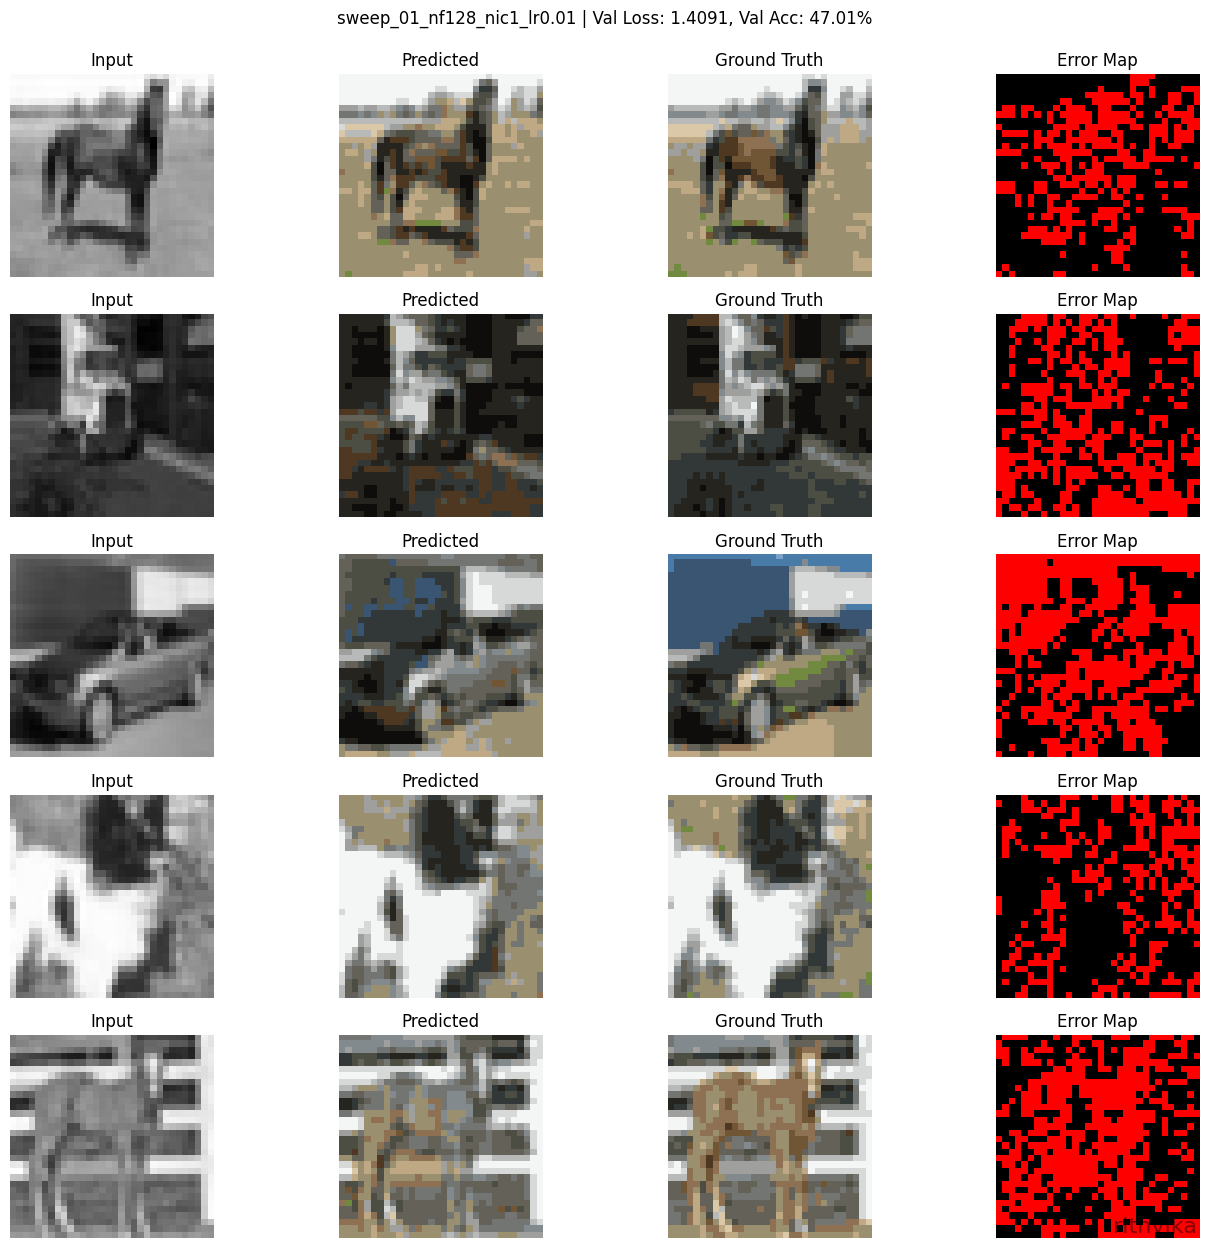

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▄▅▆▇▇▇▇███
wandb: train_loss █▄▃▃▂▂▂▁▁▁▁
wandb:    val_acc ▁▅▄▆▆▆▆██▇█
wandb:   val_loss █▄▅▂▃▃▃▁▁▂▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 49.7287
wandb: train_loss 1.32675
wandb:    val_acc 46.9954
wandb:   val_loss 1.42605
wandb: 
wandb: 🚀 View run sweep_01_nf128_nic1_lr0.01 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ysxord4v
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_101742-ysxord4v/logs



Running config 2/20: {'lr': 0.0003, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_102623-akylodr8
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_02_nf32_nic1_lr0.0003
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/akylodr8


Epoch 01 | TrainLoss=2.6069 | ValLoss=2.2121 | TrainAcc=21.85% | ValAcc=30.64%
  Saved best checkpoint (val_loss=2.2121)


Epoch 02 | TrainLoss=2.0150 | ValLoss=1.8803 | TrainAcc=33.79% | ValAcc=36.60%
  Saved best checkpoint (val_loss=1.8803)


...

Epoch 07 | TrainLoss=1.6057 | ValLoss=1.6090 | TrainAcc=41.77% | ValAcc=41.71%


Epoch 08 | TrainLoss=1.5793 | ValLoss=1.5848 | TrainAcc=42.50% | ValAcc=42.13%
  Saved best checkpoint (val_loss=1.5848)


Epoch 09 | TrainLoss=1.5659 | ValLoss=1.5443 | TrainAcc=42.82% | ValAcc=43.53%
  Saved best checkpoint (val_loss=1.5443)


Epoch 10 | TrainLoss=1.5492 | ValLoss=1.5517 | TrainAcc=43.28% | ValAcc=43.30%


Epoch 11 | TrainLoss=1.5361 | ValLoss=1.5303 | TrainAcc=43.65% | ValAcc=43.73%
  Saved best checkpoint (val_loss=1.5303)


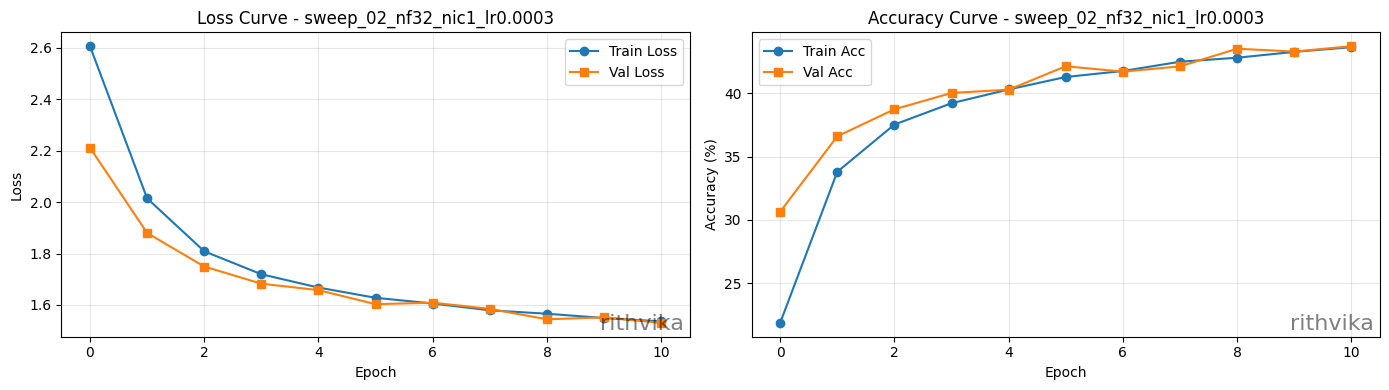

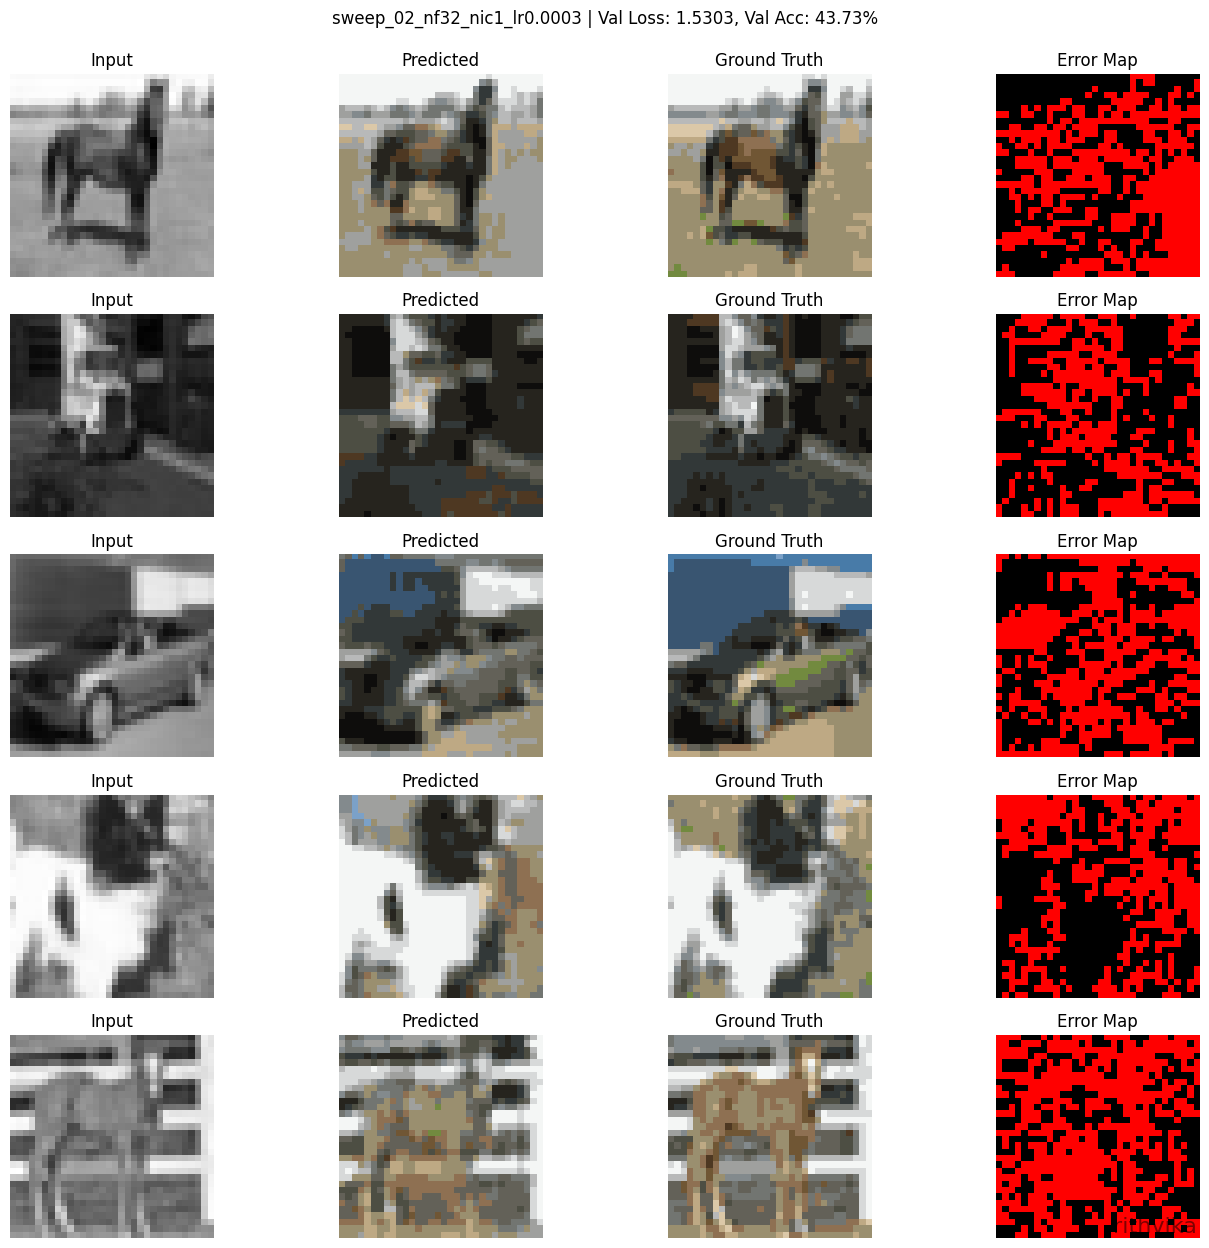

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▄▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▄▅▆▆▇▇▇███
wandb:   val_loss █▅▃▃▂▂▂▂▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 43.64938
wandb: train_loss 1.53612
wandb:    val_acc 43.72875
wandb:   val_loss 1.53034
wandb: 
wandb: 🚀 View run sweep_02_nf32_nic1_lr0.0003 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/akylodr8
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_102623-akylodr8/logs



Running config 3/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_103321-vu4qr75r
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_03_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/vu4qr75r


Epoch 01 | TrainLoss=2.1778 | ValLoss=1.8160 | TrainAcc=29.68% | ValAcc=36.71%
  Saved best checkpoint (val_loss=1.8160)


Epoch 02 | TrainLoss=1.7307 | ValLoss=1.6813 | TrainAcc=38.43% | ValAcc=39.19%
  Saved best checkpoint (val_loss=1.6813)


...

Epoch 07 | TrainLoss=1.5153 | ValLoss=1.5222 | TrainAcc=43.97% | ValAcc=43.73%
  Saved best checkpoint (val_loss=1.5222)


Epoch 08 | TrainLoss=1.5050 | ValLoss=1.5441 | TrainAcc=44.23% | ValAcc=42.99%


Epoch 09 | TrainLoss=1.4894 | ValLoss=1.5258 | TrainAcc=44.73% | ValAcc=43.87%


Epoch 10 | TrainLoss=1.4746 | ValLoss=1.6843 | TrainAcc=45.15% | ValAcc=39.69%


Epoch 11 | TrainLoss=1.4698 | ValLoss=1.4734 | TrainAcc=45.30% | ValAcc=45.15%
  Saved best checkpoint (val_loss=1.4734)


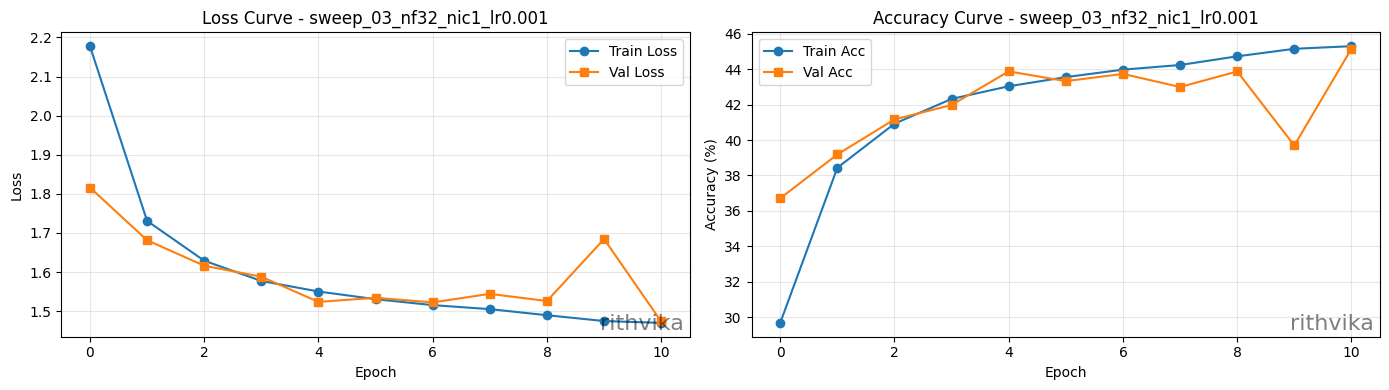

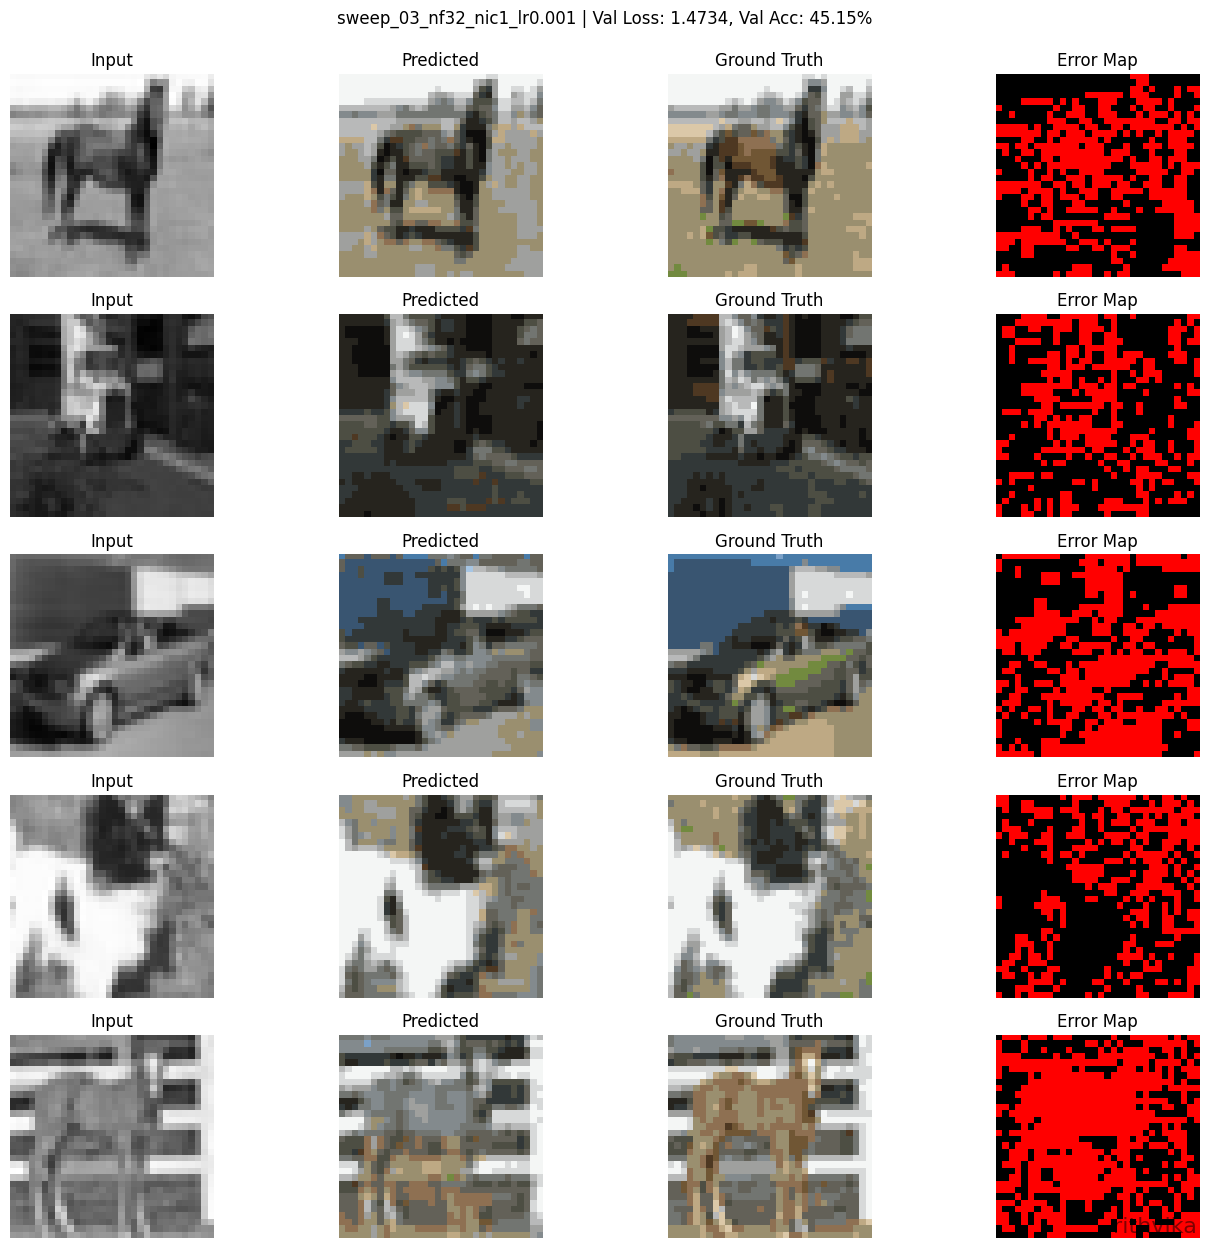

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▄▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▃▅▅▇▆▇▆▇▃█
wandb:   val_loss █▅▄▃▂▂▂▂▂▅▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 45.29852
wandb: train_loss 1.46983
wandb:    val_acc 45.152
wandb:   val_loss 1.4734
wandb: 
wandb: 🚀 View run sweep_03_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/vu4qr75r
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_103321-vu4qr75r/logs



Running config 4/20: {'lr': 0.001, 'batch_size': 128, 'nf': 16, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_104020-xyrupvla
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_04_nf16_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/xyrupvla


Epoch 01 | TrainLoss=2.3162 | ValLoss=1.9466 | TrainAcc=26.69% | ValAcc=33.77%
  Saved best checkpoint (val_loss=1.9466)


Epoch 02 | TrainLoss=1.8695 | ValLoss=1.8047 | TrainAcc=34.96% | ValAcc=36.51%
  Saved best checkpoint (val_loss=1.8047)


...

Epoch 07 | TrainLoss=1.6557 | ValLoss=1.6371 | TrainAcc=39.96% | ValAcc=40.34%
  Saved best checkpoint (val_loss=1.6371)


Epoch 08 | TrainLoss=1.6335 | ValLoss=1.6248 | TrainAcc=40.54% | ValAcc=40.70%
  Saved best checkpoint (val_loss=1.6248)


Epoch 09 | TrainLoss=1.6196 | ValLoss=1.6770 | TrainAcc=40.96% | ValAcc=38.82%


Epoch 10 | TrainLoss=1.6106 | ValLoss=1.5975 | TrainAcc=41.20% | ValAcc=41.61%
  Saved best checkpoint (val_loss=1.5975)


Epoch 11 | TrainLoss=1.6021 | ValLoss=1.5999 | TrainAcc=41.40% | ValAcc=41.60%


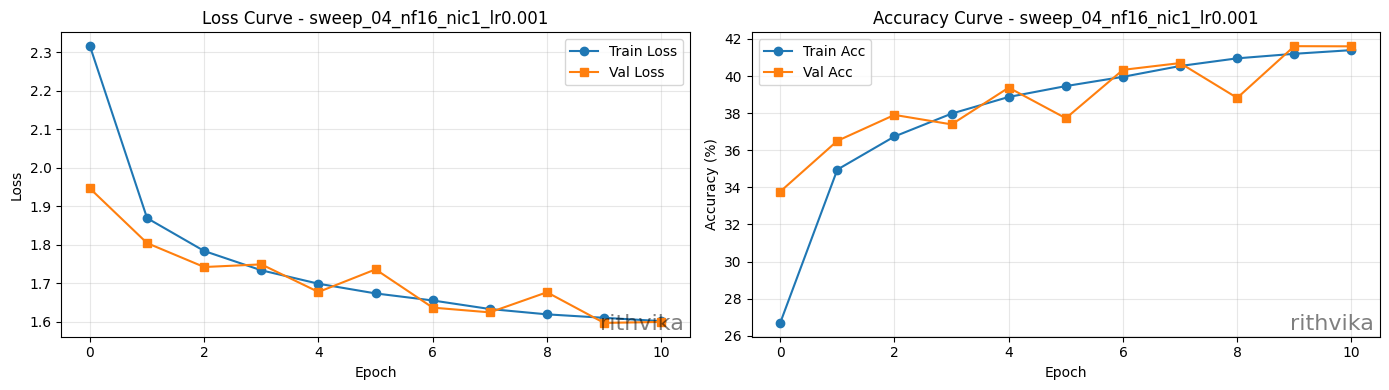

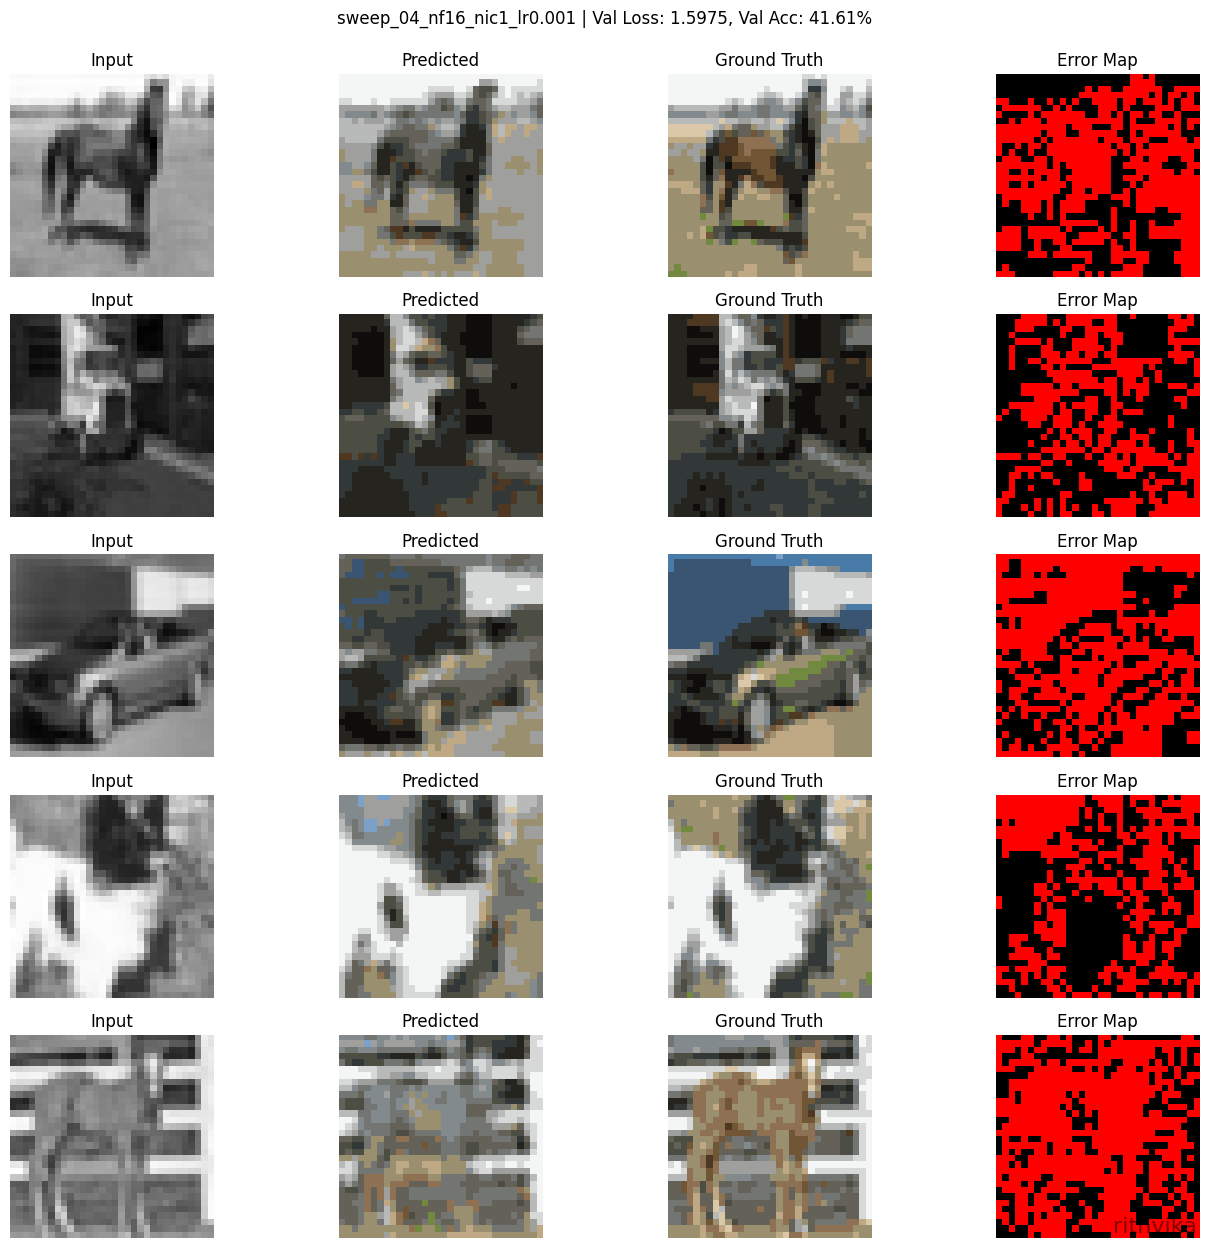

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▆▇▇▇████
wandb: train_loss █▄▃▂▂▂▂▁▁▁▁
wandb:    val_acc ▁▃▅▄▆▅▇▇▆██
wandb:   val_loss █▅▄▄▃▄▂▂▃▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 41.39837
wandb: train_loss 1.60206
wandb:    val_acc 41.60389
wandb:   val_loss 1.59993
wandb: 
wandb: 🚀 View run sweep_04_nf16_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/xyrupvla
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_104020-xyrupvla/logs



Running config 5/20: {'lr': 0.001, 'batch_size': 64, 'nf': 8, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_104700-71nml61s
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_05_nf8_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/71nml61s


Epoch 01 | TrainLoss=2.3427 | ValLoss=2.0836 | TrainAcc=23.77% | ValAcc=30.31%
  Saved best checkpoint (val_loss=2.0836)


Epoch 02 | TrainLoss=2.0665 | ValLoss=2.0090 | TrainAcc=29.87% | ValAcc=31.86%
  Saved best checkpoint (val_loss=2.0090)


...

Epoch 07 | TrainLoss=1.9681 | ValLoss=1.9524 | TrainAcc=32.01% | ValAcc=32.68%


Epoch 08 | TrainLoss=1.9580 | ValLoss=1.9278 | TrainAcc=32.32% | ValAcc=33.42%
  Saved best checkpoint (val_loss=1.9278)


Epoch 09 | TrainLoss=1.9550 | ValLoss=1.9239 | TrainAcc=32.29% | ValAcc=33.72%
  Saved best checkpoint (val_loss=1.9239)


Epoch 10 | TrainLoss=1.9510 | ValLoss=1.9132 | TrainAcc=32.40% | ValAcc=33.78%
  Saved best checkpoint (val_loss=1.9132)


Epoch 11 | TrainLoss=1.9461 | ValLoss=1.9116 | TrainAcc=32.48% | ValAcc=33.96%
  Saved best checkpoint (val_loss=1.9116)


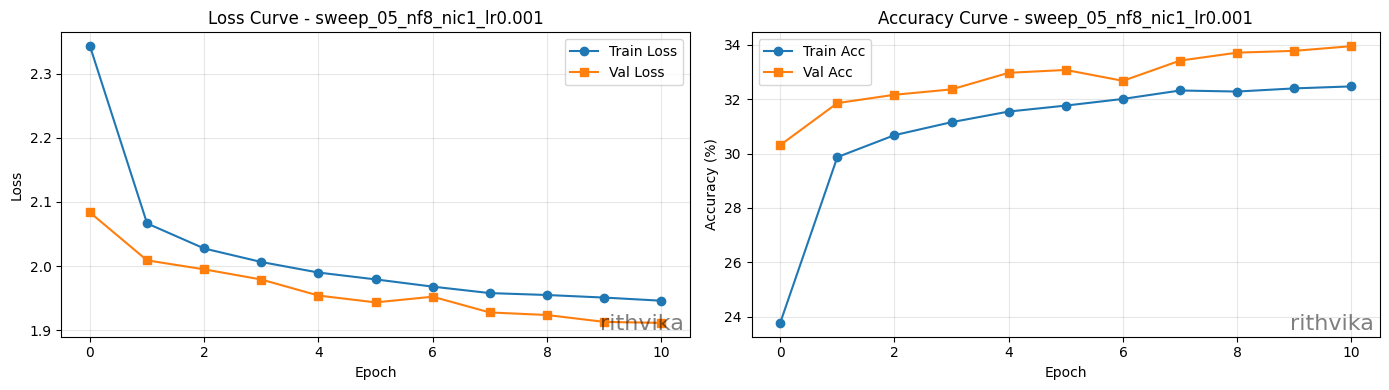

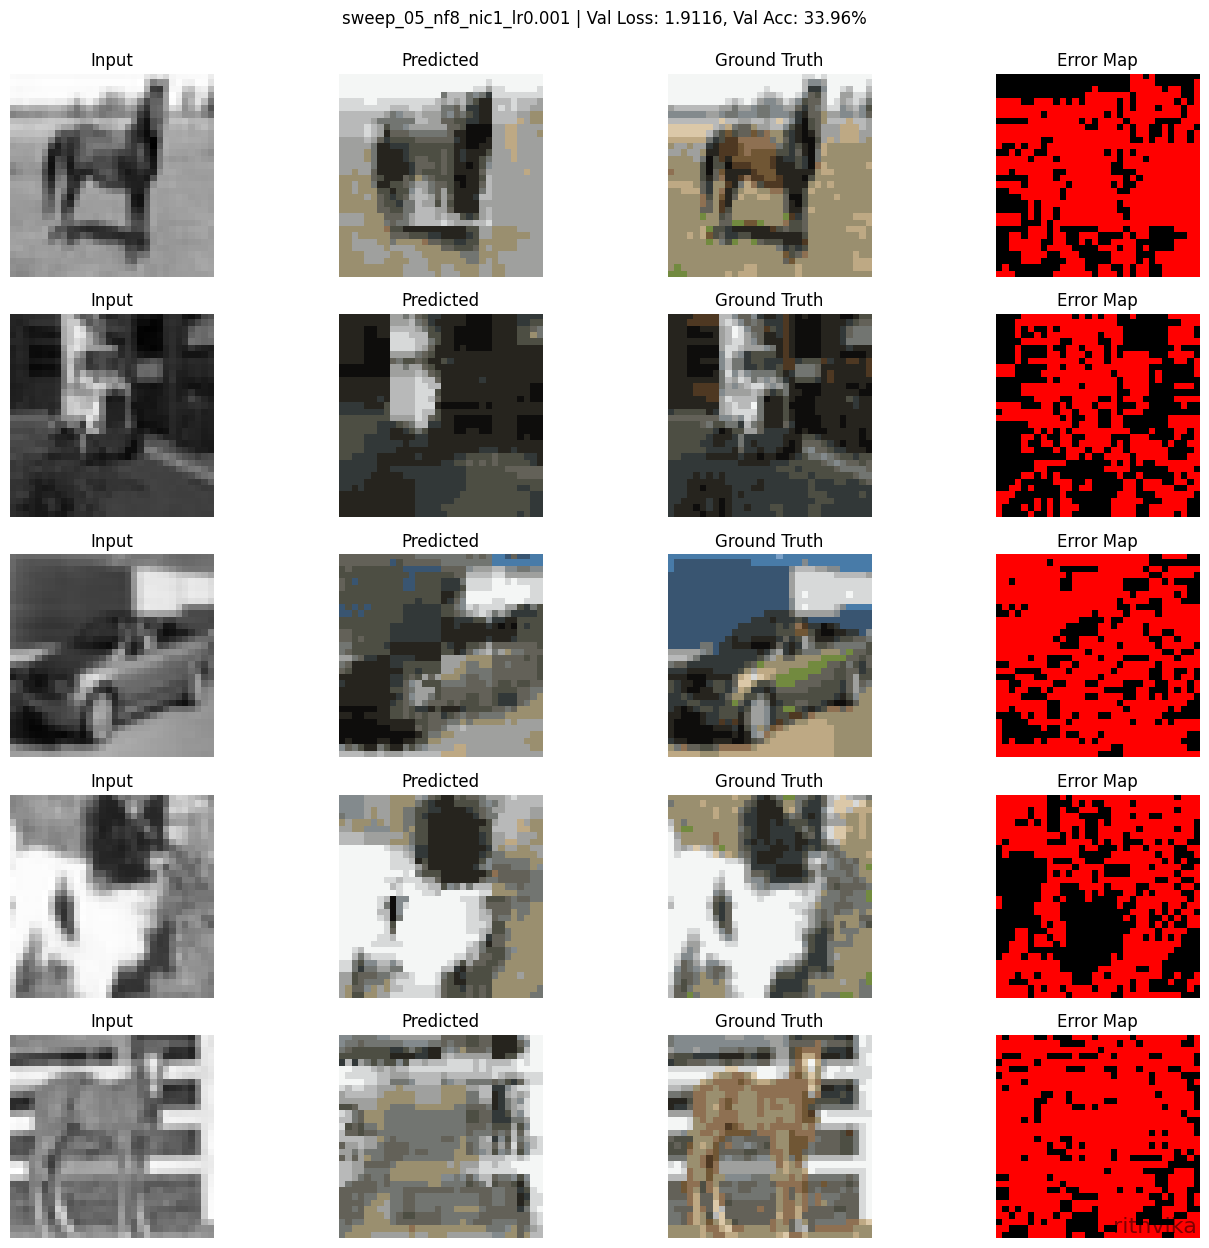

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▆▇▇▇▇█████
wandb: train_loss █▃▂▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▄▅▅▆▆▆▇███
wandb:   val_loss █▅▄▄▃▂▃▂▂▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 32.47509
wandb: train_loss 1.94613
wandb:    val_acc 33.95631
wandb:   val_loss 1.91157
wandb: 
wandb: 🚀 View run sweep_05_nf8_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/71nml61s
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_104700-71nml61s/logs



Running config 6/20: {'lr': 0.001, 'batch_size': 64, 'nf': 16, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_105349-n716fa85
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_06_nf16_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/n716fa85


Epoch 01 | TrainLoss=2.2267 | ValLoss=1.9559 | TrainAcc=26.87% | ValAcc=33.09%
  Saved best checkpoint (val_loss=1.9559)


Epoch 02 | TrainLoss=1.9476 | ValLoss=1.9162 | TrainAcc=32.69% | ValAcc=33.69%
  Saved best checkpoint (val_loss=1.9162)


...

Epoch 07 | TrainLoss=1.8179 | ValLoss=1.8392 | TrainAcc=35.70% | ValAcc=35.03%


Epoch 08 | TrainLoss=1.8106 | ValLoss=1.7739 | TrainAcc=35.91% | ValAcc=37.16%
  Saved best checkpoint (val_loss=1.7739)


Epoch 09 | TrainLoss=1.8045 | ValLoss=1.8100 | TrainAcc=36.06% | ValAcc=36.10%


Epoch 10 | TrainLoss=1.7973 | ValLoss=1.7720 | TrainAcc=36.25% | ValAcc=37.14%
  Saved best checkpoint (val_loss=1.7720)


Epoch 11 | TrainLoss=1.7907 | ValLoss=1.7601 | TrainAcc=36.41% | ValAcc=37.45%
  Saved best checkpoint (val_loss=1.7601)


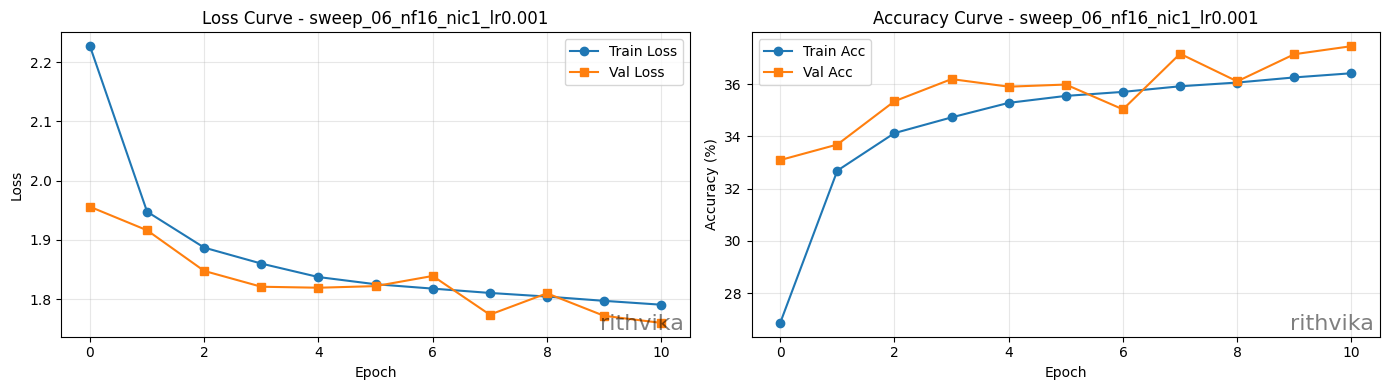

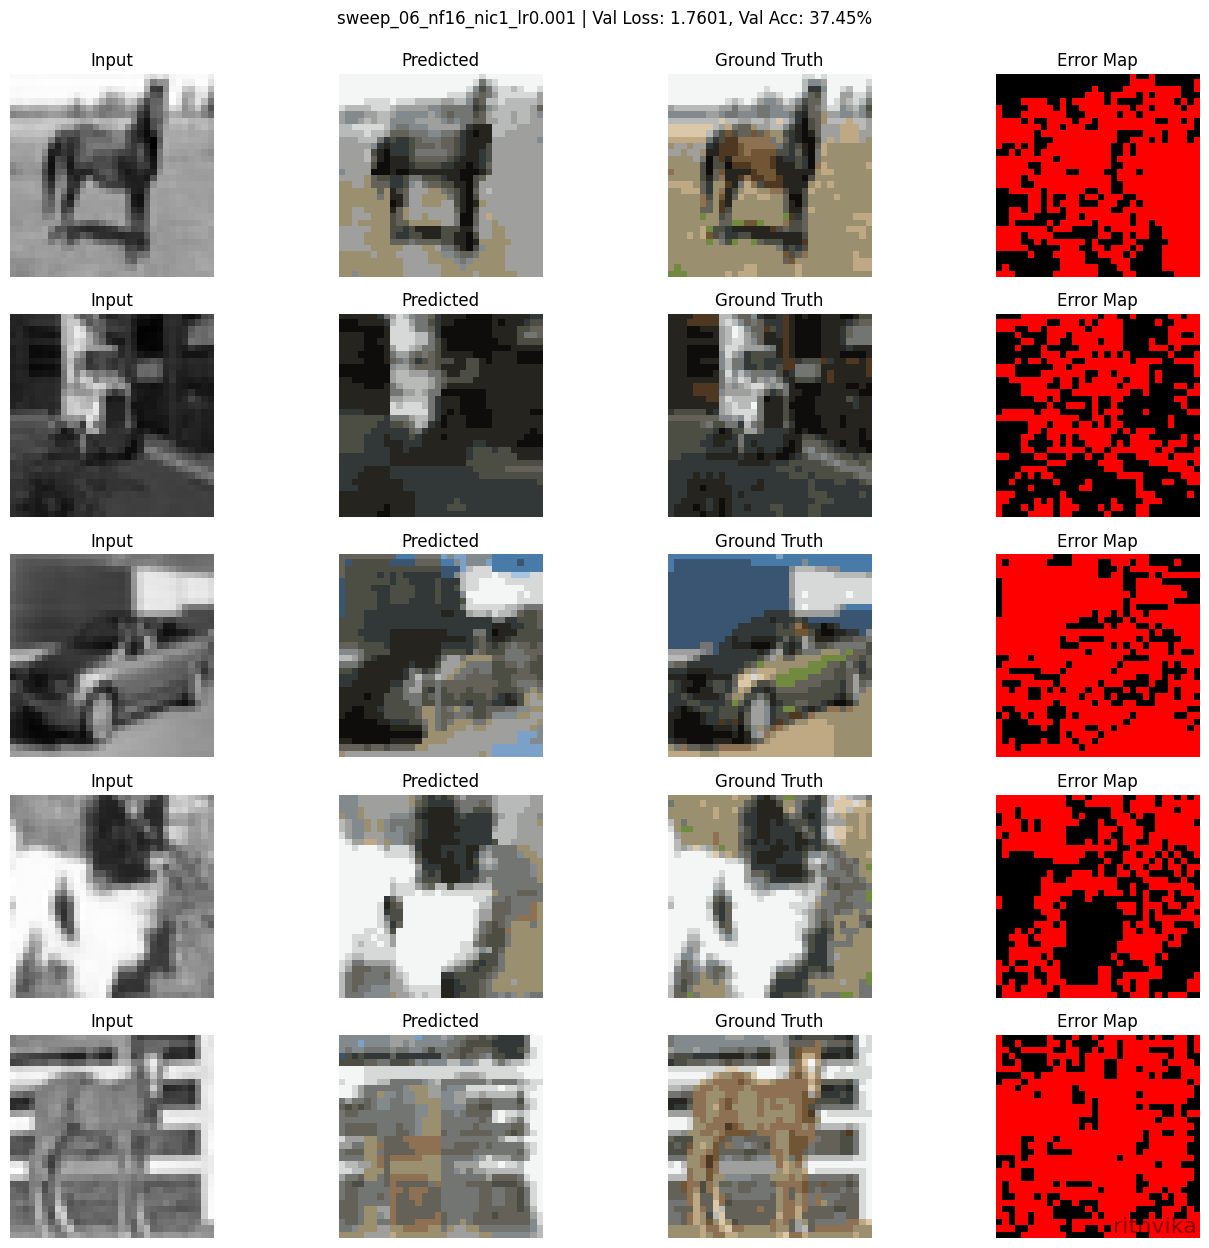

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▄▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▂▅▆▆▆▄█▆██
wandb:   val_loss █▇▄▃▃▃▄▁▃▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 36.41257
wandb: train_loss 1.79073
wandb:    val_acc 37.44777
wandb:   val_loss 1.76008
wandb: 
wandb: 🚀 View run sweep_06_nf16_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/n716fa85
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_105349-n716fa85/logs



Running config 7/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_110040-yavswddw
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_07_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/yavswddw


Epoch 01 | TrainLoss=2.2413 | ValLoss=1.9169 | TrainAcc=28.38% | ValAcc=33.92%
  Saved best checkpoint (val_loss=1.9169)


Epoch 02 | TrainLoss=1.8507 | ValLoss=1.8109 | TrainAcc=35.47% | ValAcc=36.44%
  Saved best checkpoint (val_loss=1.8109)


...

Epoch 07 | TrainLoss=1.6951 | ValLoss=1.6742 | TrainAcc=39.05% | ValAcc=39.76%
  Saved best checkpoint (val_loss=1.6742)


Epoch 08 | TrainLoss=1.6777 | ValLoss=1.6694 | TrainAcc=39.54% | ValAcc=39.55%
  Saved best checkpoint (val_loss=1.6694)


Epoch 09 | TrainLoss=1.6705 | ValLoss=1.6542 | TrainAcc=39.70% | ValAcc=40.12%
  Saved best checkpoint (val_loss=1.6542)


Epoch 10 | TrainLoss=1.6638 | ValLoss=1.6886 | TrainAcc=39.87% | ValAcc=38.88%


Epoch 11 | TrainLoss=1.6619 | ValLoss=1.6450 | TrainAcc=39.90% | ValAcc=40.51%
  Saved best checkpoint (val_loss=1.6450)


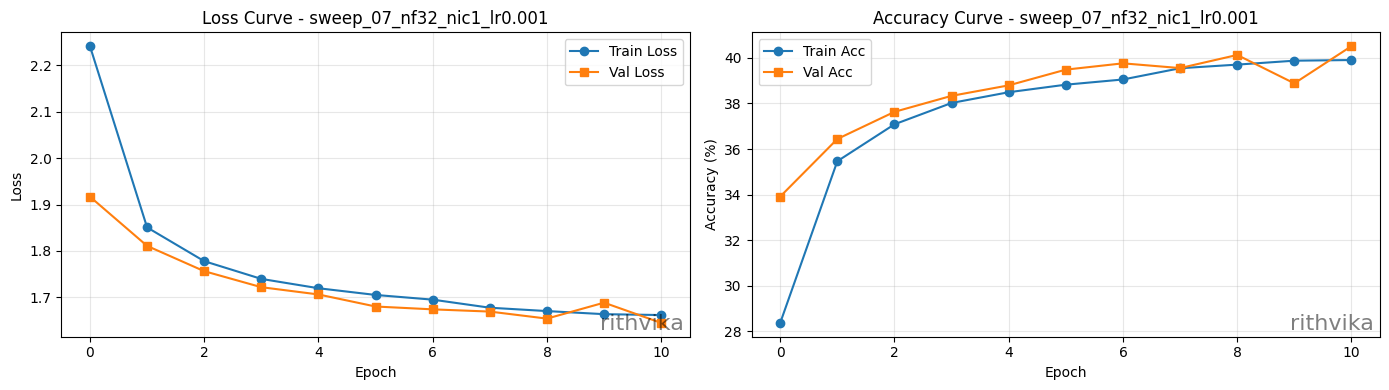

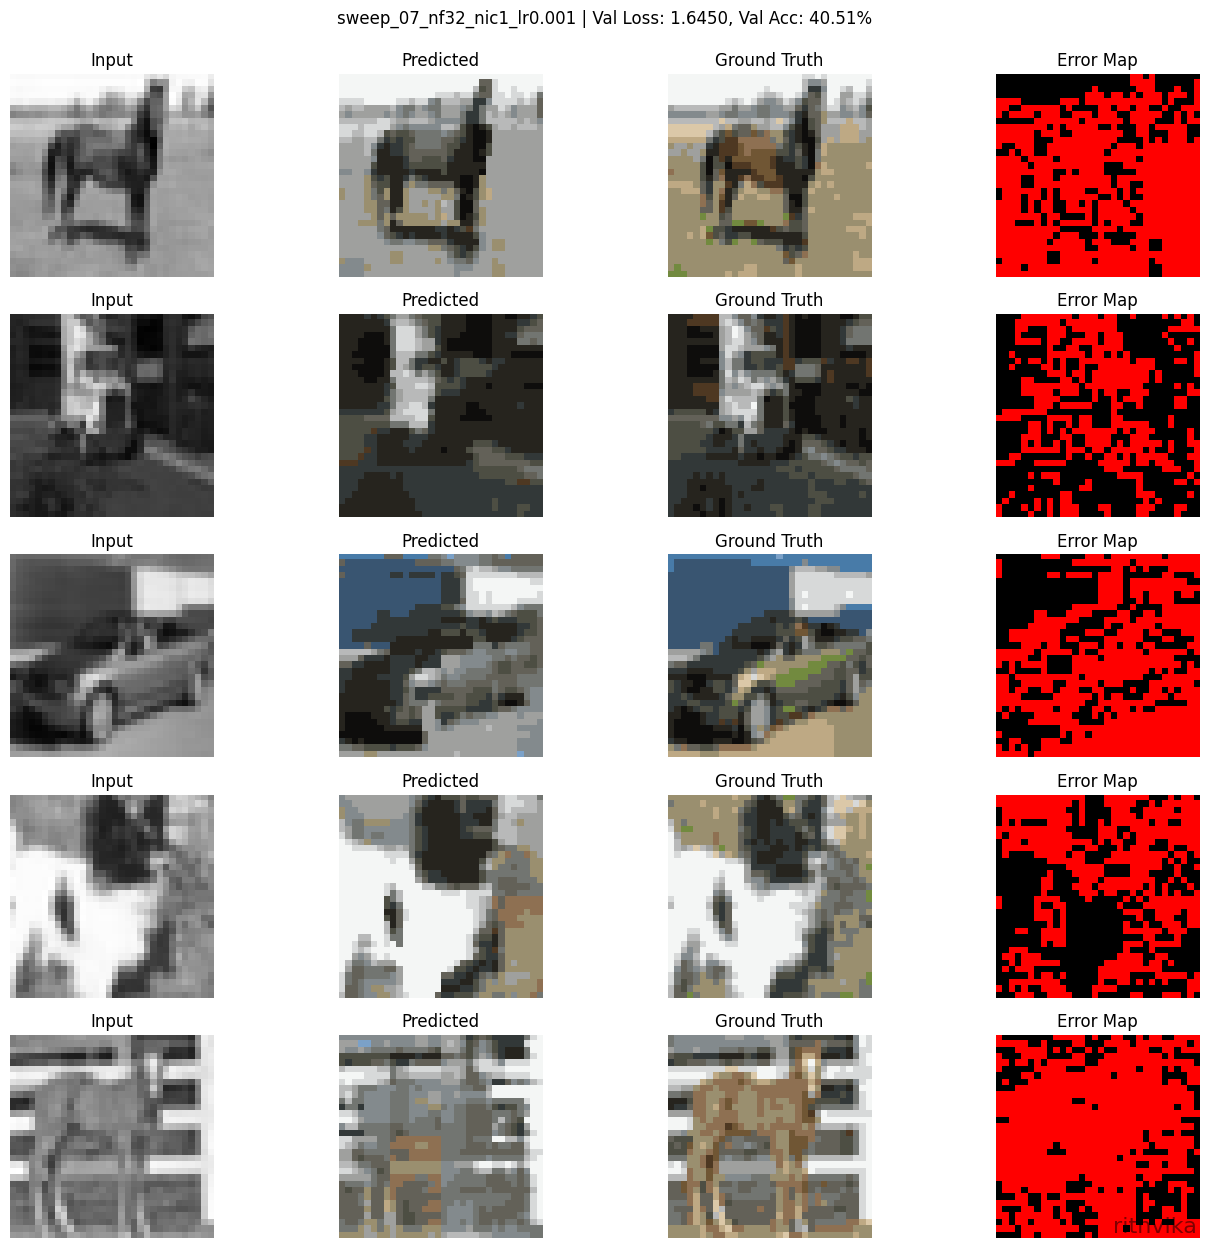

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▃▂▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▄▅▆▆▇▇▇█▆█
wandb:   val_loss █▅▄▃▃▂▂▂▁▂▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 39.90157
wandb: train_loss 1.6619
wandb:    val_acc 40.50962
wandb:   val_loss 1.64501
wandb: 
wandb: 🚀 View run sweep_07_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/yavswddw
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_110040-yavswddw/logs



Running config 8/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_110724-vh12vp8a
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_08_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/vh12vp8a


Epoch 01 | TrainLoss=2.2107 | ValLoss=1.8834 | TrainAcc=29.12% | ValAcc=35.50%
  Saved best checkpoint (val_loss=1.8834)


Epoch 02 | TrainLoss=1.8415 | ValLoss=1.8027 | TrainAcc=35.80% | ValAcc=36.41%
  Saved best checkpoint (val_loss=1.8027)


...

Epoch 07 | TrainLoss=1.6888 | ValLoss=1.7104 | TrainAcc=39.22% | ValAcc=38.30%


Epoch 08 | TrainLoss=1.6772 | ValLoss=1.6839 | TrainAcc=39.52% | ValAcc=39.26%
  Saved best checkpoint (val_loss=1.6839)


Epoch 09 | TrainLoss=1.6750 | ValLoss=1.6787 | TrainAcc=39.56% | ValAcc=39.37%
  Saved best checkpoint (val_loss=1.6787)


Epoch 10 | TrainLoss=1.6672 | ValLoss=1.6596 | TrainAcc=39.74% | ValAcc=39.94%
  Saved best checkpoint (val_loss=1.6596)


Epoch 11 | TrainLoss=1.6566 | ValLoss=1.6446 | TrainAcc=40.07% | ValAcc=40.46%
  Saved best checkpoint (val_loss=1.6446)


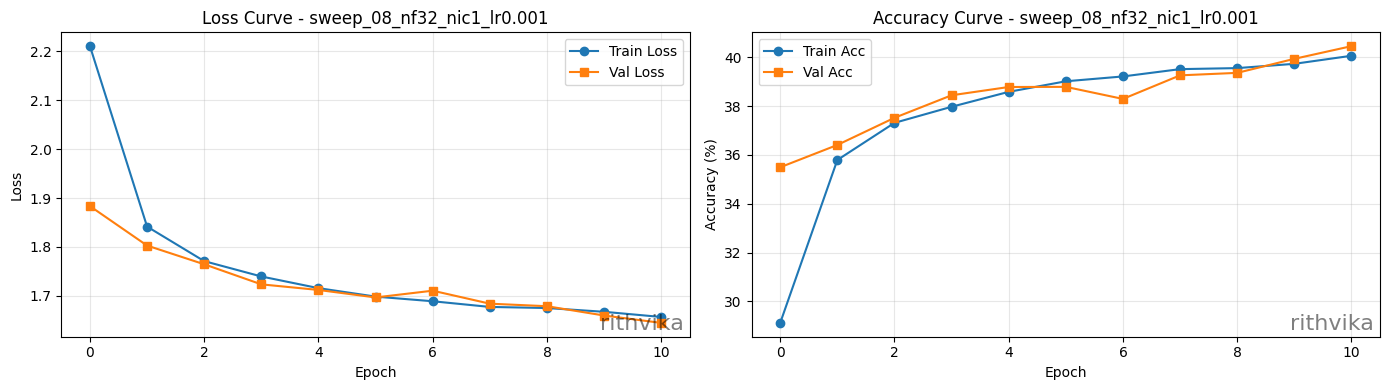

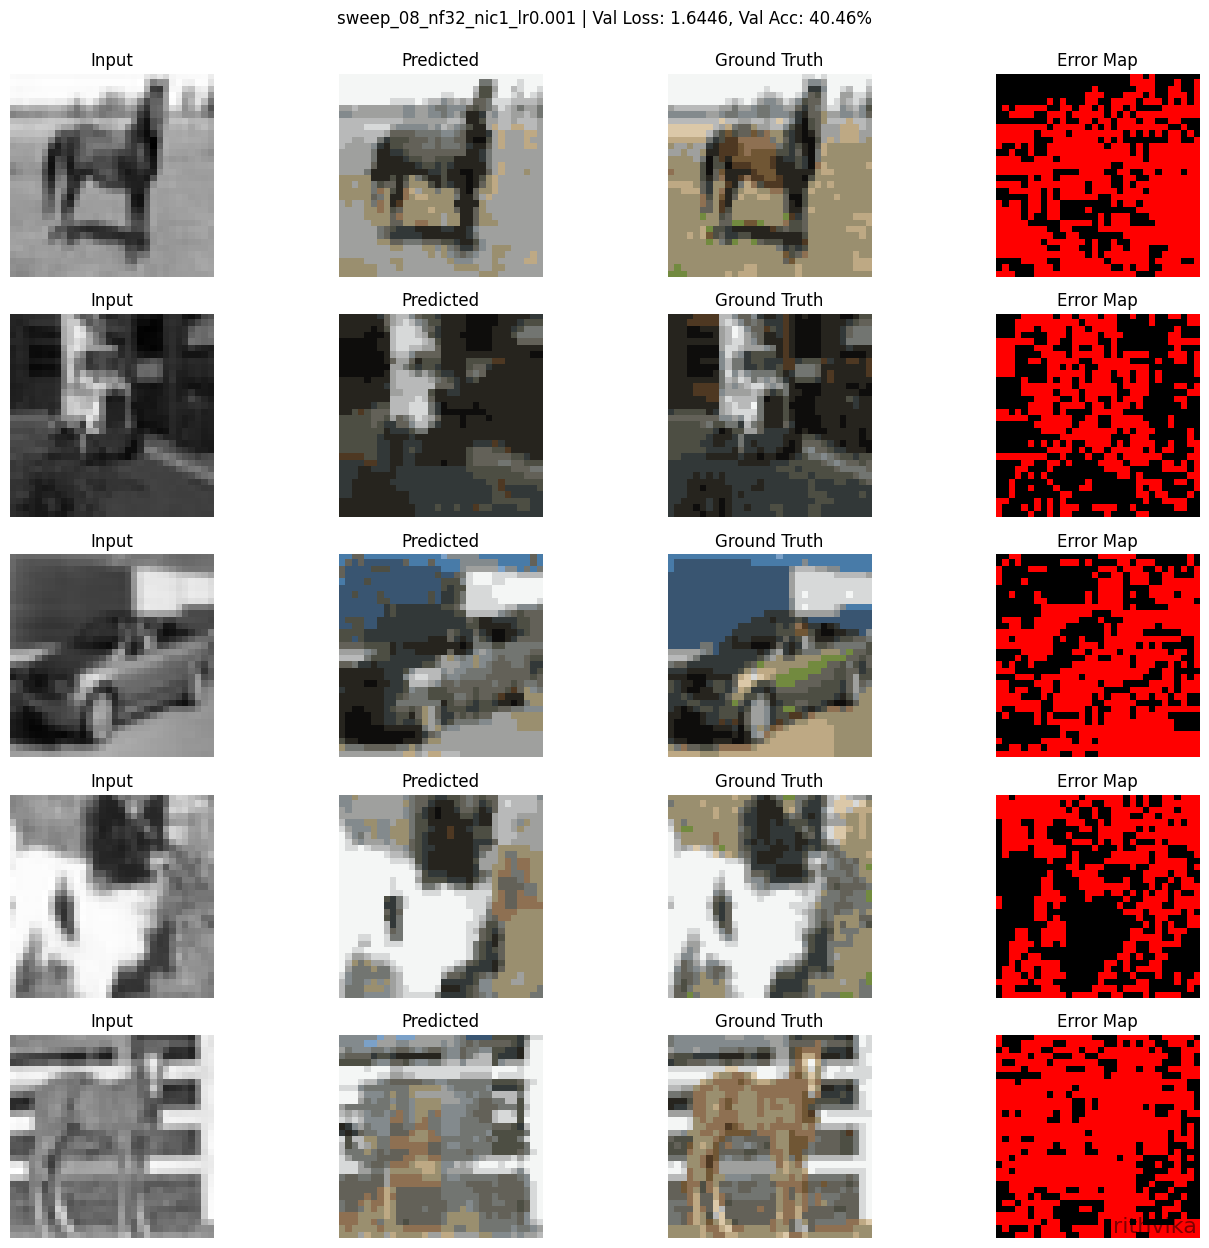

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▃▂▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▂▄▅▆▆▅▆▆▇█
wandb:   val_loss █▆▅▃▃▃▃▂▂▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 40.06723
wandb: train_loss 1.65664
wandb:    val_acc 40.46061
wandb:   val_loss 1.64456
wandb: 
wandb: 🚀 View run sweep_08_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/vh12vp8a
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_110724-vh12vp8a/logs



Running config 9/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_111406-45w8r04j
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_09_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/45w8r04j


Epoch 01 | TrainLoss=2.1127 | ValLoss=1.8566 | TrainAcc=30.03% | ValAcc=35.12%
  Saved best checkpoint (val_loss=1.8566)


Epoch 02 | TrainLoss=1.8242 | ValLoss=1.7572 | TrainAcc=35.69% | ValAcc=37.95%
  Saved best checkpoint (val_loss=1.7572)


...

Epoch 07 | TrainLoss=1.6989 | ValLoss=1.7358 | TrainAcc=38.76% | ValAcc=37.77%


Epoch 08 | TrainLoss=1.6915 | ValLoss=1.6871 | TrainAcc=38.90% | ValAcc=39.00%


Epoch 09 | TrainLoss=1.6805 | ValLoss=1.7041 | TrainAcc=39.20% | ValAcc=38.87%


Epoch 10 | TrainLoss=1.6765 | ValLoss=1.6390 | TrainAcc=39.31% | ValAcc=40.64%
  Saved best checkpoint (val_loss=1.6390)


Epoch 11 | TrainLoss=1.6682 | ValLoss=1.6404 | TrainAcc=39.50% | ValAcc=40.47%


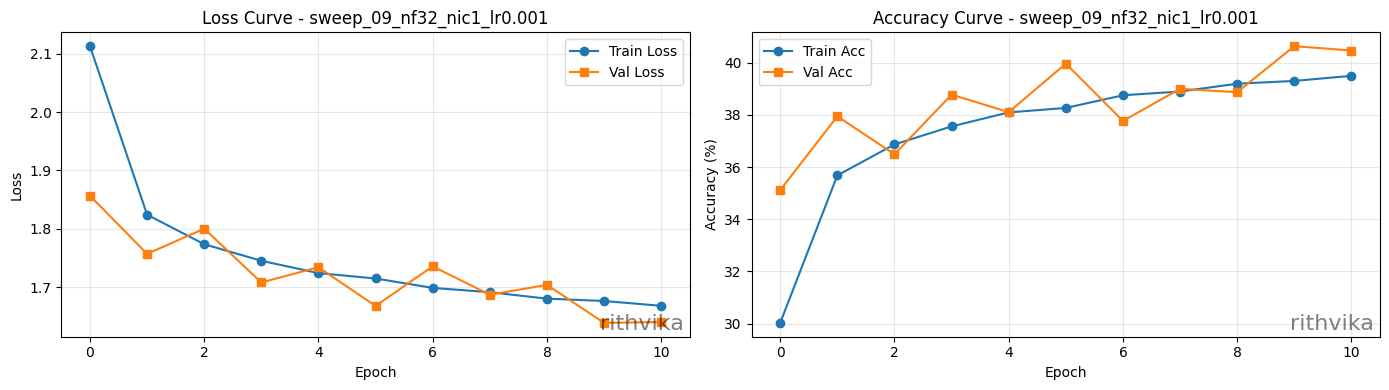

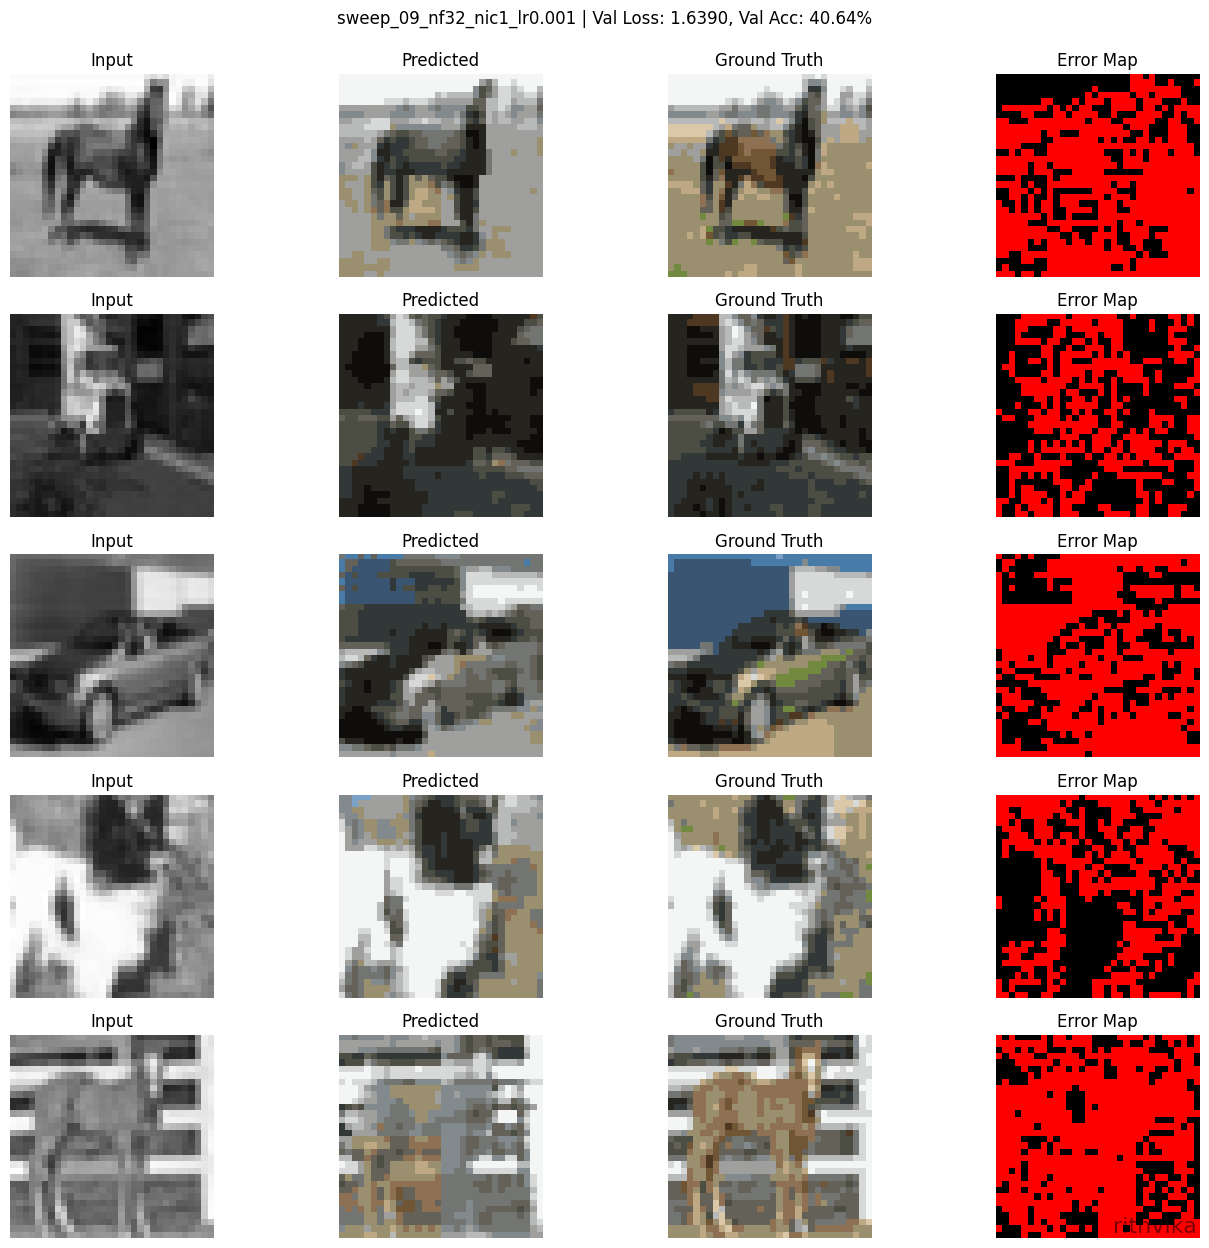

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▃▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▅▃▆▅▇▄▆▆██
wandb:   val_loss █▅▆▃▄▂▄▃▃▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 39.5017
wandb: train_loss 1.66818
wandb:    val_acc 40.47179
wandb:   val_loss 1.64041
wandb: 
wandb: 🚀 View run sweep_09_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/45w8r04j
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_111406-45w8r04j/logs



Running config 10/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_112109-nxiywwku
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_10_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/nxiywwku


Epoch 01 | TrainLoss=2.0924 | ValLoss=1.8581 | TrainAcc=30.94% | ValAcc=34.98%
  Saved best checkpoint (val_loss=1.8581)


Epoch 02 | TrainLoss=1.8175 | ValLoss=1.7936 | TrainAcc=35.83% | ValAcc=36.61%
  Saved best checkpoint (val_loss=1.7936)


...

Epoch 07 | TrainLoss=1.6985 | ValLoss=1.6850 | TrainAcc=38.75% | ValAcc=39.50%


Epoch 08 | TrainLoss=1.6912 | ValLoss=1.6734 | TrainAcc=38.92% | ValAcc=39.77%
  Saved best checkpoint (val_loss=1.6734)


Epoch 09 | TrainLoss=1.6858 | ValLoss=1.6718 | TrainAcc=39.08% | ValAcc=39.54%
  Saved best checkpoint (val_loss=1.6718)


Epoch 10 | TrainLoss=1.6752 | ValLoss=1.6828 | TrainAcc=39.41% | ValAcc=39.08%


Epoch 11 | TrainLoss=1.6686 | ValLoss=1.6349 | TrainAcc=39.58% | ValAcc=40.64%
  Saved best checkpoint (val_loss=1.6349)


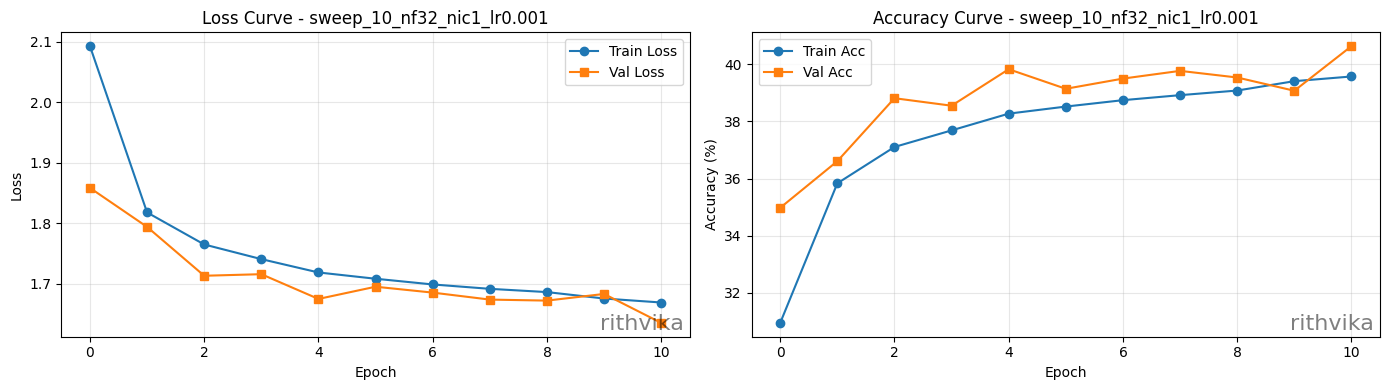

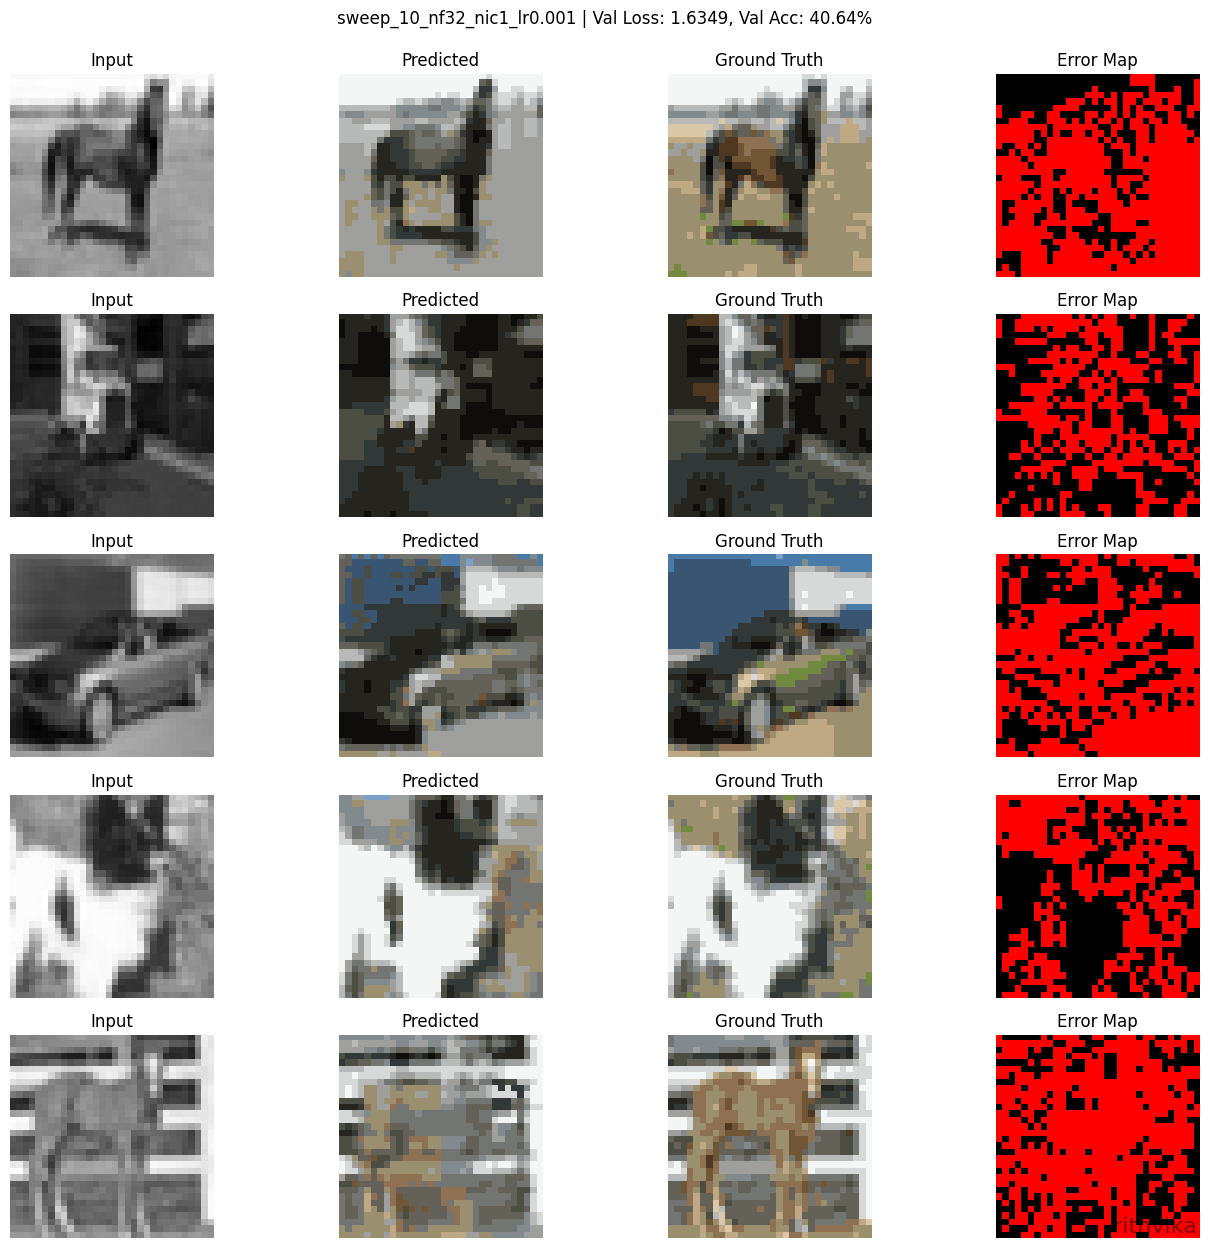

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▆▇▇▇▇███
wandb: train_loss █▃▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▃▆▅▇▆▇▇▇▆█
wandb:   val_loss █▆▃▄▂▃▃▂▂▃▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 39.57641
wandb: train_loss 1.66863
wandb:    val_acc 40.63844
wandb:   val_loss 1.63492
wandb: 
wandb: 🚀 View run sweep_10_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/nxiywwku
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_112109-nxiywwku/logs



Running config 11/20: {'lr': 0.0003, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_112810-ph9sm9vj
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_11_nf32_nic1_lr0.0003
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ph9sm9vj


Epoch 01 | TrainLoss=2.5949 | ValLoss=2.2063 | TrainAcc=22.41% | ValAcc=31.42%
  Saved best checkpoint (val_loss=2.2063)


Epoch 02 | TrainLoss=2.0747 | ValLoss=1.9842 | TrainAcc=32.72% | ValAcc=33.88%
  Saved best checkpoint (val_loss=1.9842)


...

Epoch 07 | TrainLoss=1.7661 | ValLoss=1.7412 | TrainAcc=37.62% | ValAcc=38.36%
  Saved best checkpoint (val_loss=1.7412)


Epoch 08 | TrainLoss=1.7465 | ValLoss=1.7397 | TrainAcc=38.07% | ValAcc=38.18%
  Saved best checkpoint (val_loss=1.7397)


Epoch 09 | TrainLoss=1.7303 | ValLoss=1.7201 | TrainAcc=38.47% | ValAcc=38.75%
  Saved best checkpoint (val_loss=1.7201)


Epoch 10 | TrainLoss=1.7241 | ValLoss=1.7251 | TrainAcc=38.53% | ValAcc=38.39%


Epoch 11 | TrainLoss=1.7143 | ValLoss=1.7153 | TrainAcc=38.78% | ValAcc=38.63%
  Saved best checkpoint (val_loss=1.7153)


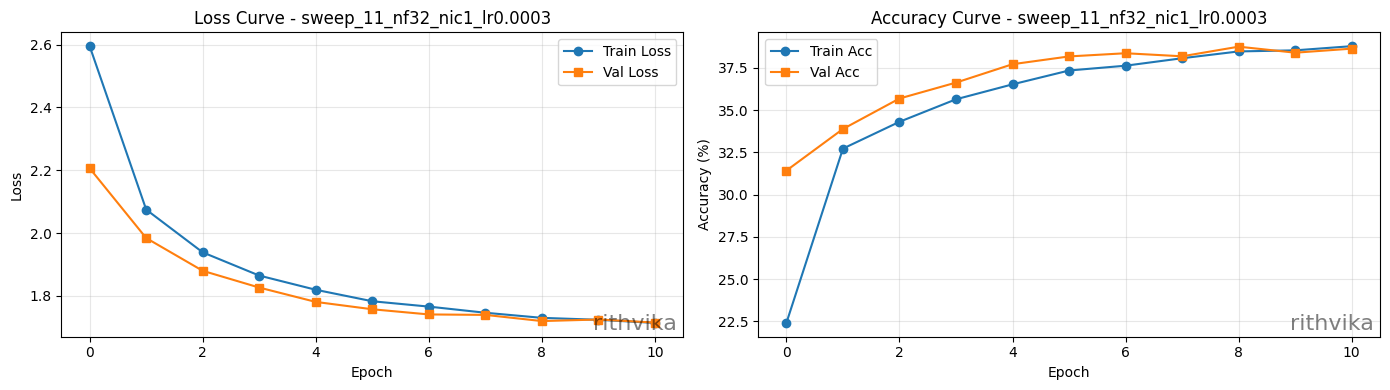

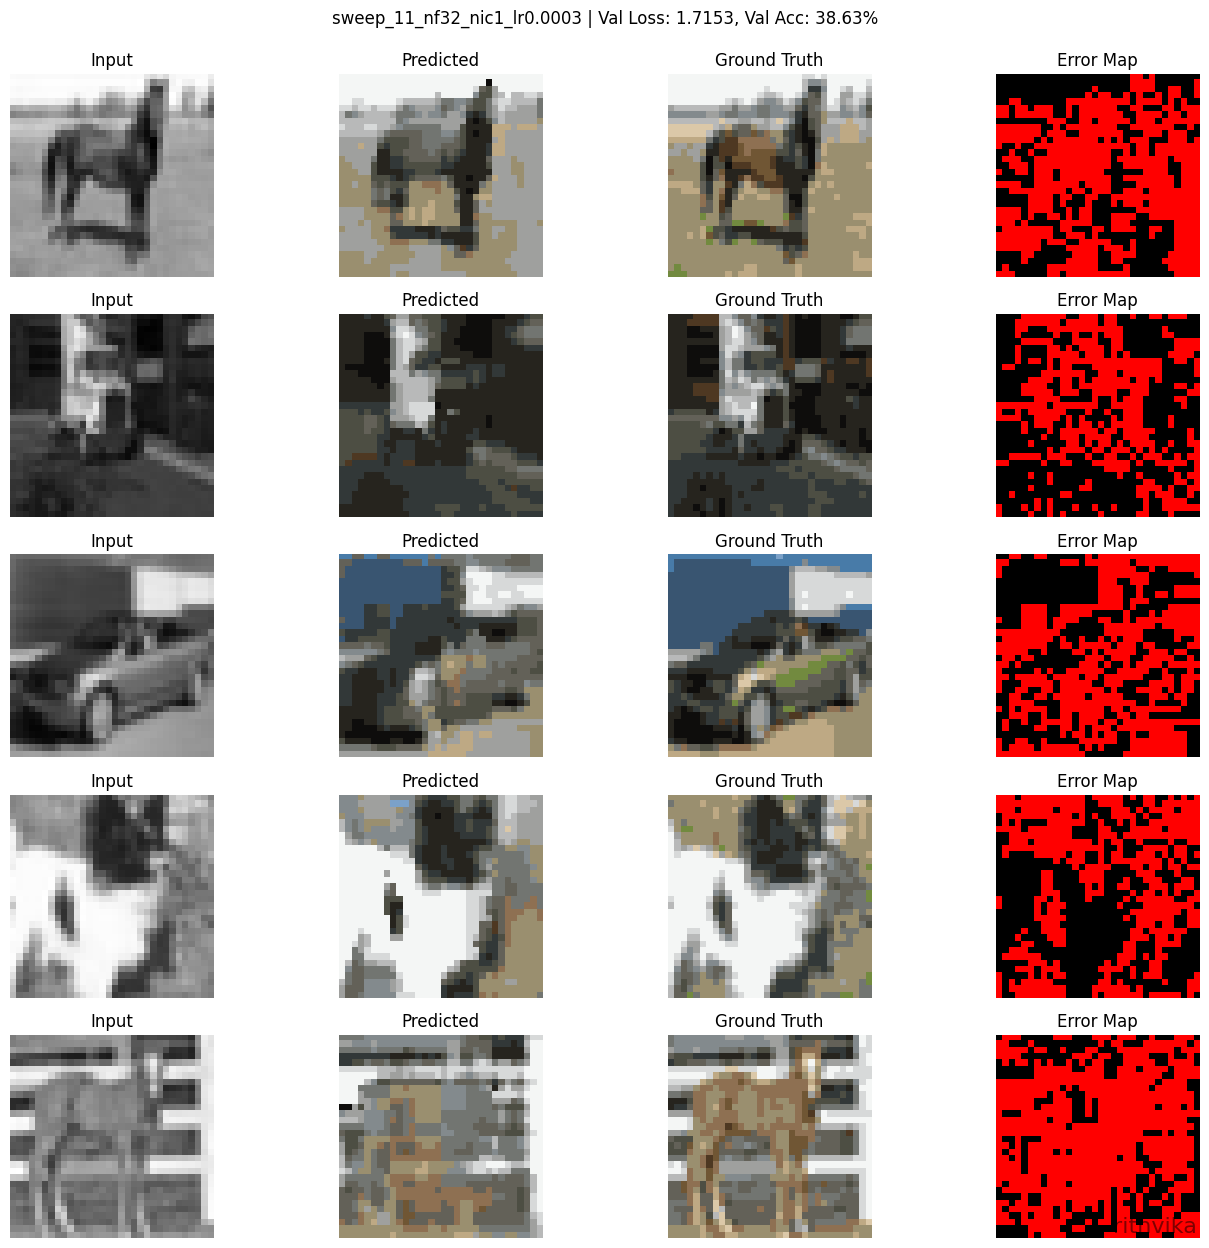

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇█████
wandb: train_loss █▄▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▃▅▆▇▇█▇███
wandb:   val_loss █▅▃▃▂▂▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 38.77903
wandb: train_loss 1.71428
wandb:    val_acc 38.63262
wandb:   val_loss 1.71529
wandb: 
wandb: 🚀 View run sweep_11_nf32_nic1_lr0.0003 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ph9sm9vj
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_112810-ph9sm9vj/logs



Running config 12/20: {'lr': 0.0001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_113455-ueggmuun
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_12_nf32_nic1_lr0.0001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ueggmuun


Epoch 01 | TrainLoss=2.7036 | ValLoss=2.3672 | TrainAcc=20.02% | ValAcc=28.52%
  Saved best checkpoint (val_loss=2.3672)


Epoch 02 | TrainLoss=2.2411 | ValLoss=2.1212 | TrainAcc=30.03% | ValAcc=32.72%
  Saved best checkpoint (val_loss=2.1212)


...

Epoch 07 | TrainLoss=1.8562 | ValLoss=1.8179 | TrainAcc=35.47% | ValAcc=36.95%
  Saved best checkpoint (val_loss=1.8179)


Epoch 08 | TrainLoss=1.8346 | ValLoss=1.7924 | TrainAcc=35.85% | ValAcc=37.22%
  Saved best checkpoint (val_loss=1.7924)


Epoch 09 | TrainLoss=1.8163 | ValLoss=1.7705 | TrainAcc=36.26% | ValAcc=37.85%
  Saved best checkpoint (val_loss=1.7705)


Epoch 10 | TrainLoss=1.7983 | ValLoss=1.7652 | TrainAcc=36.66% | ValAcc=38.01%
  Saved best checkpoint (val_loss=1.7652)


Epoch 11 | TrainLoss=1.7888 | ValLoss=1.7494 | TrainAcc=36.83% | ValAcc=38.17%
  Saved best checkpoint (val_loss=1.7494)


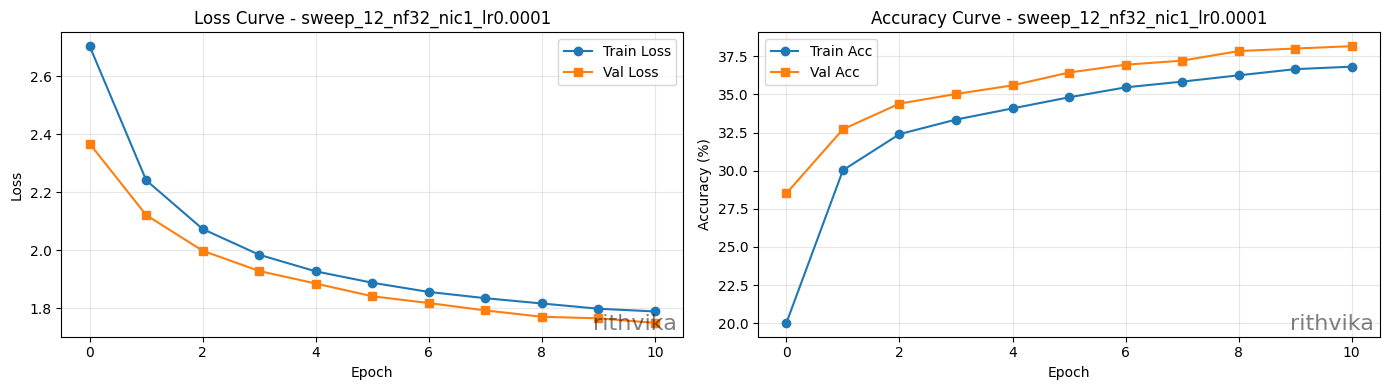

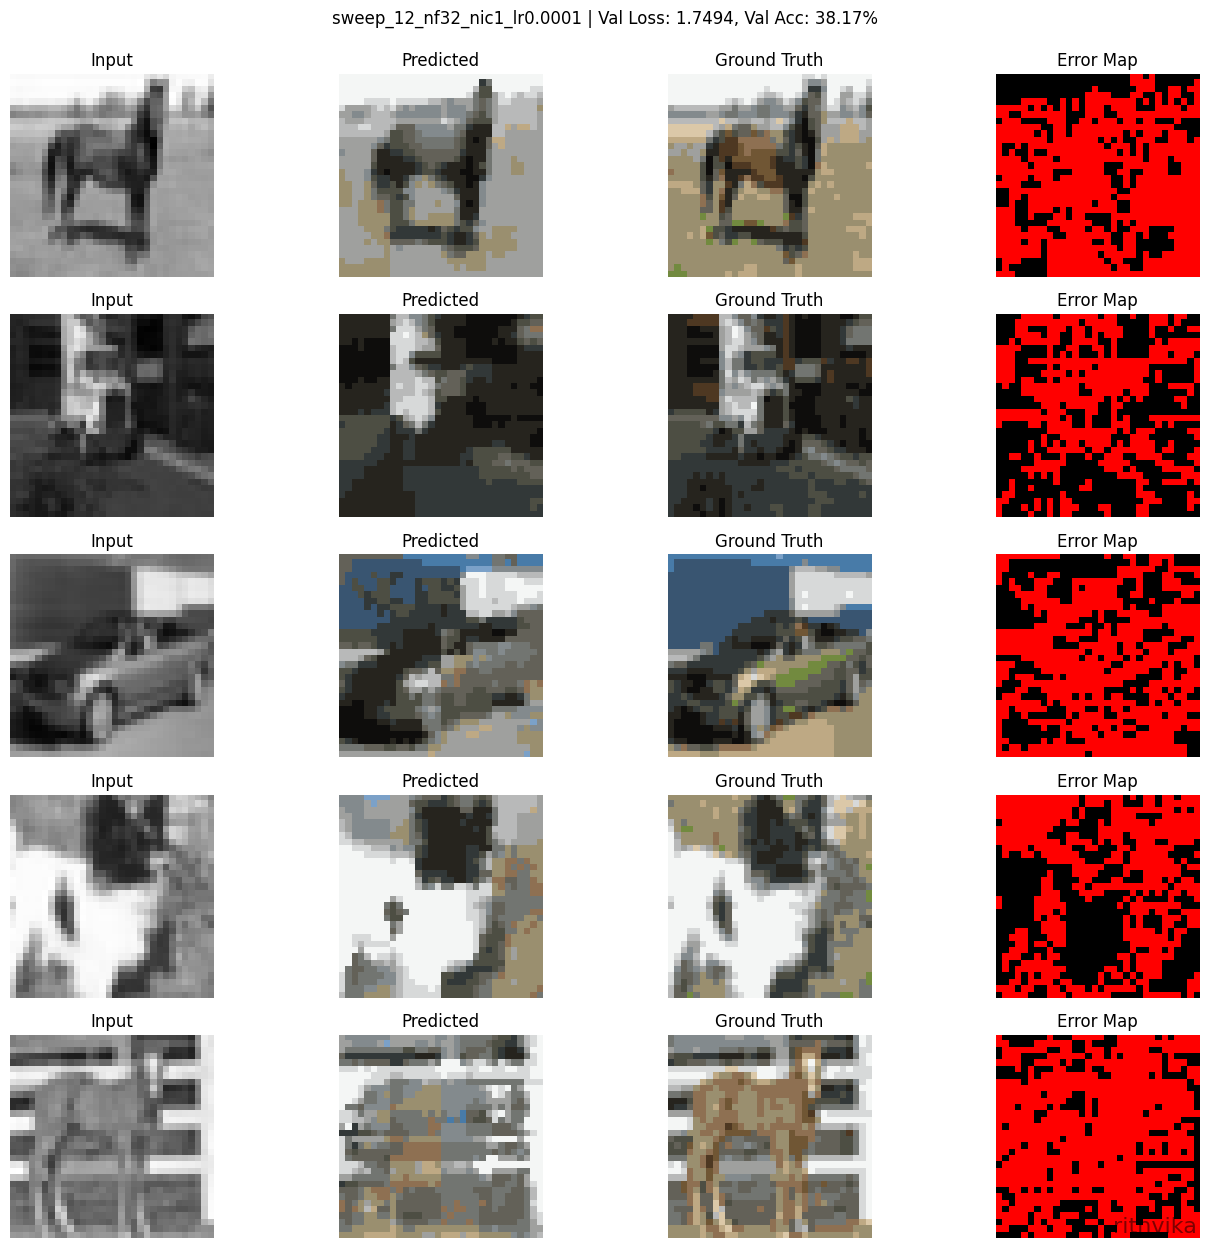

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▄▃▂▂▂▂▁▁▁▁
wandb:    val_acc ▁▄▅▆▆▇▇▇███
wandb:   val_loss █▅▄▃▃▂▂▁▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 36.82699
wandb: train_loss 1.78883
wandb:    val_acc 38.17
wandb:   val_loss 1.74945
wandb: 
wandb: 🚀 View run sweep_12_nf32_nic1_lr0.0001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ueggmuun
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_113455-ueggmuun/logs



Running config 13/20: {'lr': 0.0003, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_114200-04jx8jgu
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_13_nf32_nic1_lr0.0003
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/04jx8jgu


Epoch 01 | TrainLoss=2.3818 | ValLoss=2.0296 | TrainAcc=26.81% | ValAcc=32.67%
  Saved best checkpoint (val_loss=2.0296)


Epoch 02 | TrainLoss=1.9542 | ValLoss=1.8647 | TrainAcc=33.64% | ValAcc=35.81%
  Saved best checkpoint (val_loss=1.8647)


...

Epoch 07 | TrainLoss=1.7499 | ValLoss=1.7192 | TrainAcc=37.69% | ValAcc=38.71%
  Saved best checkpoint (val_loss=1.7192)


Epoch 08 | TrainLoss=1.7366 | ValLoss=1.6988 | TrainAcc=37.99% | ValAcc=39.37%
  Saved best checkpoint (val_loss=1.6988)


Epoch 09 | TrainLoss=1.7287 | ValLoss=1.6902 | TrainAcc=38.16% | ValAcc=39.50%
  Saved best checkpoint (val_loss=1.6902)


Epoch 10 | TrainLoss=1.7182 | ValLoss=1.6881 | TrainAcc=38.46% | ValAcc=39.62%
  Saved best checkpoint (val_loss=1.6881)


Epoch 11 | TrainLoss=1.7097 | ValLoss=1.6799 | TrainAcc=38.66% | ValAcc=39.78%
  Saved best checkpoint (val_loss=1.6799)


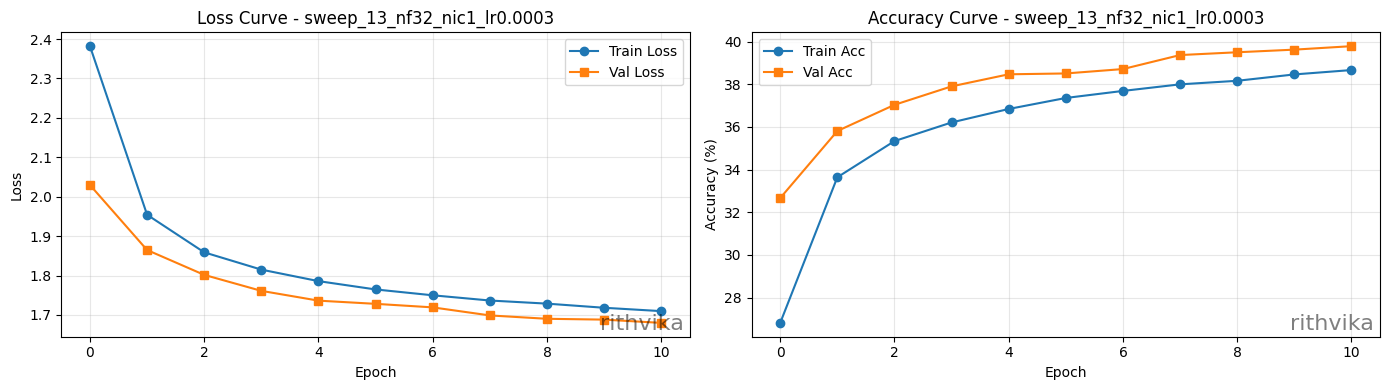

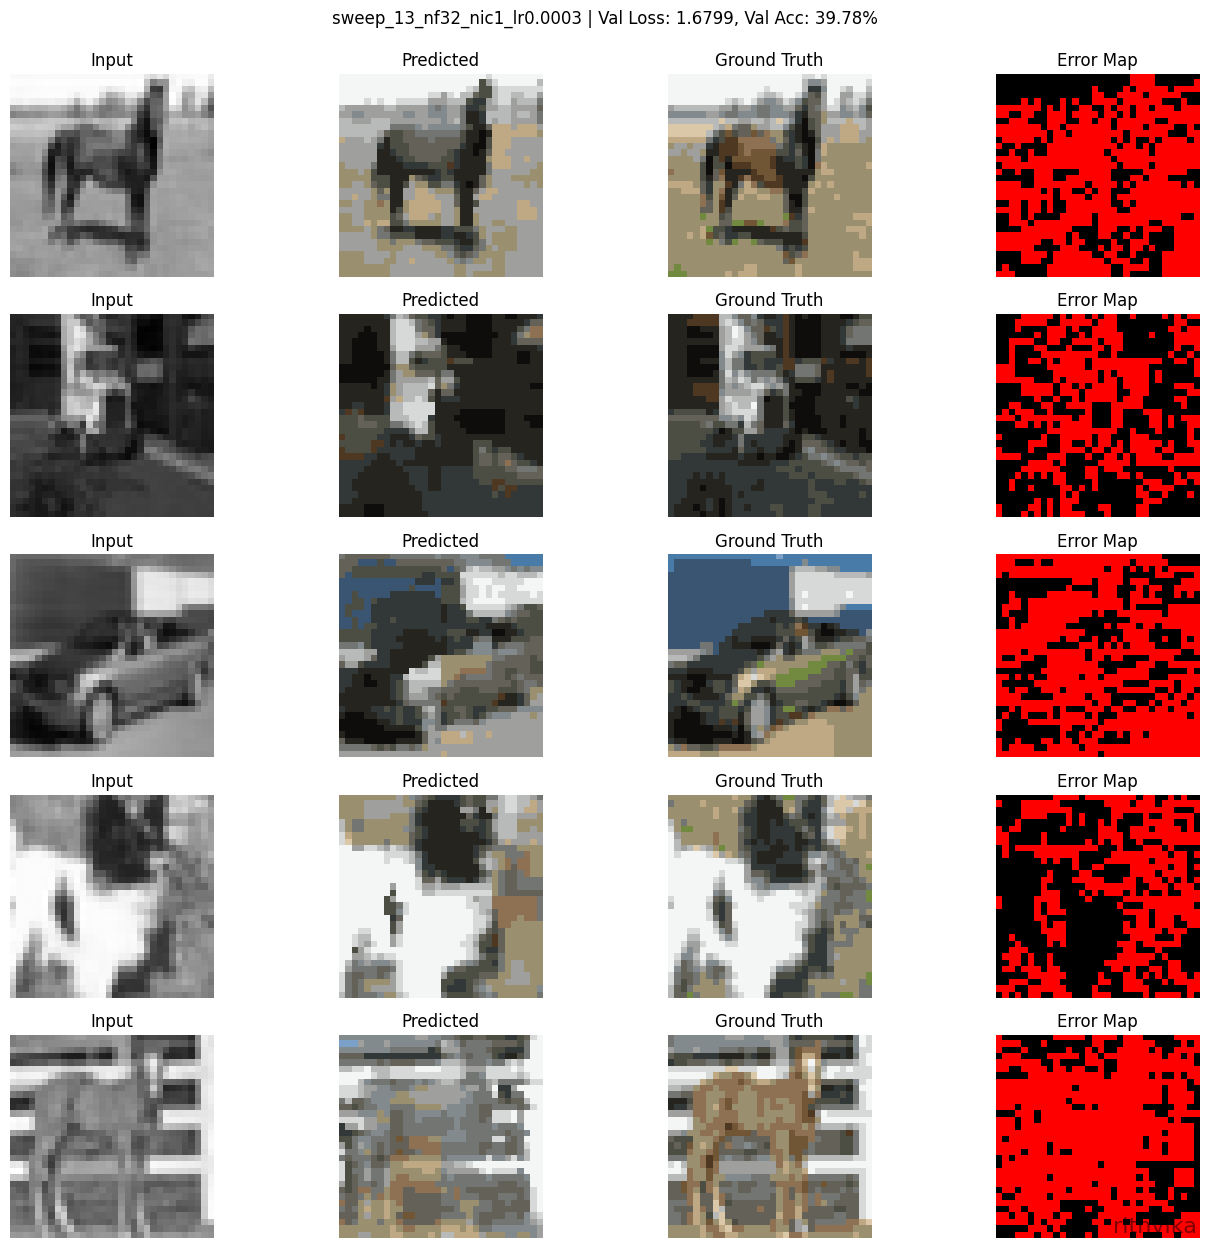

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▄▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▄▅▆▇▇▇████
wandb:   val_loss █▅▃▃▂▂▂▁▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 38.66475
wandb: train_loss 1.70969
wandb:    val_acc 39.78441
wandb:   val_loss 1.67986
wandb: 
wandb: 🚀 View run sweep_13_nf32_nic1_lr0.0003 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/04jx8jgu
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_114200-04jx8jgu/logs



Running config 14/20: {'lr': 0.003, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_114907-p2cuyvep
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_14_nf32_nic1_lr0.003
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/p2cuyvep


Epoch 01 | TrainLoss=1.9848 | ValLoss=1.8486 | TrainAcc=32.14% | ValAcc=34.88%
  Saved best checkpoint (val_loss=1.8486)


Epoch 02 | TrainLoss=1.7854 | ValLoss=1.7527 | TrainAcc=36.44% | ValAcc=37.50%
  Saved best checkpoint (val_loss=1.7527)


...

Epoch 07 | TrainLoss=1.6858 | ValLoss=1.6930 | TrainAcc=38.94% | ValAcc=38.12%


Epoch 08 | TrainLoss=1.6725 | ValLoss=1.6560 | TrainAcc=39.35% | ValAcc=39.57%
  Saved best checkpoint (val_loss=1.6560)


Epoch 09 | TrainLoss=1.6680 | ValLoss=1.7041 | TrainAcc=39.46% | ValAcc=38.61%


Epoch 10 | TrainLoss=1.6530 | ValLoss=1.6402 | TrainAcc=39.92% | ValAcc=40.49%
  Saved best checkpoint (val_loss=1.6402)


Epoch 11 | TrainLoss=1.6531 | ValLoss=1.6307 | TrainAcc=39.90% | ValAcc=40.69%
  Saved best checkpoint (val_loss=1.6307)


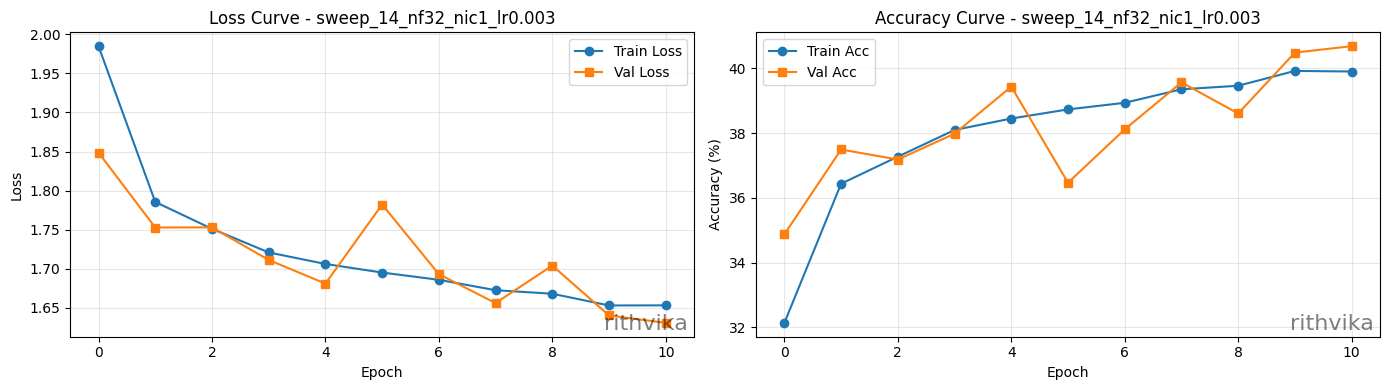

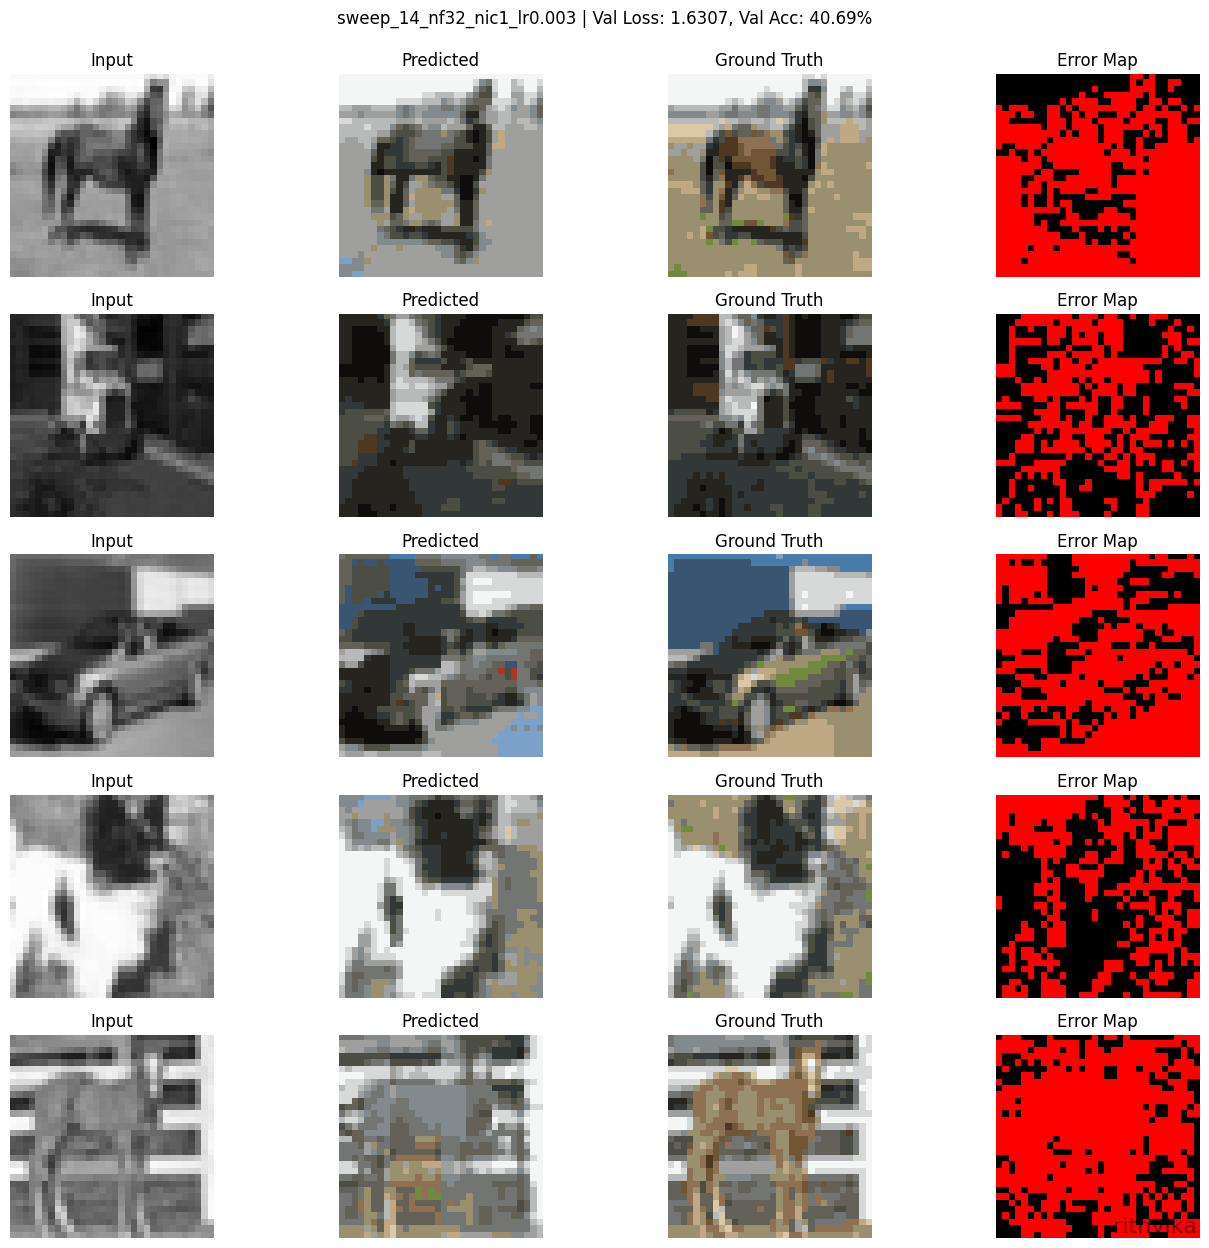

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▆▇▇▇▇███
wandb: train_loss █▄▃▂▂▂▂▁▁▁▁
wandb:    val_acc ▁▄▄▅▆▃▅▇▅██
wandb:   val_loss █▅▅▄▃▆▃▂▃▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 39.90346
wandb: train_loss 1.65309
wandb:    val_acc 40.68605
wandb:   val_loss 1.63067
wandb: 
wandb: 🚀 View run sweep_14_nf32_nic1_lr0.003 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/p2cuyvep
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_114907-p2cuyvep/logs



Running config 15/20: {'lr': 0.001, 'batch_size': 32, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_115611-jdy0sir0
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_15_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/jdy0sir0


Epoch 01 | TrainLoss=2.0171 | ValLoss=1.7821 | TrainAcc=31.40% | ValAcc=37.32%
  Saved best checkpoint (val_loss=1.7821)


Epoch 02 | TrainLoss=1.8217 | ValLoss=1.7232 | TrainAcc=35.39% | ValAcc=38.55%
  Saved best checkpoint (val_loss=1.7232)


...

Epoch 07 | TrainLoss=1.7062 | ValLoss=1.6848 | TrainAcc=38.39% | ValAcc=39.46%


Epoch 08 | TrainLoss=1.6970 | ValLoss=1.6515 | TrainAcc=38.63% | ValAcc=40.39%
  Saved best checkpoint (val_loss=1.6515)


Epoch 09 | TrainLoss=1.6835 | ValLoss=1.6267 | TrainAcc=39.04% | ValAcc=41.04%
  Saved best checkpoint (val_loss=1.6267)


Epoch 10 | TrainLoss=1.6754 | ValLoss=1.6256 | TrainAcc=39.28% | ValAcc=41.01%
  Saved best checkpoint (val_loss=1.6256)


Epoch 11 | TrainLoss=1.6672 | ValLoss=1.6665 | TrainAcc=39.54% | ValAcc=39.34%


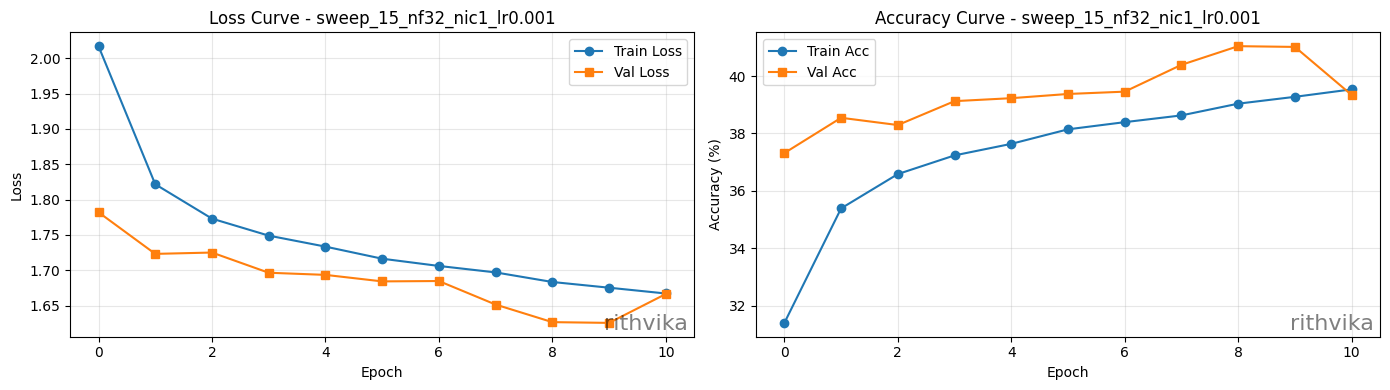

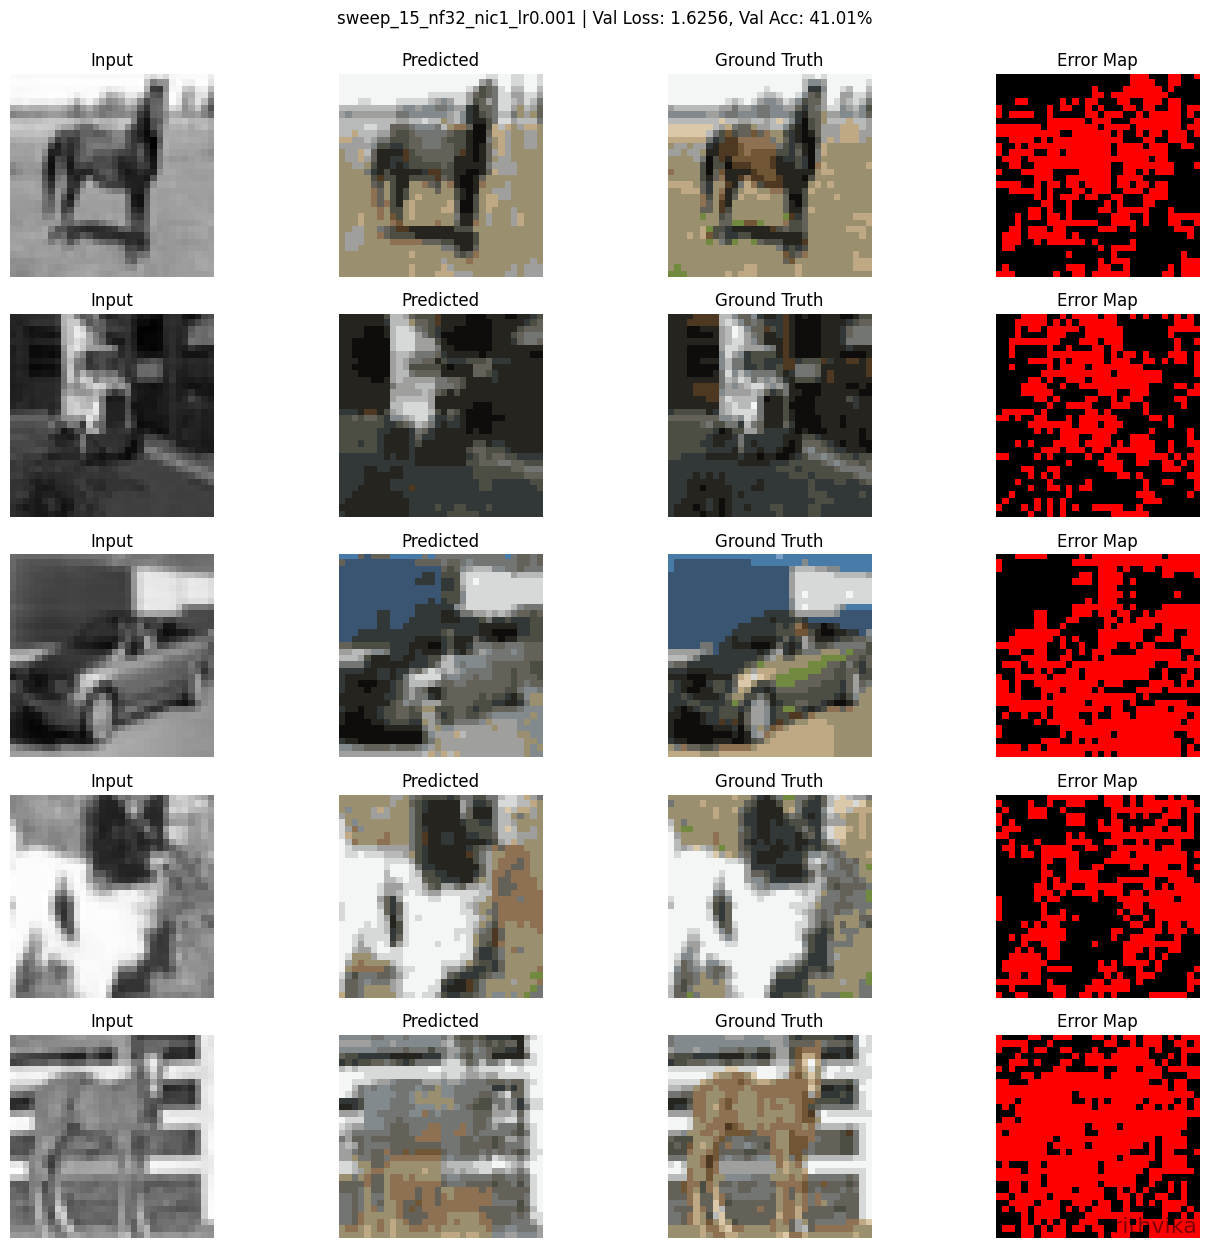

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▄▅▆▆▇▇▇███
wandb: train_loss █▄▃▃▂▂▂▂▁▁▁
wandb:    val_acc ▁▃▃▄▅▅▅▇██▅
wandb:   val_loss █▅▅▄▄▄▄▂▁▁▃
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 39.53516
wandb: train_loss 1.66718
wandb:    val_acc 39.34136
wandb:   val_loss 1.66645
wandb: 
wandb: 🚀 View run sweep_15_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/jdy0sir0
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_115611-jdy0sir0/logs



Running config 16/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_120356-4nhiw03f
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_16_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/4nhiw03f


Epoch 01 | TrainLoss=2.2294 | ValLoss=1.9012 | TrainAcc=28.28% | ValAcc=34.84%
  Saved best checkpoint (val_loss=1.9012)


Epoch 02 | TrainLoss=1.8509 | ValLoss=1.8025 | TrainAcc=35.35% | ValAcc=36.51%
  Saved best checkpoint (val_loss=1.8025)


...

Epoch 07 | TrainLoss=1.6858 | ValLoss=1.6911 | TrainAcc=39.28% | ValAcc=38.90%


Epoch 08 | TrainLoss=1.6738 | ValLoss=1.6550 | TrainAcc=39.60% | ValAcc=40.12%
  Saved best checkpoint (val_loss=1.6550)


Epoch 09 | TrainLoss=1.6673 | ValLoss=1.6655 | TrainAcc=39.76% | ValAcc=39.64%


Epoch 10 | TrainLoss=1.6566 | ValLoss=1.6364 | TrainAcc=40.04% | ValAcc=40.64%
  Saved best checkpoint (val_loss=1.6364)


Epoch 11 | TrainLoss=1.6550 | ValLoss=1.6797 | TrainAcc=40.08% | ValAcc=39.45%


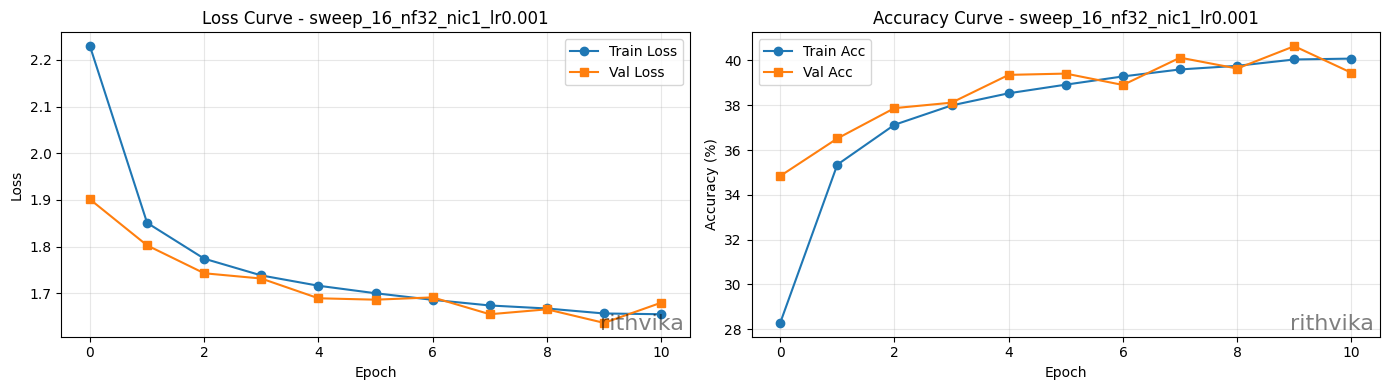

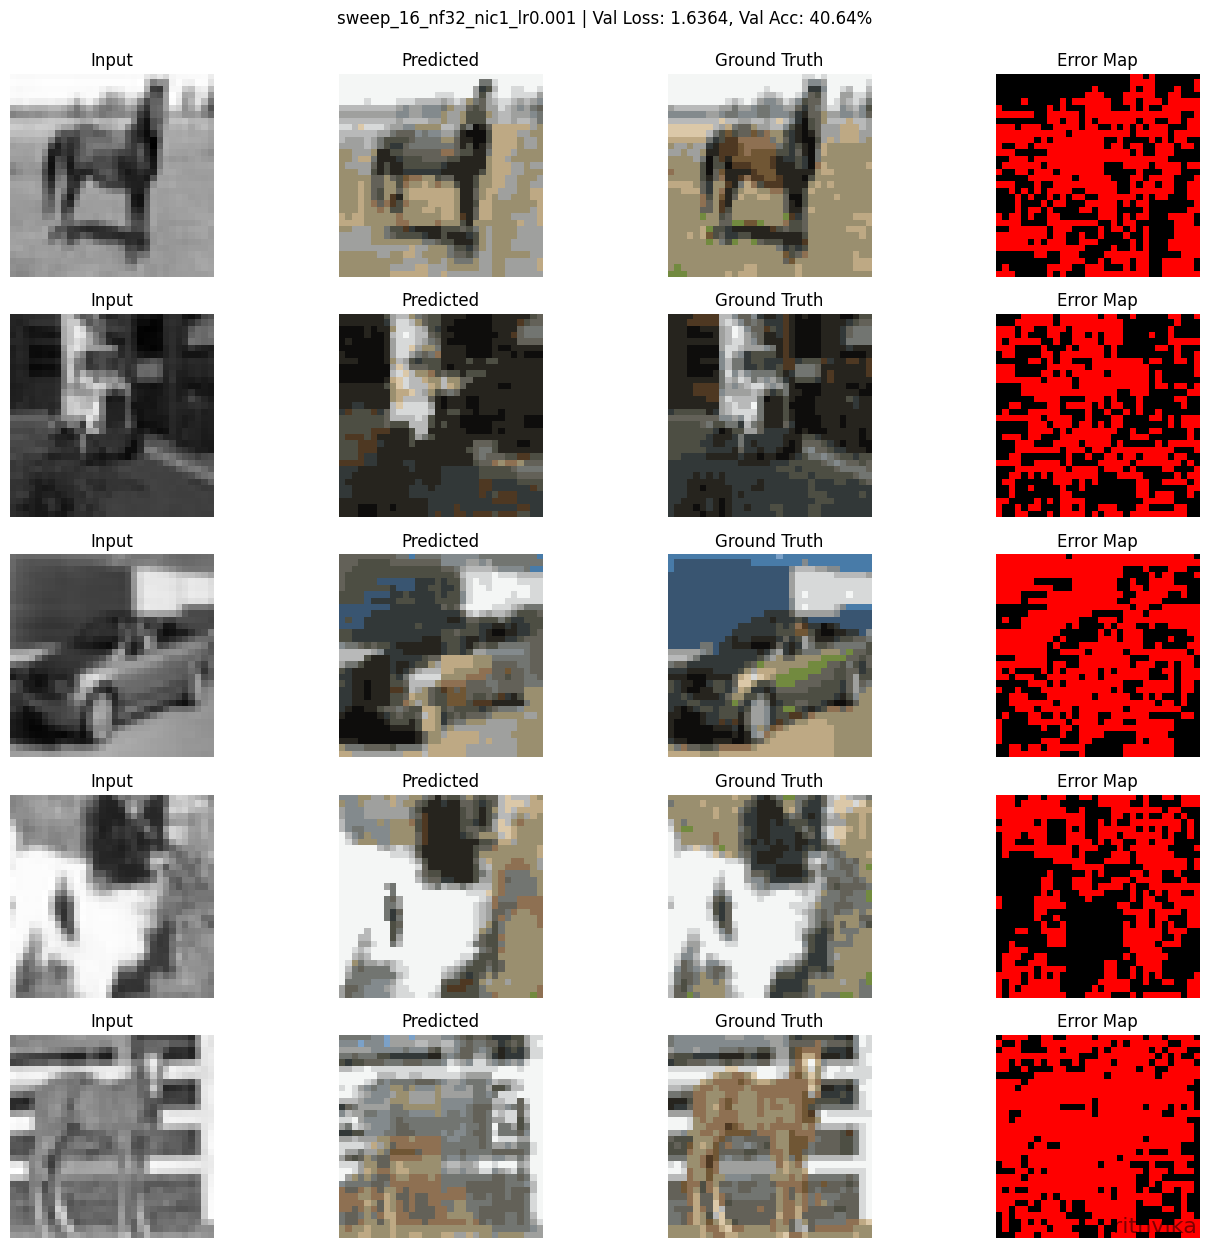

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇█████
wandb: train_loss █▃▂▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▃▅▅▆▇▆▇▇█▇
wandb:   val_loss █▅▄▄▂▂▂▁▂▁▂
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 40.08018
wandb: train_loss 1.65501
wandb:    val_acc 39.44654
wandb:   val_loss 1.67972
wandb: 
wandb: 🚀 View run sweep_16_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/4nhiw03f
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_120356-4nhiw03f/logs



Running config 17/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_121042-epcco5k9
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_17_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/epcco5k9


Epoch 01 | TrainLoss=2.0350 | ValLoss=1.7339 | TrainAcc=31.92% | ValAcc=38.11%
  Saved best checkpoint (val_loss=1.7339)


Epoch 02 | TrainLoss=1.6852 | ValLoss=1.6411 | TrainAcc=39.16% | ValAcc=40.37%
  Saved best checkpoint (val_loss=1.6411)


...

Epoch 07 | TrainLoss=1.5249 | ValLoss=1.6018 | TrainAcc=43.54% | ValAcc=41.04%


Epoch 08 | TrainLoss=1.5069 | ValLoss=1.5262 | TrainAcc=44.07% | ValAcc=43.39%
  Saved best checkpoint (val_loss=1.5262)


Epoch 09 | TrainLoss=1.5014 | ValLoss=1.5556 | TrainAcc=44.22% | ValAcc=42.44%


Epoch 10 | TrainLoss=1.4898 | ValLoss=1.5096 | TrainAcc=44.56% | ValAcc=43.68%
  Saved best checkpoint (val_loss=1.5096)


Epoch 11 | TrainLoss=1.4780 | ValLoss=1.4995 | TrainAcc=44.91% | ValAcc=44.51%
  Saved best checkpoint (val_loss=1.4995)


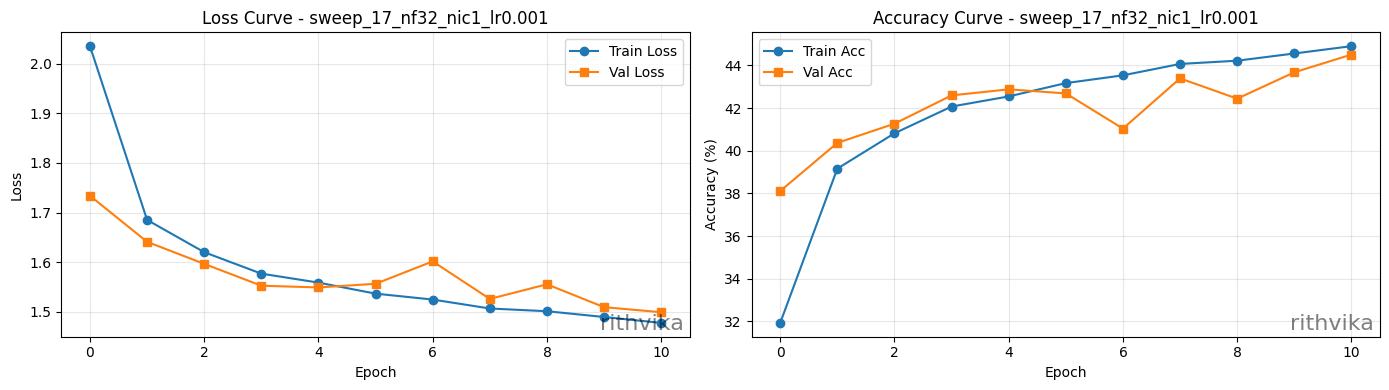

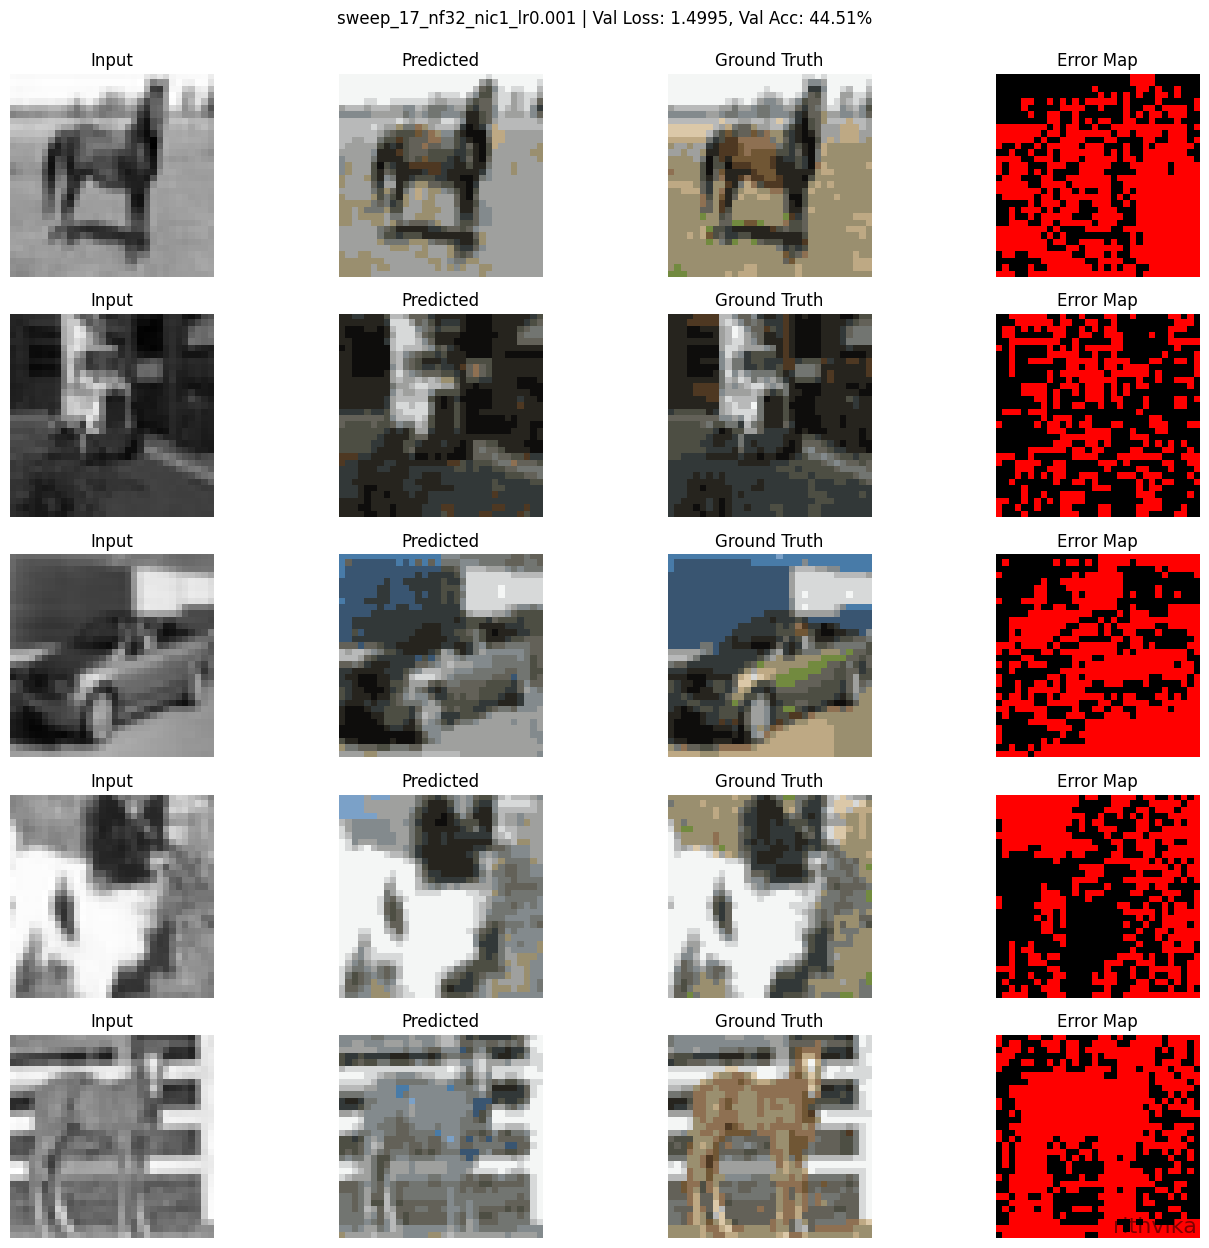

wandb: uploading history steps 10-11, summary, console lines 0-0
wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▆▇▇▇████
wandb: train_loss █▄▃▂▂▂▂▁▁▁▁
wandb:    val_acc ▁▃▄▆▆▆▄▇▆▇█
wandb:   val_loss █▅▄▃▂▃▄▂▃▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 44.90632
wandb: train_loss 1.47797
wandb:    val_acc 44.51228
wandb:   val_loss 1.49947
wandb: 
wandb: 🚀 View run sweep_17_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/epcco5k9
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_121042-epcco5k9/logs



Running config 18/20: {'lr': 0.0003, 'batch_size': 64, 'nf': 16, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_121809-ybrdcok8
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_18_nf16_nic1_lr0.0003
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ybrdcok8


Epoch 01 | TrainLoss=2.4458 | ValLoss=2.0434 | TrainAcc=23.66% | ValAcc=33.04%
  Saved best checkpoint (val_loss=2.0434)


Epoch 02 | TrainLoss=1.9517 | ValLoss=1.8538 | TrainAcc=33.71% | ValAcc=36.18%
  Saved best checkpoint (val_loss=1.8538)


...

Epoch 07 | TrainLoss=1.6881 | ValLoss=1.6583 | TrainAcc=39.09% | ValAcc=40.16%
  Saved best checkpoint (val_loss=1.6583)


Epoch 08 | TrainLoss=1.6702 | ValLoss=1.6349 | TrainAcc=39.56% | ValAcc=41.03%
  Saved best checkpoint (val_loss=1.6349)


Epoch 09 | TrainLoss=1.6596 | ValLoss=1.6253 | TrainAcc=39.80% | ValAcc=41.30%
  Saved best checkpoint (val_loss=1.6253)


Epoch 10 | TrainLoss=1.6475 | ValLoss=1.6159 | TrainAcc=40.18% | ValAcc=41.49%
  Saved best checkpoint (val_loss=1.6159)


Epoch 11 | TrainLoss=1.6359 | ValLoss=1.6252 | TrainAcc=40.47% | ValAcc=41.05%


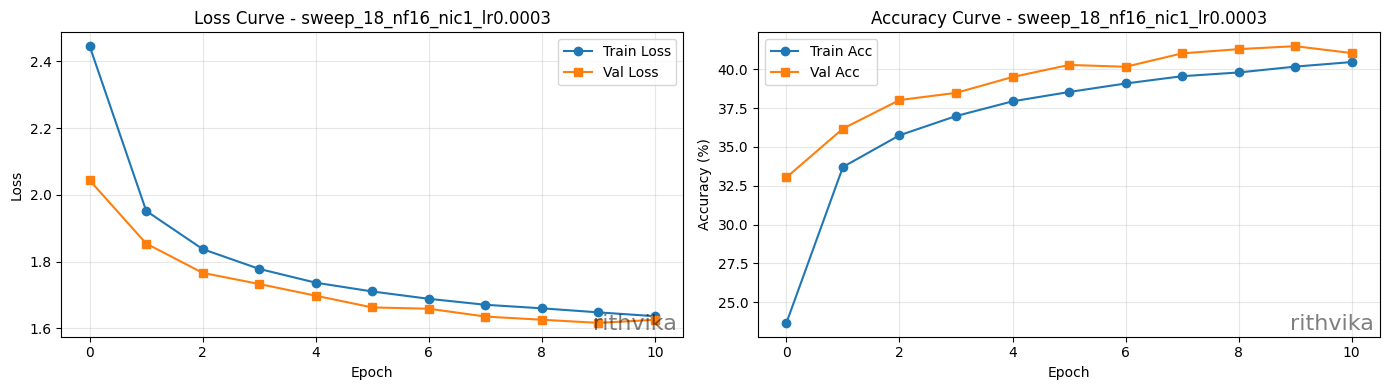

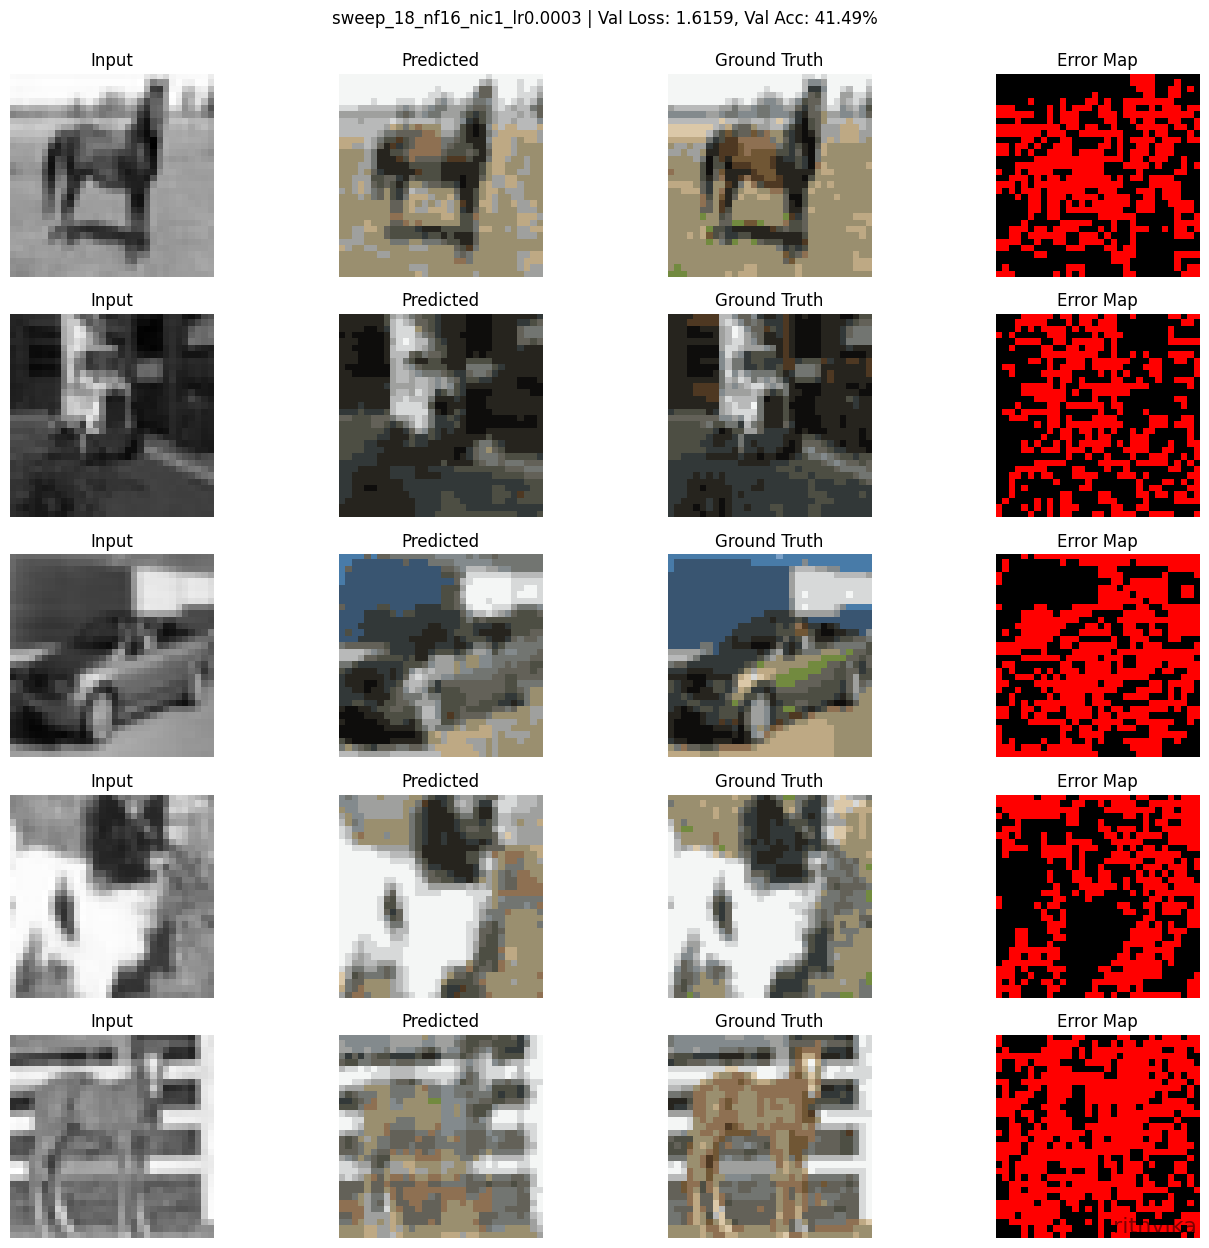

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▅▆▇▇▇▇████
wandb: train_loss █▄▃▂▂▂▁▁▁▁▁
wandb:    val_acc ▁▄▅▆▆▇▇████
wandb:   val_loss █▅▃▃▂▂▂▁▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 40.46908
wandb: train_loss 1.63593
wandb:    val_acc 41.04676
wandb:   val_loss 1.62524
wandb: 
wandb: 🚀 View run sweep_18_nf16_nic1_lr0.0003 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ybrdcok8
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_121809-ybrdcok8/logs



Running config 19/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'sgd'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_122515-jbzol0um
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_19_nf32_nic1_lr0.001
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/jbzol0um


Epoch 01 | TrainLoss=3.0526 | ValLoss=2.8369 | TrainAcc=10.21% | ValAcc=15.46%
  Saved best checkpoint (val_loss=2.8369)


Epoch 02 | TrainLoss=2.6786 | ValLoss=2.5417 | TrainAcc=18.21% | ValAcc=21.35%
  Saved best checkpoint (val_loss=2.5417)


...

Epoch 07 | TrainLoss=2.1141 | ValLoss=2.0761 | TrainAcc=29.95% | ValAcc=31.13%
  Saved best checkpoint (val_loss=2.0761)


Epoch 08 | TrainLoss=2.0804 | ValLoss=2.0489 | TrainAcc=30.55% | ValAcc=31.52%
  Saved best checkpoint (val_loss=2.0489)


Epoch 09 | TrainLoss=2.0538 | ValLoss=2.0189 | TrainAcc=30.97% | ValAcc=32.33%
  Saved best checkpoint (val_loss=2.0189)


Epoch 10 | TrainLoss=2.0311 | ValLoss=1.9970 | TrainAcc=31.40% | ValAcc=32.64%
  Saved best checkpoint (val_loss=1.9970)


Epoch 11 | TrainLoss=2.0120 | ValLoss=1.9765 | TrainAcc=31.72% | ValAcc=33.07%
  Saved best checkpoint (val_loss=1.9765)


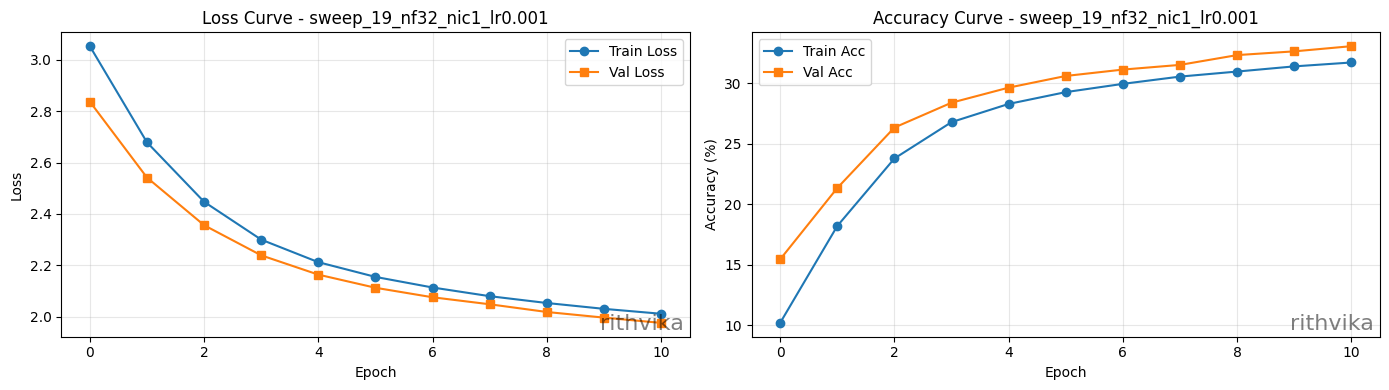

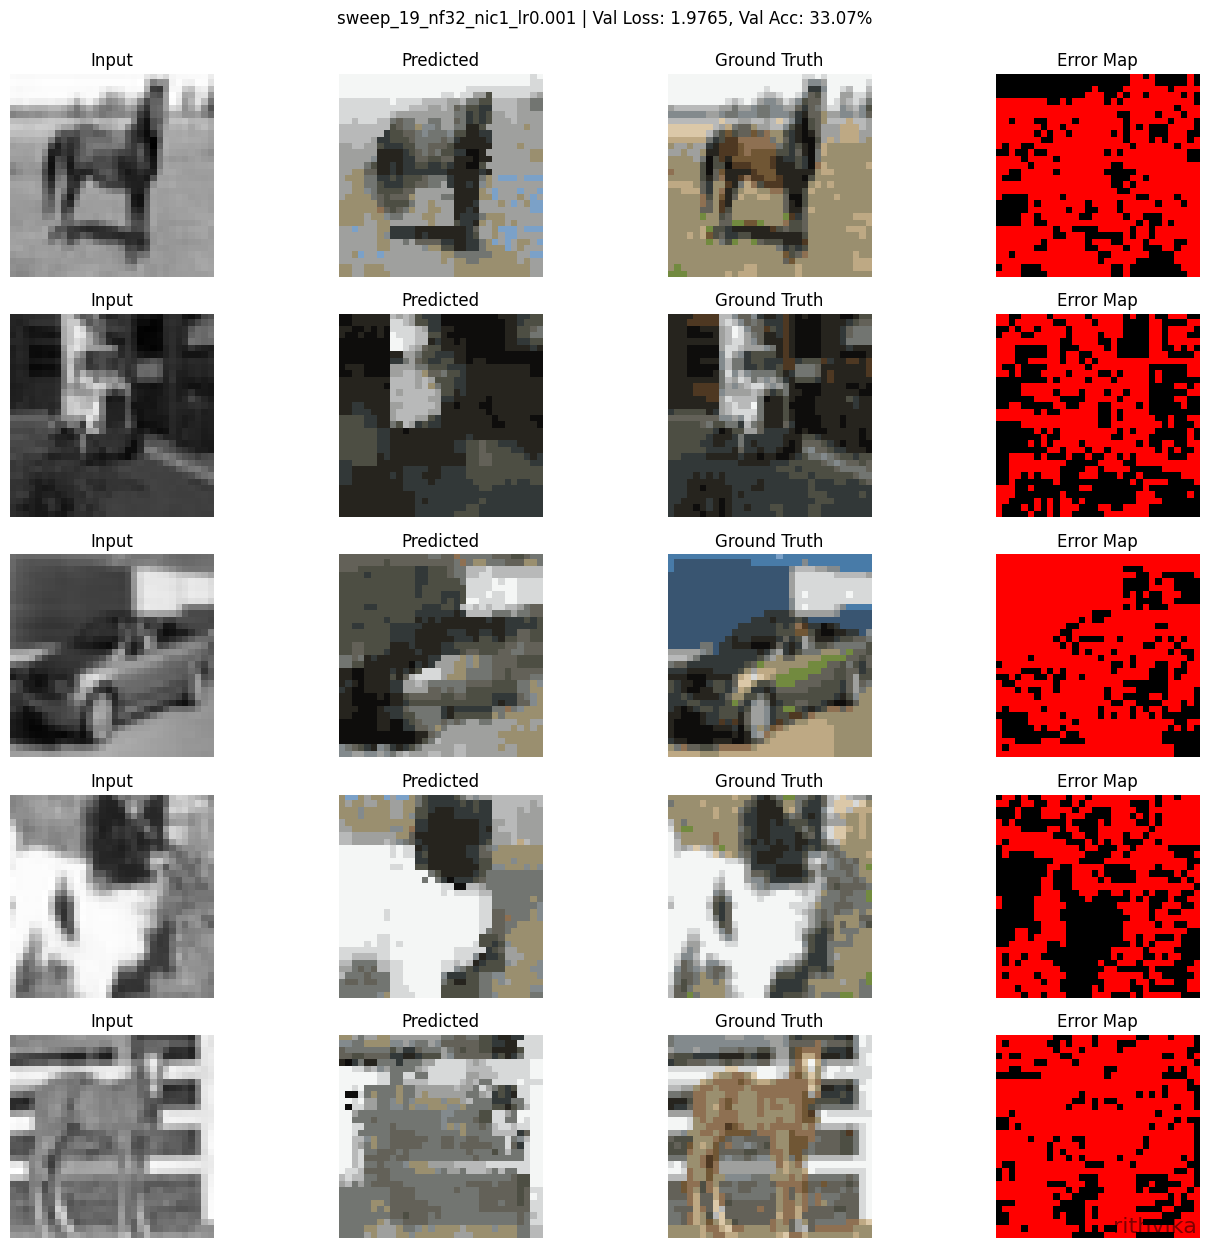

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▄▅▆▇▇▇████
wandb: train_loss █▅▄▃▂▂▂▁▁▁▁
wandb:    val_acc ▁▃▅▆▇▇▇▇███
wandb:   val_loss █▆▄▃▃▂▂▂▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 31.71967
wandb: train_loss 2.012
wandb:    val_acc 33.06753
wandb:   val_loss 1.97654
wandb: 
wandb: 🚀 View run sweep_19_nf32_nic1_lr0.001 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/jbzol0um
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_122515-jbzol0um/logs



Running config 20/20: {'lr': 0.003, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'sgd'}


wandb: Tracking run with wandb version 0.21.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20251103_123222-tw90k6lg
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sweep_20_nf32_nic1_lr0.003
wandb: ⭐️ View project at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: 🚀 View run at https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/tw90k6lg


Epoch 01 | TrainLoss=2.9648 | ValLoss=2.7174 | TrainAcc=12.17% | ValAcc=17.94%
  Saved best checkpoint (val_loss=2.7174)


Epoch 02 | TrainLoss=2.5412 | ValLoss=2.4038 | TrainAcc=21.51% | ValAcc=24.92%
  Saved best checkpoint (val_loss=2.4038)


...

Epoch 07 | TrainLoss=2.0182 | ValLoss=1.9982 | TrainAcc=31.94% | ValAcc=32.22%
  Saved best checkpoint (val_loss=1.9982)


Epoch 08 | TrainLoss=1.9895 | ValLoss=1.9705 | TrainAcc=32.39% | ValAcc=32.89%
  Saved best checkpoint (val_loss=1.9705)


Epoch 09 | TrainLoss=1.9637 | ValLoss=1.9358 | TrainAcc=32.87% | ValAcc=33.78%
  Saved best checkpoint (val_loss=1.9358)


Epoch 10 | TrainLoss=1.9403 | ValLoss=1.9253 | TrainAcc=33.32% | ValAcc=33.65%
  Saved best checkpoint (val_loss=1.9253)


Epoch 11 | TrainLoss=1.9224 | ValLoss=1.8976 | TrainAcc=33.70% | ValAcc=34.62%
  Saved best checkpoint (val_loss=1.8976)


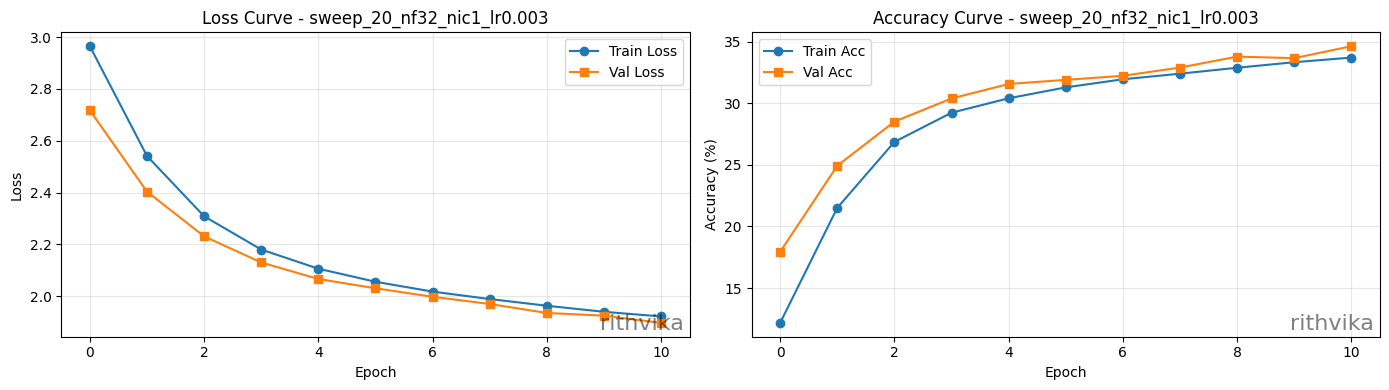

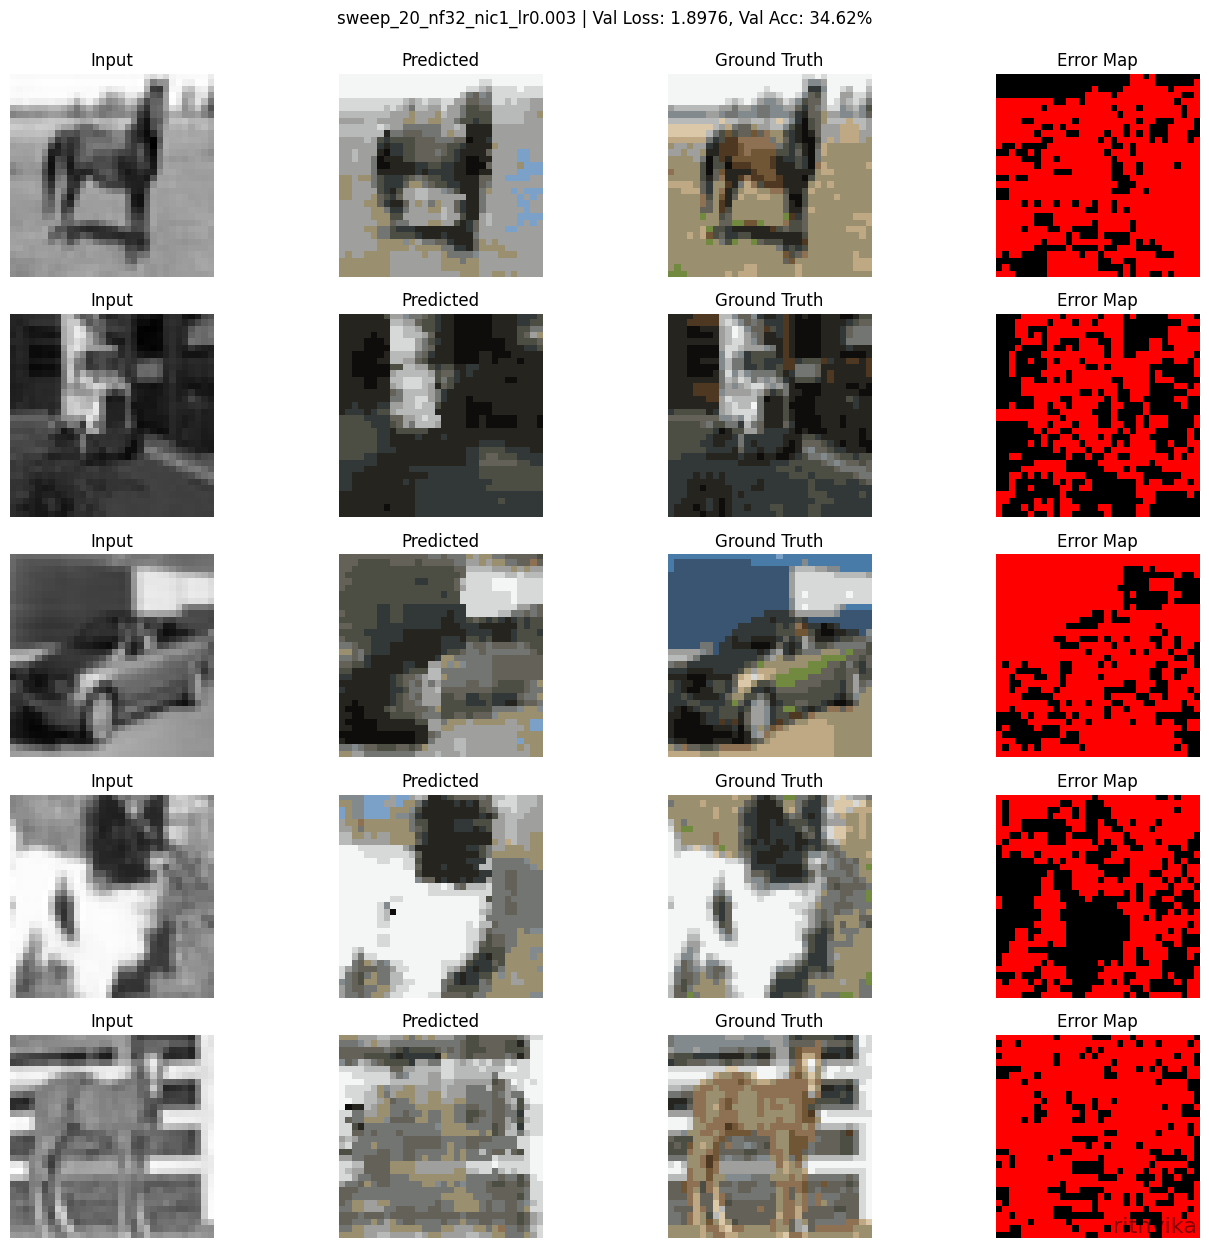

wandb:                                                                                
wandb: 
wandb: Run history:
wandb:      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:  train_acc ▁▄▆▇▇▇▇████
wandb: train_loss █▅▄▃▂▂▂▁▁▁▁
wandb:    val_acc ▁▄▅▆▇▇▇▇███
wandb:   val_loss █▅▄▃▂▂▂▂▁▁▁
wandb: 
wandb: Run summary:
wandb:      epoch 11
wandb:  train_acc 33.69902
wandb: train_loss 1.92237
wandb:    val_acc 34.62498
wandb:   val_loss 1.89757
wandb: 
wandb: 🚀 View run sweep_20_nf32_nic1_lr0.003 at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/tw90k6lg
wandb: ⭐️ View project at: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep
wandb: Synced 5 W&B file(s), 5 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20251103_123222-tw90k6lg/logs



SWEEP COMPLETED!

Best Model by Validation Loss:
----------------------------------------------------------------------
config_id                                 1
run_name         sweep_01_nf128_nic1_lr0.01
lr                                     0.01
batch_size                              256
nf                                      128
nic                                       1
nc                                       24
kernel_size                               5
optimizer                              adam
best_val_loss                      1.409142
best_val_acc                      47.012235

Best Model by Validation Accuracy:
----------------------------------------------------------------------
config_id                                 1
run_name         sweep_01_nf128_nic1_lr0.01
lr                                     0.01
batch_size                              256
nf                                      128
nic                                       1
nc                      

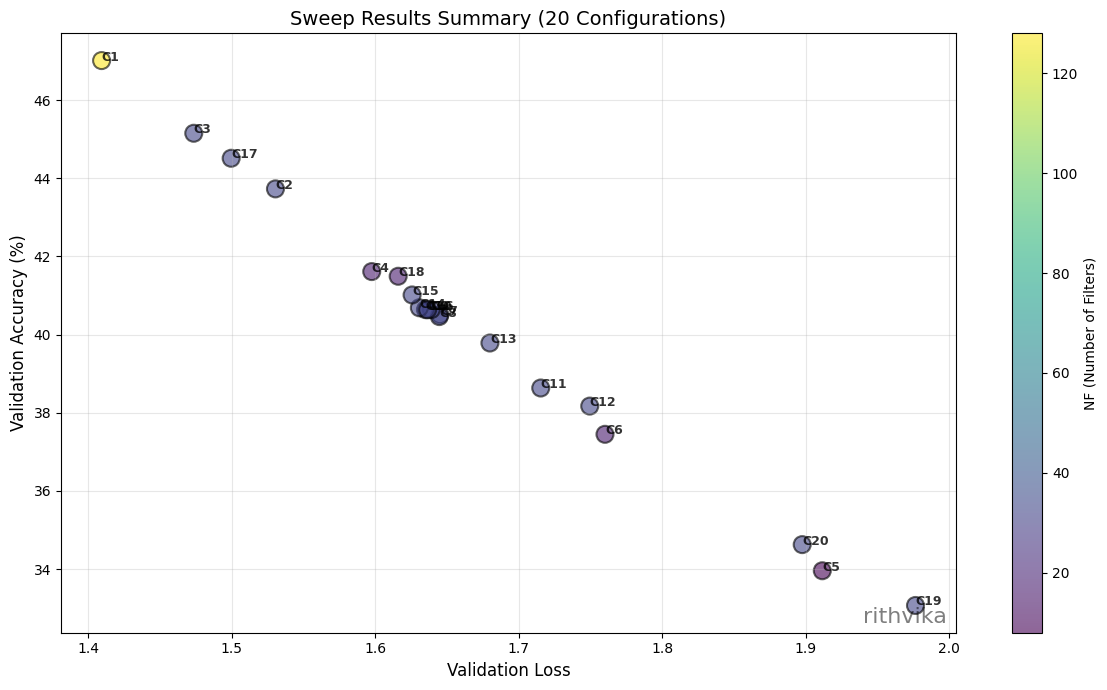


Results saved to: /kaggle/working/checkpoints/sweep_results.csv

All tasks completed successfully!
✓ Baseline training: 1.4822
✓ Analytical computations: Complete
✓ Hyperparameter sweep: 20 configurations tested


In [12]:

    # hyperparameter sweep (10-15 epochs per config)
print("\nSTEP 3: Hyperparameter Sweep")
print("="*70)
print(f"Total configurations: {len(SWEEP_CONFIGS)}")
print(f"Epochs per run: 10-15")
print("="*70 + "\n")

# input("Press Enter to start hyperparameter sweep...")
print("Starting hyperparameter sweep...")


results_df = sweep_runner(num_epochs=11)

print("\nAll tasks completed successfully!")
print(f"✓ Baseline training: {baseline_results['best_val_loss']:.4f}")
print(f"✓ Analytical computations: Complete")
print(f"✓ Hyperparameter sweep: {len(SWEEP_CONFIGS)} configurations tested")

## Hyperparameter Sweep Results Table

| Config ID | Run Name | Learning Rate | Batch Size | NF | NIC | NC | Kernel Size | Optimizer | Best Val Loss | Best Val Acc (%) |
|-----------|----------|---------------|------------|----|----|----|-----------|-----------|--------------|--------------------|
| 1 | sweep_01_nf128_nic1_lr0.01 | 0.01 | 256 | 128 | 1 | 24 | 5 | adam | **1.409** | **47.01** |
| 2 | sweep_02_nf32_nic1_lr0.0003 | 0.0003 | 128 | 32 | 1 | 24 | 5 | adam | 1.530 | 43.73 |
| 3 | sweep_03_nf32_nic1_lr0.001 | 0.001 | 128 | 32 | 1 | 24 | 5 | adam | 1.473 | 45.15 |
| 4 | sweep_04_nf16_nic1_lr0.001 | 0.001 | 128 | 16 | 1 | 24 | 5 | adam | 1.597 | 41.61 |
| 5 | sweep_05_nf8_nic1_lr0.001 | 0.001 | 64 | 8 | 1 | 24 | 3 | adam | 1.912 | 33.96 |
| 6 | sweep_06_nf16_nic1_lr0.001 | 0.001 | 64 | 16 | 1 | 24 | 3 | adam | 1.760 | 37.45 |
| 7 | sweep_07_nf32_nic1_lr0.001 | 0.001 | 128 | 32 | 1 | 24 | 3 | adam | 1.645 | 40.51 |
| 8 | sweep_08_nf32_nic1_lr0.001 | 0.001 | 128 | 32 | 1 | 24 | 3 | adam | 1.645 | 40.46 |
| 9 | sweep_09_nf32_nic1_lr0.001 | 0.001 | 64 | 32 | 1 | 24 | 3 | adam | 1.639 | 40.64 |
| 10 | sweep_10_nf32_nic1_lr0.001 | 0.001 | 64 | 32 | 1 | 24 | 3 | adam | 1.635 | 40.64 |
| 11 | sweep_11_nf32_nic1_lr0.0003 | 0.0003 | 128 | 32 | 1 | 24 | 3 | adam | 1.715 | 38.63 |
| 12 | sweep_12_nf32_nic1_lr0.0001 | 0.0001 | 64 | 32 | 1 | 24 | 3 | adam | 1.749 | 38.17 |
| 13 | sweep_13_nf32_nic1_lr0.0003 | 0.0003 | 64 | 32 | 1 | 24 | 3 | adam | 1.680 | 39.78 |
| 14 | sweep_14_nf32_nic1_lr0.003 | 0.003 | 64 | 32 | 1 | 24 | 3 | adam | 1.631 | 40.69 |
| 15 | sweep_15_nf32_nic1_lr0.001 | 0.001 | 32 | 32 | 1 | 24 | 3 | adam | 1.626 | 41.01 |
| 16 | sweep_16_nf32_nic1_lr0.001 | 0.001 | 128 | 32 | 1 | 24 | 3 | adam | 1.636 | 40.64 |
| 17 | sweep_17_nf32_nic1_lr0.001 | 0.001 | 64 | 32 | 1 | 24 | 5 | adam | 1.499 | 44.51 |
| 18 | sweep_18_nf16_nic1_lr0.0003 | 0.0003 | 64 | 16 | 1 | 24 | 5 | adam | 1.616 | 41.49 |
| 19 | sweep_19_nf32_nic1_lr0.001 | 0.001 | 64 | 32 | 1 | 24 | 3 | sgd | 1.977 | 33.07 |
| 20 | sweep_20_nf32_nic1_lr0.003 | 0.003 | 128 | 32 | 1 | 24 | 3 | sgd | 1.898 | 34.62 |


- Best Performance: Config 1 (NF=128, LR=0.01, Batch=256, Kernel=5) achieved the lowest validation loss (1.409) and highest accuracy (47.01%)
- Least Performance: SGD configurations (19, 20) performed significantly worse than Adam optimizer
- Model Size Effect: Larger models (NF=128, 32) generally outperformed smaller ones (NF=8, 16)
- Learning Rate: Higher learning rates (0.01, 0.003) with appropriate batch sizes showed better results

### Analytical Questions: Calculations

The model architecture for the following quantities,analyzing **symbolically** in terms of NIC (input channels), NF (base filters), and NC (number of color classes):

- **1. Number of weights (ignoring biases and BatchNorm)**
- **2. Number of outputs (total activation elements across all layers for a single input)**
- **3. Number of connections (weights × input activations per layer)**
- For both **input 32×32** and **input 64×64**


### **Assumptions**

- All convolutions use kernel size 3×3, stride 1, padding 1 (so output spatial size is preserved before pooling).
- All ConvTranspose2d use kernel size 2×2, stride 2 (upsampling by 2).
- MaxPool2d uses kernel size 2, stride 2 (downsampling by 2).
- Final classifier is a 1×1 Conv2d (NC→NC).
- Ignoring biases and BatchNorm parameters.


#### **Layerwise Architecture**

| Layer         | Input Channels | Output Channels | Kernel | Output Size (32×32 input) | Output Size (64×64 input) |
|---------------|---------------|-----------------|--------|---------------------------|---------------------------|
| Conv1         | NIC           | NF              | 3×3    | 32×32 → 16×16             | 64×64 → 32×32             |
| Conv2         | NF            | 2NF             | 3×3    | 16×16 → 8×8               | 32×32 → 16×16             |
| Conv3         | 2NF           | 4NF             | 3×3    | 8×8 → 4×4                 | 16×16 → 8×8               |
| Deconv1       | 4NF           | 2NF             | 2×2    | 4×4 → 8×8                 | 8×8 → 16×16               |
| Deconv2       | 2NF           | NF              | 2×2    | 8×8 → 16×16               | 16×16 → 32×32             |
| Deconv3       | NF            | NC              | 2×2    | 16×16 → 32×32             | 32×32 → 64×64             |
| Classifier    | NC            | NC              | 1×1    | 32×32                     | 64×64                     |

---

#### **1. Number of Weights (ignore biases & BN)**

- Conv2d: out_ch × in_ch × k × k
- ConvTranspose2d: in_ch × out_ch × k × k
- Classifier: NC × NC × 1 × 1

**Formulas:**
- Conv1:      NF × NIC × 3 × 3 = 9 × NIC × NF
- Conv2:      2NF × NF × 3 × 3 = 18 × NF^2
- Conv3:      4NF × 2NF × 3 × 3 = 72 × NF^2
- Deconv1:    4NF × 2NF × 2 × 2 = 16 × NF^2
- Deconv2:    2NF × NF × 2 × 2 = 8 × NF^2
- Deconv3:    NF × NC × 2 × 2 = 4 × NF × NC
- Classifier: NC × NC × 1 × 1 = NC^2

**Total Weights:**

Let:
- NIC = 1 (input channels, grayscale)
- NF = 64 (base filters)
- NC = 24 (number of color classes)


- **Weights** = 9×NIC×NF + 114×NF² + 4×NF×NC + NC²  
- Substituting we get:  
  = 9×1×64 + 114×64² + 4×64×24 + 24²  
  = 576 + 114×4096 + 6144 + 576  
  = 576 + 466,944 + 6,144 + 576  
  = **474,240**



---

#### **2. Number of Outputs (Total Activation Elements)**

Sum the output elements for each layer (after activation, before next layer):

### For **32×32 input**:

- Conv1:      NF × 32 × 32
- Pool1:      NF × 16 × 16
- Conv2:      2NF × 16 × 16
- Pool2:      2NF × 8 × 8
- Conv3:      4NF × 8 × 8
- Pool3:      4NF × 4 × 4
- Deconv1:    2NF × 8 × 8
- Deconv2:    NF × 16 × 16
- Deconv3:    NC × 32 × 32
- Classifier: NC × 32 × 32

**Total Activations (32×32):**

- Conv1:      64 × 32 × 32   = 65,536
- Pool1:      64 × 16 × 16   = 16,384
- Conv2:     128 × 16 × 16   = 32,768
- Pool2:     128 × 8 × 8     = 8,192
- Conv3:     256 × 8 × 8     = 16,384
- Pool3:     256 × 4 × 4     = 4,096
- Deconv1:   128 × 8 × 8     = 8,192
- Deconv2:    64 × 16 × 16   = 16,384
- Deconv3:    24 × 32 × 32   = 24,576
- Classifier: 24 × 32 × 32   = 24,576

**Total Activations (32×32):**  
= 65,536 + 16,384 + 32,768 + 8,192 + 16,384 + 4,096 + 8,192 + 16,384 + 24,576 + 24,576  
= **217,088**




### For **64×64 input**:

- Conv1:      NF × 64 × 64
- Pool1:      NF × 32 × 32
- Conv2:      2NF × 32 × 32
- Pool2:      2NF × 16 × 16
- Conv3:      4NF × 16 × 16
- Pool3:      4NF × 8 × 8
- Deconv1:    2NF × 16 × 16
- Deconv2:    NF × 32 × 32
- Deconv3:    NC × 64 × 64
- Classifier: NC × 64 × 64

**Total Activations (64×64):**
- Conv1:      64 × 64 × 64   = 262,144
- Pool1:      64 × 32 × 32   = 65,536
- Conv2:     128 × 32 × 32   = 131,072
- Pool2:     128 × 16 × 16   = 32,768
- Conv3:     256 × 16 × 16   = 65,536
- Pool3:     256 × 8 × 8     = 16,384
- Deconv1:   128 × 16 × 16   = 32,768
- Deconv2:    64 × 32 × 32   = 65,536
- Deconv3:    24 × 64 × 64   = 98,304
- Classifier: 24 × 64 × 64   = 98,304

**Total Activations (64×64):**  
= 262,144 + 65,536 + 131,072 + 32,768 + 65,536 + 16,384 + 32,768 + 65,536 + 98,304 + 98,304  
= **968,352**

---



#### **3. Number of Connections**

For each layer:  
**Connections = (number of weights in layer) × (number of output elements in that layer)**

### For **32×32 input**:

- Conv1:      9*NIC*NF × 32*32
- Conv2:      18*NF^2 × 16*16
- Conv3:      72*NF^2 × 8*8
- Deconv1:    16*NF^2 × 8*8
- Deconv2:    8*NF^2 × 16*16
- Deconv3:    4*NF*NC × 32*32
- Classifier: NC^2 × 32*32

**Total Connections (32×32):**

#### For **32×32 input**:
- Conv1:      9×1×64 × 32×32      = 576 × 1,024   = 589,824
- Conv2:     18×64² × 16×16       = 73,728 × 256  = 18,874,368
- Conv3:     72×64² × 8×8         = 294,912 × 64  = 18,874,368
- Deconv1:   16×64² × 8×8         = 65,536 × 64   = 4,194,304
- Deconv2:    8×64² × 16×16       = 32,768 × 256  = 8,388,608
- Deconv3:    4×64×24 × 32×32     = 6,144 × 1,024 = 6,291,456
- Classifier: 24² × 32×32         = 576 × 1,024   = 589,824

**Total Connections (32×32):**  
= 589,824 + 18,874,368 + 18,874,368 + 4,194,304 + 8,388,608 + 6,291,456 + 589,824  
= **58,802,752**




### For **64×64 input**:

- Conv1:      9*NIC*NF × 64*64
- Conv2:      18*NF^2 × 32*32
- Conv3:      72*NF^2 × 16*16
- Deconv1:    16*NF^2 × 16*16
- Deconv2:    8*NF^2 × 32*32
- Deconv3:    4*NF*NC × 64*64
- Classifier: NC^2 × 64*64

**Total Connections (64×64):**
- Conv1:      9×1×64 × 64×64      = 576 × 4,096   = 2,359,296
- Conv2:     18×64² × 32×32       = 73,728 × 1,024 = 75,497,472
- Conv3:     72×64² × 16×16       = 294,912 × 256  = 75,497,472
- Deconv1:   16×64² × 16×16       = 65,536 × 256   = 16,777,216
- Deconv2:    8×64² × 32×32       = 32,768 × 1,024 = 33,554,432
- Deconv3:    4×64×24 × 64×64     = 6,144 × 4,096  = 25,165,824
- Classifier: 24² × 64×64         = 576 × 4,096    = 2,359,296

**Total Connections (64×64):**  
= 2,359,296 + 75,497,472 + 75,497,472 + 16,777,216 + 33,554,432 + 25,165,824 + 2,359,296  
= **231,210,008**



#### **Summary Table (with values)**

| Quantity         | 32×32 Input (NIC=1, NF=64, NC=24) | 64×64 Input (NIC=1, NF=64, NC=24) |
|------------------|-----------------------------------|-----------------------------------|
| **Weights**      | 474,240                           | 474,240                           |
| **Activations**  | 217,088                           | 968,352                           |
| **Connections**  | 58,802,752                        | 231,210,008                       |


### Key Points from Hyperparameter Sweep Results

- **Best Performance:**  
  The configuration with the lowest validation loss and highest accuracy is config_id=1 (nf=128, lr=0.01, batch_size=256, kernel_size=5, optimizer=adam), achieving a best validation loss of 1.41 and accuracy of 47.0%. This suggests that a larger model with a higher learning rate and bigger batch size works better.

- **Effect of Number of Filters (`nf`):**  
  Increasing the number of filters (`nf`) generally improves performance. Lower values of `nf` (e.g., 8 or 16) result in higher loss and lower accuracy, while higher values (32, 64, 128) perform better.

- **Learning Rate:**  
  A higher learning rate (`lr=0.01`) with a large model and batch size gives the best result, but for smaller models, moderate learning rates (`0.001` or `0.0003`) are more stable. Too low (`0.0001`) or too high (`0.003`) learning rates do not yield the best results.

- **Batch Size:**  
  Larger batch sizes (128, 256) are associated with better performance, especially when combined with more filters.

- **Kernel Size:**  
  Both kernel sizes 3 and 5 are tested. The best run uses a kernel size of 5, but kernel size alone does not have a dramatic effect compared to `nf` and `lr`.

- **Optimizer:**  
  The Adam optimizer consistently outperforms SGD in this sweep. SGD runs (configs 19 and 20) have the highest losses and lowest accuracies.

- **General Trends:**  
  - Models with very few filters or small batch sizes underperform.
  - The best configurations balance model capacity (filters), learning rate, and batch size.
  - Validation accuracy for the best models is around 47%, indicating the task remains challenging and there is room for further improvement.

- **Consistency:**  
  There is some consistency in results for repeated configurations, showing the sweep is stable and reproducible.

**Conclusion:**  
For this colorization task, using a larger model (more filters), a higher learning rate, and a larger batch size with the Adam optimizer yields the better results. However, even the better models achieve less than 50% pixel-wise accuracy.

Project Link : 

https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization

Baseline run:

https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization/runs/k7ssktg1
                

Sweep runs :
https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep


1/20: {'lr': 0.01, 'batch_size': 256, 'nf': 128, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}
sweep_01_nf128_nic1_lr0.01: https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ysxord4v


2/20: {'lr': 0.0003, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}
sweep_02_nf32_nic1_lr0.0003 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/akylodr8

               
3/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}
sweep_03_nf32_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/vu4qr75r

                 
4/20: {'lr': 0.001, 'batch_size': 128, 'nf': 16, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}
sweep_04_nf16_nic1_lr0.001 :  https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/xyrupvla


5/20: {'lr': 0.001, 'batch_size': 64, 'nf': 8, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_05_nf8_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/71nml61s

                     
6/20: {'lr': 0.001, 'batch_size': 64, 'nf': 16, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_06_nf16_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/n716fa85

                      
7/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_07_nf32_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/yavswddw
                      

8/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_08_nf32_nic1_lr0.001 :  https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/vh12vp8a


9/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_09_nf32_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/45w8r04j



10/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_10_nf32_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/nxiywwku
                                                                                    
11/20: {'lr': 0.0003, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_11_nf32_nic1_lr0.0003 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ph9sm9vj


12/20: {'lr': 0.0001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_12_nf32_nic1_lr0.0001 :  https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ueggmuun
                                                                        

13/20: {'lr': 0.0003, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_13_nf32_nic1_lr0.0003 :  https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/04jx8jgu


14/20: {'lr': 0.003, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_14_nf32_nic1_lr0.003 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/p2cuyvep


15/20: {'lr': 0.001, 'batch_size': 32, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_15_nf32_nic1_lr0.001 :  https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/jdy0sir0

                                                                           
16/20: {'lr': 0.001, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'adam'}
sweep_16_nf32_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/4nhiw03f


17/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}
sweep_17_nf32_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/epcco5k9

                     
18/20: {'lr': 0.0003, 'batch_size': 64, 'nf': 16, 'nic': 1, 'nc': 24, 'kernel_size': 5, 'optimizer': 'adam'}
sweep_18_nf16_nic1_lr0.0003 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/ybrdcok8
   

19/20: {'lr': 0.001, 'batch_size': 64, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'sgd'}
sweep_19_nf32_nic1_lr0.001 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/jbzol0um


20/20: {'lr': 0.003, 'batch_size': 128, 'nf': 32, 'nic': 1, 'nc': 24, 'kernel_size': 3, 'optimizer': 'sgd'}
sweep_20_nf32_nic1_lr0.003 : https://wandb.ai/rithvikakonda-iiit-hyderabad/cifar10-colourization-sweep/runs/tw90k6lg
      

